<a href="https://colab.research.google.com/github/mariaaapetrovskaya/russian-cursive-graphmotor-similarity/blob/main/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82_%D0%BC%D0%BE%D1%82%D0%BE%D1%80%D0%BD%D0%BE%D0%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

!pip -q install openpyxl pillow matplotlib

import os
import re
import math
import shutil
import unicodedata
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

print("Библиотеки загружены.")


Библиотеки загружены.


In [3]:

from google.colab import files

uploaded = files.upload()

uploaded_files = list(uploaded.keys())

print("Загруженные файлы:")
for file in uploaded_files:
    print("-", file)


def find_uploaded_file(keywords, extensions=None):
    """
    Ищет файл по ключевым словам в имени.
    Не зависит от суффиксов (1), (2) и т. п.
    """
    if extensions is None:
        extensions = []

    for filename in uploaded_files:
        lower_name = filename.lower()

        if all(word.lower() in lower_name for word in keywords):
            if not extensions or Path(filename).suffix.lower() in extensions:
                return filename

    return None


elements_file = find_uploaded_file(
    ["элементы", "букв"],
    [".xlsx", ".xls"]
)

directions_file = find_uploaded_file(
    ["направление", "письма"],
    [".xlsx", ".xls"]
)

font_file = None

for filename in uploaded_files:
    if Path(filename).suffix.lower() in [".ttf", ".otf"]:
        font_file = filename
        break

if elements_file is None:
    raise FileNotFoundError(
        "Не найден файл «элементы букв.xlsx»."
    )

if directions_file is None:
    raise FileNotFoundError(
        "Не найден файл «буквы_направление_письма.xlsx»."
    )

if font_file is None:
    raise FileNotFoundError(
        "Не найден файл шрифта .ttf или .otf."
    )

print("\nФайлы определены:")
print("Элементы:", elements_file)
print("Направления:", directions_file)
print("Шрифт:", font_file)


Saving элементы букв.xlsx to элементы букв.xlsx
Saving ofont.ru_Propisi.ttf to ofont.ru_Propisi.ttf
Saving буквы_направление_письма.xlsx to буквы_направление_письма.xlsx
Загруженные файлы:
- элементы букв.xlsx
- ofont.ru_Propisi.ttf
- буквы_направление_письма.xlsx

Файлы определены:
Элементы: элементы букв.xlsx
Направления: буквы_направление_письма.xlsx
Шрифт: ofont.ru_Propisi.ttf


In [4]:

elements_df = pd.read_excel(
    elements_file,
    sheet_name=0,
    header=0
)

directions_raw = pd.read_excel(
    directions_file,
    sheet_name=0,
    header=0
)

print("ТАБЛИЦА ЭЛЕМЕНТОВ")
print("Размер:", elements_df.shape)
display(elements_df.head())

print("\nТАБЛИЦА НАПРАВЛЕНИЙ")
print("Размер:", directions_raw.shape)
display(directions_raw.head())

print("\nНазвания столбцов таблицы элементов:")
print(elements_df.columns.tolist())

print("\nНазвания столбцов таблицы направлений:")
print(directions_raw.columns.tolist())


ТАБЛИЦА ЭЛЕМЕНТОВ
Размер: (23, 31)


,№,элементы букв,схематически,строчные,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,прописная,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30
0,1.0,прямая линия (короткая),|,ж,к,н,п,т,ю,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,короткая прямая линия,NaN,р,ф,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,А,Ж,Т,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.0,линия с закруглением с одной стороны,NaN,а,и,й,л,м,н,у,ц,ч,ш,щ,ы,я,Г,И,Й,Л,М,П,Р,Т,У,Ф,Ц,Ч,Ш,Щ,Я
3,NaN,"линия с закруглением с одной стороны, но в другую сторону",NaN,т,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3.0,линия с закруглением внизу и вверху,г,г,п,р,т,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,К,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



ТАБЛИЦА НАПРАВЛЕНИЙ
Размер: (59, 8)


,Unnamed: 0,№,буква,Unnamed: 3,Откуда начинаем писать,направление руки,из каких элементов состоит,описание
0,NaN,1,А,прописная,Снизу,вниз вправо,NaN,"Начинаем писать немного выше нижней линии рабочей строки, закругляем вправо вниз и, коснувшись н..."
1,NaN,2,а,строчная,Сверху,вверх влево,"овал, короткая прямая наклонная линия с закруглением","Начинаем писать ниже верхней линии рабочей строки, Ведем вверх, закругляя чуть влево, доводим до..."
2,NaN,3,Б,прописная,с середины,вниз влево,NaN,Начинаем писать немного выше середины межстрочного пространства. Ведем сверху вниз длинную пряму...
3,NaN,4,б,строчная,Снизу,вверх влево,овал,"Начинаем писать так же, как и буквы «о» и «а». Дойдя до начала письма, начинаем писать второй эл..."
4,NaN,5,В,прописная,С середины,вниз влево,NaN,Начинаем писать немного выше середины междустрочного пространства. Ведем сверху вниз длинную пря...



Названия столбцов таблицы элементов:
['№', 'элементы букв', 'схематически', 'строчные', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'прописная', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30']

Названия столбцов таблицы направлений:
['Unnamed: 0', '№', 'буква', 'Unnamed: 3', 'Откуда начинаем писать', 'направление руки', 'из каких элементов состоит', 'описание']


In [5]:



if directions_raw.shape[1] < 8:
    raise ValueError(
        "В таблице направлений меньше 8 столбцов. "
        "Check структуру исходного Excel."
    )

directions_df = directions_raw.iloc[:, 1:8].copy()

directions_df.columns = [
    "number",
    "letter",
    "case_source",
    "start_point_source",
    "start_direction_source",
    "elements_source",
    "description_source",
]

directions_df = directions_df.dropna(
    subset=["letter"]
).copy()

directions_df["letter"] = (
    directions_df["letter"]
    .astype(str)
    .str.strip()
)


directions_df["source_excel_row"] = (
    directions_df.index + 2
)

directions_df = directions_df.reset_index(drop=True)

print("Кол-во записей:", len(directions_df))
print("Распределение по регистру:")
print(directions_df["case_source"].value_counts(dropna=False))

display(directions_df)


Кол-во записей: 59
Распределение по регистру:
case_source
строчная     31
прописная    28
Name: count, dtype: int64


,number,letter,case_source,start_point_source,start_direction_source,elements_source,description_source,source_excel_row
0,1,А,прописная,Снизу,вниз вправо,NaN,"Начинаем писать немного выше нижней линии рабочей строки, закругляем вправо вниз и, коснувшись н...",2
1,2,а,строчная,Сверху,вверх влево,"овал, короткая прямая наклонная линия с закруглением","Начинаем писать ниже верхней линии рабочей строки, Ведем вверх, закругляя чуть влево, доводим до...",3
2,3,Б,прописная,с середины,вниз влево,NaN,Начинаем писать немного выше середины межстрочного пространства. Ведем сверху вниз длинную пряму...,4
3,4,б,строчная,Снизу,вверх влево,овал,"Начинаем писать так же, как и буквы «о» и «а». Дойдя до начала письма, начинаем писать второй эл...",5
4,5,В,прописная,С середины,вниз влево,NaN,Начинаем писать немного выше середины междустрочного пространства. Ведем сверху вниз длинную пря...,6
5,6,в,строчная,С середины,вверх с наклоном,NaN,"Начинаем писать с середины рабочей строки, ведем линию с наклоном вверх, делаем петлю, высотой д...",7
6,7,Г,прописная,С середины,вниз с наклоном,NaN,Начинаем писать с середины междустрочного пространства. Ведем вниз прямую наклонную линию. Немно...,8
7,8,г,строчная,сверху,вверх вправо,NaN,"Начинаем писать чуть ниже верхней линии рабочей строки. Ведем вверх вправо, закругляя, доводим д...",9
8,9,Д,прописная,С середины,вверх вправо,NaN,"Начинаем писать с середины междустрочного пространства, плавное закругление вправо, переходящее ...",10
9,10,д,строчная,С середины,вверх влево,NaN,"Первый элемент начинаем писать так же, как и букву «а». Второй элемент- прямая наклонная линия. ...",11


In [6]:

expected_lowercase = list("абвгдеёжзийклмнопрстуфхцчшщъыьэюя")
expected_uppercase = list("АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯ")

present_letters = set(directions_df["letter"].dropna())

missing_lowercase = [
    letter for letter in expected_lowercase
    if letter not in present_letters
]

missing_uppercase = [
    letter for letter in expected_uppercase
    if letter not in present_letters
]

print("Отсутствующие строчные формы:")
print(missing_lowercase)

print("\nОтсутствующие заглавные формы:")
print(missing_uppercase)

print("\nВсего записей:", len(directions_df))
print("Строчных записей:", sum(
    str(x).islower() for x in directions_df["letter"]
))
print("Заглавных записей:", sum(
    str(x).isupper() for x in directions_df["letter"]
))


Отсутствующие строчные формы:
['ё', 'й']

Отсутствующие заглавные формы:
['Ё', 'Й', 'Ъ', 'Ы', 'Ь']

Всего записей: 59
Строчных записей: 31
Заглавных записей: 28


In [7]:
# Извлечение элементов для каждой буквы

import pandas as pd
import re


elements_raw = pd.read_excel(
    "элементы букв.xlsx",
    sheet_name="Лист1",
    header=None
)


print("Размер исходной таблицы:", elements_raw.shape)

if elements_raw.shape[1] < 31:
    raise ValueError(
        f"В таблице только {elements_raw.shape[1]} столбцов. "
        "Ожидается не менее 31."
    )

elements_data = elements_raw.iloc[1:].copy()

# Столбцы выглядт: A — номер группы, B — название элемента, C — схема, D:P — строчные буквы, Q:AE — прописные буквы

element_records = []

for _, row in elements_data.iterrows():

    group_id = row.iloc[0]
    element_name = row.iloc[1]

    if pd.isna(element_name):
        continue

    #строчные буквы: D:P (индексы 3–15)
    for col in range(3, 16):
        letter = row.iloc[col]

        if pd.notna(letter):
            element_records.append({
                "letter": str(letter).strip(),
                "case": "lower",
                "group_id": group_id,
                "element_name": str(element_name).strip()
            })

    #Тут рописные буквы: Q:AE (индексы 16–30)
    for col in range(16, 31):
        letter = row.iloc[col]

        if pd.notna(letter):
            element_records.append({
                "letter": str(letter).strip(),
                "case": "upper",
                "group_id": group_id,
                "element_name": str(element_name).strip()
            })

letter_elements_df = pd.DataFrame(element_records)


def normalize_element_name(name, group_id):

    name = str(name).strip().lower()

    if "прямая линия" in name or "линия" == name:
        if group_id == 1:
            return "straight_line"

    if group_id == 4:
        return name

    if group_id == 7:
        return name

    if group_id == 8:
        if "полуовал" in name:
            if "на середине строки" in name:
                return name
            if "нижняя часть овала не закругляется" in name:
                return name
            return "semi_oval"

    return name


letter_elements_df["element_normalized"] = letter_elements_df.apply(
    lambda row: normalize_element_name(
        row["element_name"],
        row["group_id"]
    ),
    axis=1
)

print("\nКол-во записей:", len(letter_elements_df))
print("Кол-во уникальных букв:", letter_elements_df["letter"].nunique())

print("\nПервые 20 записей:")
display(letter_elements_df.head(20))

print("\nПроверка отдельных букв:")
display(
    letter_elements_df[
        letter_elements_df["letter"].isin(["а", "й", "А", "Й"])
    ]
)

Размер исходной таблицы: (24, 31)

Кол-во записей: 108
Кол-во уникальных букв: 63

Первые 20 записей:


,letter,case,group_id,element_name,element_normalized
0,ж,lower,1.0,прямая линия (короткая),straight_line
1,к,lower,1.0,прямая линия (короткая),straight_line
2,н,lower,1.0,прямая линия (короткая),straight_line
3,п,lower,1.0,прямая линия (короткая),straight_line
4,т,lower,1.0,прямая линия (короткая),straight_line
5,ю,lower,1.0,прямая линия (короткая),straight_line
6,р,lower,NaN,короткая прямая линия,короткая прямая линия
7,ф,lower,NaN,короткая прямая линия,короткая прямая линия
8,А,upper,NaN,короткая прямая линия,короткая прямая линия
9,Ж,upper,NaN,короткая прямая линия,короткая прямая линия



Проверка отдельных букв:


,letter,case,group_id,element_name,element_normalized
8,А,upper,NaN,короткая прямая линия,короткая прямая линия
11,а,lower,2.0,линия с закруглением с одной стороны,линия с закруглением с одной стороны
13,й,lower,2.0,линия с закруглением с одной стороны,линия с закруглением с одной стороны
26,Й,upper,2.0,линия с закруглением с одной стороны,линия с закруглением с одной стороны
49,Й,upper,NaN,большая линия с закруглением внизу и вверху,большая линия с закруглением внизу и вверху
69,А,upper,6.0,линия с закруглением снизу,линия с закруглением снизу
73,а,lower,7.0,овал на строке,овал на строке


In [8]:


print("=" * 60)
print("1. ТАБЛИЦА ЭЛЕМЕНТОВ")
print("=" * 60)

print("Размер:", letter_elements_df.shape)
print("Столбцы:", letter_elements_df.columns.tolist())
print("Количество записей:", len(letter_elements_df))
print("Количество уникальных букв:", letter_elements_df["letter"].nunique())

print("\nРаспределение по регистру:")
print(letter_elements_df["case"].value_counts(dropna=False))

print("\nПовторяющиеся буквы:")
display(
    letter_elements_df[
        letter_elements_df.duplicated(
            subset=["letter", "case"], keep=False
        )
    ].sort_values(["case", "letter", "group_id"])
)

print("\nПроверка обязательных букв:")
for letter in ["ё", "й", "Ё", "Й"]:
    rows = letter_elements_df[letter_elements_df["letter"] == letter]
    print(f"{letter}: {len(rows)} записей")
    if not rows.empty:
        display(rows)


print("\n" + "=" * 60)
print("2.ТАБЛИЦА НАПРАВЛЕНИЙ ПИСЬМА")
print("=" * 60)

print("Размер:", directions_df.shape)
print("Столбцы:", directions_df.columns.tolist())

display(directions_df.head(10))

print("\nОтсутствующие буквы в таблице направлений:")
for case, alphabet in [
    ("lower", "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"),
    ("upper", "АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯ")
]:
    present = set(directions_df["letter"].dropna())
    missing = [letter for letter in alphabet if letter not in present]
    print(case, ":", missing)

1. ТАБЛИЦА ЭЛЕМЕНТОВ
Размер: (108, 5)
Столбцы: ['letter', 'case', 'group_id', 'element_name', 'element_normalized']
Количество записей: 108
Количество уникальных букв: 63

Распределение по регистру:
case
upper    55
lower    53
Name: count, dtype: int64

Повторяющиеся буквы:


,letter,case,group_id,element_name,element_normalized
11,а,lower,2.0,линия с закруглением с одной стороны,линия с закруглением с одной стороны
73,а,lower,7.0,овал на строке,овал на строке
52,в,lower,4.0,линия с петлей петля вверху,линия с петлей петля вверху
75,в,lower,7.0,овал на строке,овал на строке
76,д,lower,7.0,овал на строке,овал на строке
54,д,lower,NaN,линия с петлей петля внизу,линия с петлей петля внизу
0,ж,lower,1.0,прямая линия (короткая),straight_line
87,ж,lower,8.0,полуовал,semi_oval
88,з,lower,8.0,полуовал,semi_oval
55,з,lower,NaN,линия с петлей петля внизу,линия с петлей петля внизу



Проверка обязательных букв:
ё: 1 записей


,letter,case,group_id,element_name,element_normalized
86,ё,lower,8.0,полуовал,semi_oval


й: 1 записей


,letter,case,group_id,element_name,element_normalized
13,й,lower,2.0,линия с закруглением с одной стороны,линия с закруглением с одной стороны


... (3 outputs left out)

,letter,case,group_id,element_name,element_normalized
26,Й,upper,2.0,линия с закруглением с одной стороны,линия с закруглением с одной стороны
49,Й,upper,NaN,большая линия с закруглением внизу и вверху,большая линия с закруглением внизу и вверху



2.ТАБЛИЦА НАПРАВЛЕНИЙ ПИСЬМА
Размер: (59, 8)
Столбцы: ['number', 'letter', 'case_source', 'start_point_source', 'start_direction_source', 'elements_source', 'description_source', 'source_excel_row']


,number,letter,case_source,start_point_source,start_direction_source,elements_source,description_source,source_excel_row
0,1,А,прописная,Снизу,вниз вправо,NaN,"Начинаем писать немного выше нижней линии рабочей строки, закругляем вправо вниз и, коснувшись н...",2
1,2,а,строчная,Сверху,вверх влево,"овал, короткая прямая наклонная линия с закруглением","Начинаем писать ниже верхней линии рабочей строки, Ведем вверх, закругляя чуть влево, доводим до...",3
2,3,Б,прописная,с середины,вниз влево,NaN,Начинаем писать немного выше середины межстрочного пространства. Ведем сверху вниз длинную пряму...,4
3,4,б,строчная,Снизу,вверх влево,овал,"Начинаем писать так же, как и буквы «о» и «а». Дойдя до начала письма, начинаем писать второй эл...",5
4,5,В,прописная,С середины,вниз влево,NaN,Начинаем писать немного выше середины междустрочного пространства. Ведем сверху вниз длинную пря...,6
5,6,в,строчная,С середины,вверх с наклоном,NaN,"Начинаем писать с середины рабочей строки, ведем линию с наклоном вверх, делаем петлю, высотой д...",7
6,7,Г,прописная,С середины,вниз с наклоном,NaN,Начинаем писать с середины междустрочного пространства. Ведем вниз прямую наклонную линию. Немно...,8
7,8,г,строчная,сверху,вверх вправо,NaN,"Начинаем писать чуть ниже верхней линии рабочей строки. Ведем вверх вправо, закругляя, доводим д...",9
8,9,Д,прописная,С середины,вверх вправо,NaN,"Начинаем писать с середины междустрочного пространства, плавное закругление вправо, переходящее ...",10
9,10,д,строчная,С середины,вверх влево,NaN,"Первый элемент начинаем писать так же, как и букву «а». Второй элемент- прямая наклонная линия. ...",11



Отсутствующие буквы в таблице направлений:
lower : ['ё', 'й']
upper : ['Ё', 'Й', 'Ъ', 'Ы', 'Ь']


In [9]:


import pandas as pd
import numpy as np


required_columns = [
    "letter",
    "case_source",
    "start_point_source",
    "start_direction_source",
    "elements_source",
    "description_source",
    "source_excel_row"
]

missing_columns = [
    col for col in required_columns
    if col not in directions_df.columns
]

if missing_columns:
    raise ValueError(
        f"В directions_df отсутствуют столбцы: {missing_columns}"
    )


duplicates = directions_df[
    directions_df.duplicated(subset=["letter"], keep=False)
]

if not duplicates.empty:
    display(duplicates)
    raise ValueError(
        "В таблице направлений обнаружены повтор буквы. "
        "Нужно проверить их до создания метаданных."
    )


metadata_df = directions_df[required_columns].copy()


case_mapping = {
    "строчная": "lower",
    "прописная": "upper"
}

metadata_df["case"] = (
    metadata_df["case_source"]
    .map(case_mapping)
)


metadata_df["start_point"] = (
    metadata_df["start_point_source"]
)

metadata_df["start_direction"] = (
    metadata_df["start_direction_source"]
)


metadata_df["first_stroke"] = ""

metadata_df["annotation_note"] = ""


mask_e = metadata_df["letter"] == "Е"

metadata_df.loc[mask_e, "start_direction"] = "вверх влево"

metadata_df.loc[mask_e, "annotation_note"] = (
    "Рабочее направление восстановлено по описанию "
    "в источнике; исходное поле сохранено без изменений."
)


mask_f = metadata_df["letter"] == "ф"

metadata_df.loc[mask_f, "start_direction"] = ""

metadata_df.loc[mask_f, "annotation_note"] = (
    "Рабочее направление не заполнено; "
    "исходные данные сохранены."
)

metadata_df["check_start_point"] = ""
metadata_df["check_start_direction"] = ""
metadata_df["check_description"] = ""
metadata_df["check_first_stroke"] = ""


metadata_df = metadata_df.sort_values(
    ["case", "letter"]
).reset_index(drop=True)

print("Таблица метаданных создана.")
print("Количество записей:", len(metadata_df))
print("Количество строчных:", (metadata_df["case"] == "lower").sum())
print("Количество заглавных:", (metadata_df["case"] == "upper").sum())

print("\nСтолбцы:")
print(metadata_df.columns.tolist())

print("\nПервые записи:")
display(metadata_df.head(10))

print("\nПроверка специальных букв:")
display(
    metadata_df[
        metadata_df["letter"].isin(["Е", "ф", "о", "Ф"])
    ]
)

Таблица метаданных создана.
Количество записей: 59
Количество строчных: 31
Количество заглавных: 28

Столбцы:
['letter', 'case_source', 'start_point_source', 'start_direction_source', 'elements_source', 'description_source', 'source_excel_row', 'case', 'start_point', 'start_direction', 'first_stroke', 'annotation_note', 'check_start_point', 'check_start_direction', 'check_description', 'check_first_stroke']

Первые записи:


,letter,case_source,start_point_source,start_direction_source,elements_source,description_source,source_excel_row,case,start_point,start_direction,first_stroke,annotation_note,check_start_point,check_start_direction,check_description,check_first_stroke
0,а,строчная,Сверху,вверх влево,"овал, короткая прямая наклонная линия с закруглением","Начинаем писать ниже верхней линии рабочей строки, Ведем вверх, закругляя чуть влево, доводим до...",3,lower,Сверху,вверх влево,,,,,,
1,б,строчная,Снизу,вверх влево,овал,"Начинаем писать так же, как и буквы «о» и «а». Дойдя до начала письма, начинаем писать второй эл...",5,lower,Снизу,вверх влево,,,,,,
2,в,строчная,С середины,вверх с наклоном,NaN,"Начинаем писать с середины рабочей строки, ведем линию с наклоном вверх, делаем петлю, высотой д...",7,lower,С середины,вверх с наклоном,,,,,,
3,г,строчная,сверху,вверх вправо,NaN,"Начинаем писать чуть ниже верхней линии рабочей строки. Ведем вверх вправо, закругляя, доводим д...",9,lower,сверху,вверх вправо,,,,,,
4,д,строчная,С середины,вверх влево,NaN,"Первый элемент начинаем писать так же, как и букву «а». Второй элемент- прямая наклонная линия. ...",11,lower,С середины,вверх влево,,,,,,
5,е,строчная,С середины,вверх с наклоном вправо,NaN,"Начинаем писать чуть ниже середины рабочей строки. Ведем линию вверх с наклоном вправо, чуть не ...",13,lower,С середины,вверх с наклоном вправо,,,,,,
6,ж,строчная,С середины,вверх вправо,два полуовала / наклонная линия,-//-,15,lower,С середины,вверх вправо,,,,,,
7,з,строчная,сверху,вверх вправо,NaN,"Начинаем писать чуть ниже верхней линии рабочей строки, закругляем вверх вправо, доводим до верх...",17,lower,сверху,вверх вправо,,,,,,
8,и,строчная,сверху,вниз,NaN,"Начинаем писать с верхней линии рабочей строки, пишем короткую прямую наклонную линию с закругле...",19,lower,сверху,вниз,,,,,,
9,к,строчная,сверху,вниз с наклоном,NaN,"Начинаем писать с верхней линии рабочей строки короткую прямую наклонную линию, возвращаем вверх...",21,lower,сверху,вниз с наклоном,,,,,,



Проверка специальных букв:


,letter,case_source,start_point_source,start_direction_source,elements_source,description_source,source_excel_row,case,start_point,start_direction,first_stroke,annotation_note,check_start_point,check_start_direction,check_description,check_first_stroke
13,о,строчная,Снизу – нижнее соединение; Сверху – верхнее соединение,вниз вправо,NaN,"При нижнем соединении с последующей буквой начинаем писать снизу, при верхнем соединении – сверх...",29,lower,Снизу – нижнее соединение; Сверху – верхнее соединение,вниз вправо,,,,,,
19,ф,строчная,Снизу – нижнее соединение; Сверху – верхнее соединение,NaN,два овала / прямая наклонная линия,"Буква состоит из двух овалов и прямой наклонной линии. Первый овал начинаем писать так, как писа...",41,lower,Снизу – нижнее соединение; Сверху – верхнее соединение,,,Рабочее направление не заполнено; исходные данные сохранены.,,,,
36,Е,прописная,С середины,с середины,вверх влево,"По (1-3). Начинаем писать с середины междустрочного пространства, ведем округлую линию влево чут...",12,upper,С середины,вверх влево,,Рабочее направление восстановлено по описанию в источнике; исходное поле сохранено без изменений.,,,,
50,Ф,прописная,С середины,вверх влево,NaN,"Начинаем писать чуть ниже середины междустрочного пространства первый овал, который касается вер...",40,upper,С середины,вверх влево,,,,,,


In [10]:

import pandas as pd

def normalize_direction(value):
    if pd.isna(value) or not str(value).strip():
        return ""

    s = str(value).strip().lower().replace("ё", "е")
    s = " ".join(s.split())

    direction_mapping = {
        "вверх вправо": "up_right",
        "вверх направо": "up_right",

        "вниз вправо": "down_right",
        "вниз направо": "down_right",

        "вверх влево": "up_left",
        "вверх налево": "up_left",

        "вниз влево": "down_left",
        "вниз налево": "down_left",

        "вверх с наклоном": "up_inclined",
        "вниз с наклоном": "down_inclined",

        "вниз по наклону": "down_along_incline",

        "вверх с наклоном вправо": "up_inclined_right",
        "вниз": "down",
        "вверх": "up",
    }

    return direction_mapping.get(s, f"unmapped: {s}")


metadata_df["start_direction_normalized"] = (
    metadata_df["start_direction"].apply(normalize_direction)
)

print("Нормализация завершена.")
print("\nРаспределение нормализованных направлений:")
print(metadata_df["start_direction_normalized"].value_counts(dropna=False))

print("\nПроверка исходных и нормализованных значений:")
print(
    metadata_df[
        ["letter", "start_direction_source", "start_direction",
         "start_direction_normalized"]
    ].to_string(index=False)
)

print("\nЗначения, требующие ручной проверки:")
unmapped = metadata_df[
    metadata_df["start_direction_normalized"].str.startswith("unmapped:", na=False)
]

if len(unmapped):
    print(unmapped[["letter", "start_direction"]].to_string(index=False))
else:
    print("Ненормализованных значений нет.")


Нормализация завершена.

Распределение нормализованных направлений:
start_direction_normalized
up_right              21
down_inclined          9
down_right             9
up_left                7
up_inclined            3
down                   3
down_left              2
down_along_incline     2
up_inclined_right      1
up                     1
                       1
Name: count, dtype: int64

Проверка исходных и нормализованных значений:
letter  start_direction_source         start_direction start_direction_normalized
     а             вверх влево             вверх влево                    up_left
     б             вверх влево             вверх влево                    up_left
     в        вверх с наклоном        вверх с наклоном                up_inclined
     г            вверх вправо            вверх вправо                   up_right
     д             вверх влево             вверх влево                    up_left
     е вверх с наклоном вправо вверх с наклоном вправо          u

In [11]:

import pandas as pd
import re

def normalize_start_point(value):
    if pd.isna(value) or not str(value).strip():
        return "", [], ""

    s = str(value).strip().lower().replace("ё", "е")
    s = re.sub(r"\s+", " ", s)


    if "нижнее соединение" in s and "верхнее соединение" in s:
        return "conditional", ["bottom", "top"], "connection-dependent"

    if s in ("сверху", "сверху рабочей строки"):
        return "top", ["top"], ""

    if s in ("снизу", "снизу рабочей строки"):
        return "bottom", ["bottom"], ""

    if s in ("с середины", "из середины"):
        return "middle", ["middle"], ""

    return f"unmapped: {s}", [], ""


normalized_points = metadata_df["start_point"].apply(normalize_start_point)

metadata_df["start_point_normalized"] = normalized_points.apply(lambda x: x[0])
metadata_df["start_point_options"] = normalized_points.apply(lambda x: x[1])
metadata_df["start_point_condition"] = normalized_points.apply(lambda x: x[2])

print("Нормализация начальных точек done.")

print("\nРаспределение:")
print(metadata_df["start_point_normalized"].value_counts(dropna=False))

print("\nПроверка всех значений:")
print(
    metadata_df[
        ["letter", "start_point_source", "start_point",
         "start_point_normalized", "start_point_options",
         "start_point_condition"]
    ].to_string(index=False)
)

print("\nТреб ручной проверки:")
unmapped_points = metadata_df[
    metadata_df["start_point_normalized"].str.startswith("unmapped:", na=False)
]

if len(unmapped_points):
    print(unmapped_points[["letter", "start_point"]].to_string(index=False))
else:
    print("Ненормализованных значений нет.")


Нормализация начальных точек done.

Распределение:
start_point_normalized
middle         32
top            17
bottom          8
conditional     2
Name: count, dtype: int64

Проверка всех значений:
letter                                     start_point_source                                            start_point start_point_normalized start_point_options start_point_condition
     а                                                 Сверху                                                 Сверху                    top               [top]                      
     б                                                  Снизу                                                  Снизу                 bottom            [bottom]                      
     в                                             С середины                                             С середины                 middle            [middle]                      
     г                                                 сверху              

In [12]:
print("=== METADATA ===")
print("Размер:", metadata_df.shape)
print("Повторяющиеся буквы в пределах регистра:")
print(
    metadata_df[
        metadata_df.duplicated(["letter", "case"], keep=False)
    ][["letter", "case"]]
)

print("\nПустые нормализованные направления:")
print(
    metadata_df.loc[
        metadata_df["start_direction_normalized"].eq(""),
        ["letter", "case", "start_direction"]
    ].to_string(index=False)
)

print("\n=== LETTER ELEMENTS ===")
print("Размер:", letter_elements_df.shape)
print("Количество уникальных букв:", letter_elements_df["letter"].nunique())


metadata_letters = set(zip(metadata_df["letter"], metadata_df["case"]))
element_letters = set(zip(letter_elements_df["letter"], letter_elements_df["case"]))

print("\nЕсть в элементах, но отсутствуют в метаданных:")
print(sorted(element_letters - metadata_letters))

print("\nЕсть в метаданных, но отсутствуют в элементах:")
print(sorted(metadata_letters - element_letters))

print("\nКонтроль завершён.")


=== METADATA ===
Размер: (59, 20)
Повторяющиеся буквы в пределах регистра:
Empty DataFrame
Columns: [letter, case]
Index: []

Пустые нормализованные направления:
letter  case start_direction
     ф lower                

=== LETTER ELEMENTS ===
Размер: (108, 5)
Количество уникальных букв: 63

Есть в элементах, но отсутствуют в метаданных:
[('Ё', 'upper'), ('Й', 'upper'), ('й', 'lower'), ('ё', 'lower')]

Есть в метаданных, но отсутствуют в элементах:
[]

Контроль завершён.


In [13]:

import os

font_extensions = (".ttf", ".otf")

font_files = []

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data"]]
    for file in files:
        if file.lower().endswith(font_extensions):
            font_files.append(os.path.join(root, file))

print("Найденные файлы шрифтов:")
for path in font_files:
    print(path)

if not font_files:
    print("Шрифты не найдены. Нужно загрузить файл шрифта.")


Найденные файлы шрифтов:
/content/ofont.ru_Propisi.ttf


Рендеринг done.
Строчных букв: 33
Заглавных букв: 30
Всего изображений: 63
Размер каждого изображения: (200, 200)


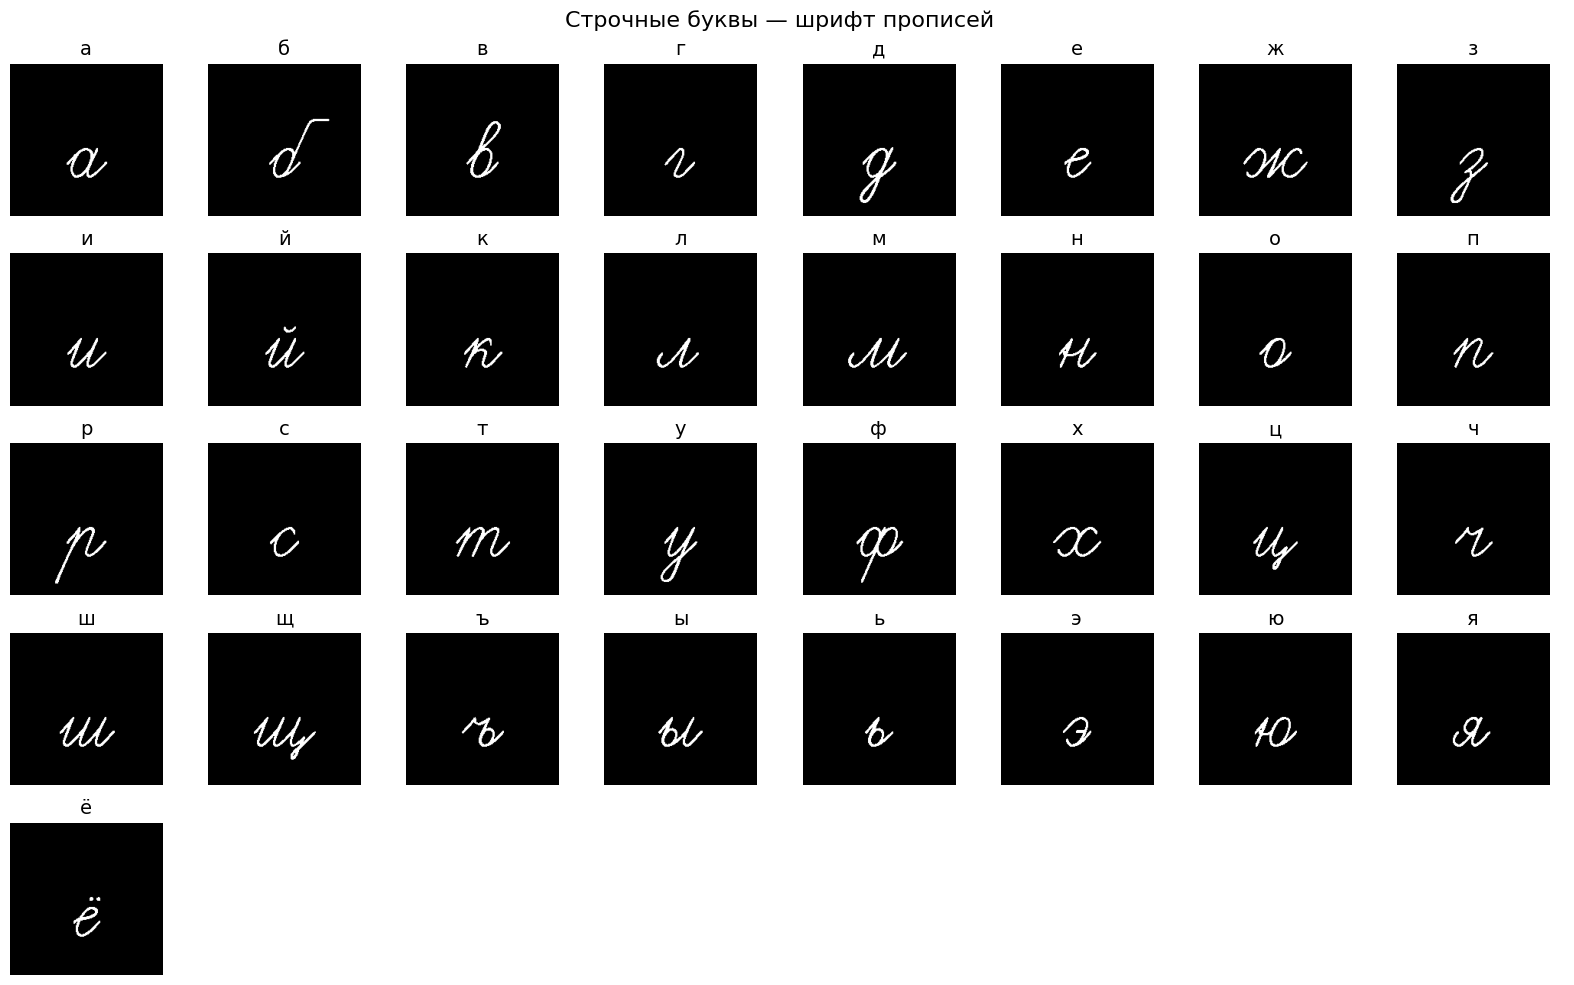

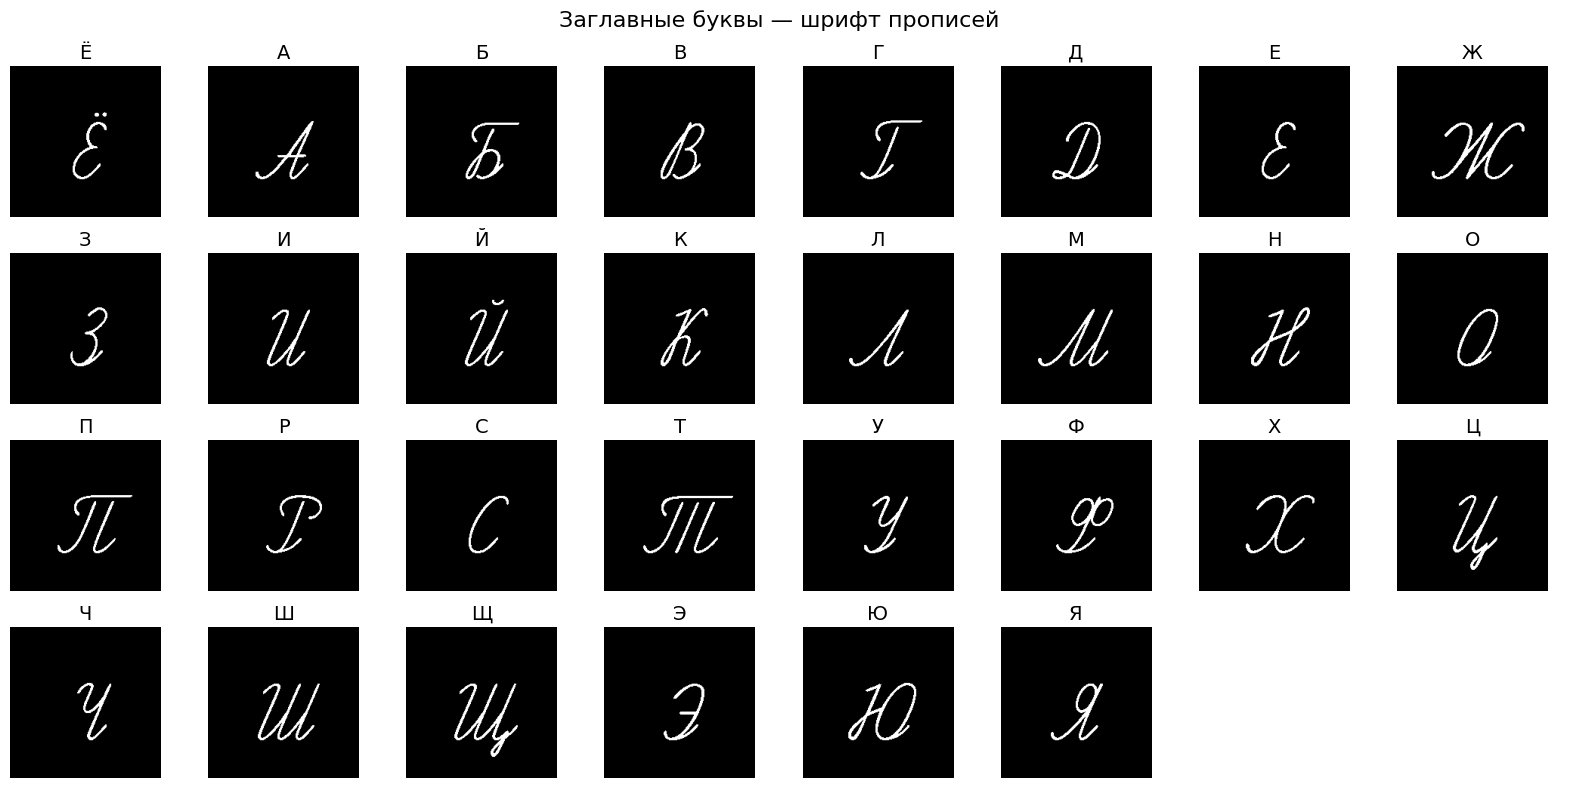

In [14]:

from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import math

# Выбранный шрифт
FONT_PATH = "/content/ofont.ru_Propisi.ttf"

# Единые параметры рендеринга
FONT_SIZE = 120
CANVAS_SIZE = (200, 200)
BASELINE_Y = 150
BACKGROUND = 255
FOREGROUND = 0

font = ImageFont.truetype(FONT_PATH, FONT_SIZE)

# Уникальные буквы отдельно по регистрам
letters_by_case = {
    case: sorted(
        letter_elements_df.loc[
            letter_elements_df["case"] == case, "letter"
        ].dropna().unique()
    )
    for case in ["lower", "upper"]
}

rendered_images = {}
rendered_bboxes = {}

for case, letters in letters_by_case.items():
    for letter in letters:
        image = Image.new("L", CANVAS_SIZE, BACKGROUND)
        draw = ImageDraw.Draw(image)


        draw.text(
            (CANVAS_SIZE[0] // 2, BASELINE_Y),
            letter,
            font=font,
            fill=FOREGROUND,
            anchor="ms"
        )

        bbox = image.getbbox()


        binary = image.point(lambda p: 255 if p < 128 else 0)

        rendered_images[(letter, case)] = binary
        rendered_bboxes[(letter, case)] = bbox

print("Рендеринг done.")
print("Строчных букв:", len(letters_by_case["lower"]))
print("Заглавных букв:", len(letters_by_case["upper"]))
print("Всего изображений:", len(rendered_images))
print("Размер каждого изображения:", CANVAS_SIZE)

for case, letters in letters_by_case.items():
    cols = 8
    rows = math.ceil(len(letters) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 2))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax in axes:
        ax.axis("off")

    for i, letter in enumerate(letters):
        ax = axes[i]
        ax.imshow(rendered_images[(letter, case)], cmap="gray", vmin=0, vmax=255)
        ax.set_title(letter, fontsize=14)
        ax.axis("off")

    plt.suptitle(
        "Строчные буквы — шрифт прописей"
        if case == "lower"
        else "Заглавные буквы — шрифт прописей",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()


Кол-во изображений: 63
Кол-во bounding boxes: 63

Размеры изображений:
{(200, 200)}

Проверка пустых изображений:
Пустых изображений нет.


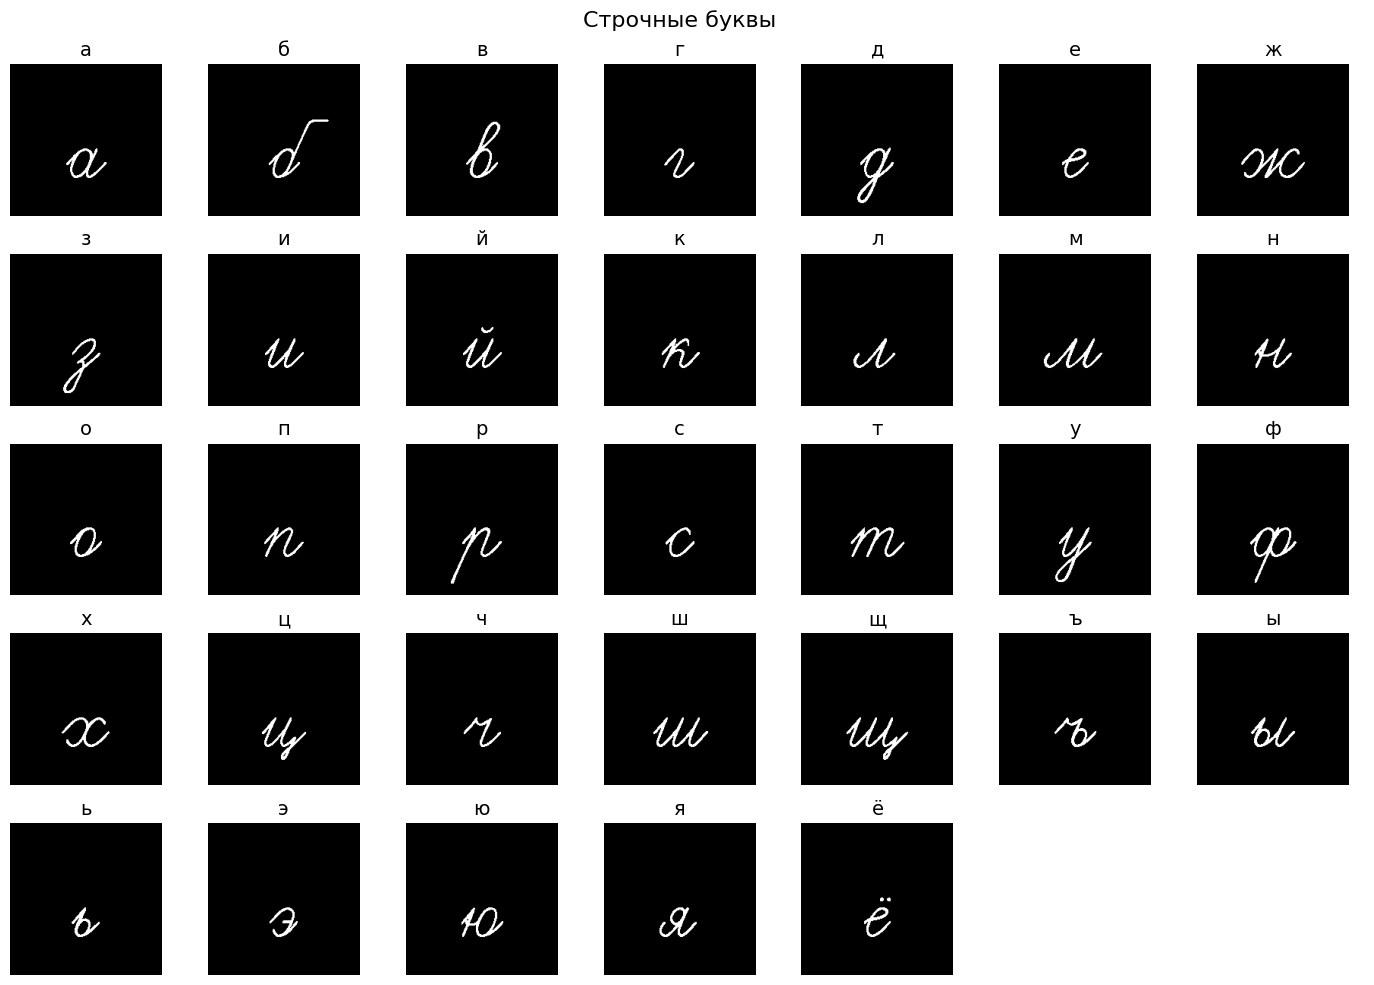

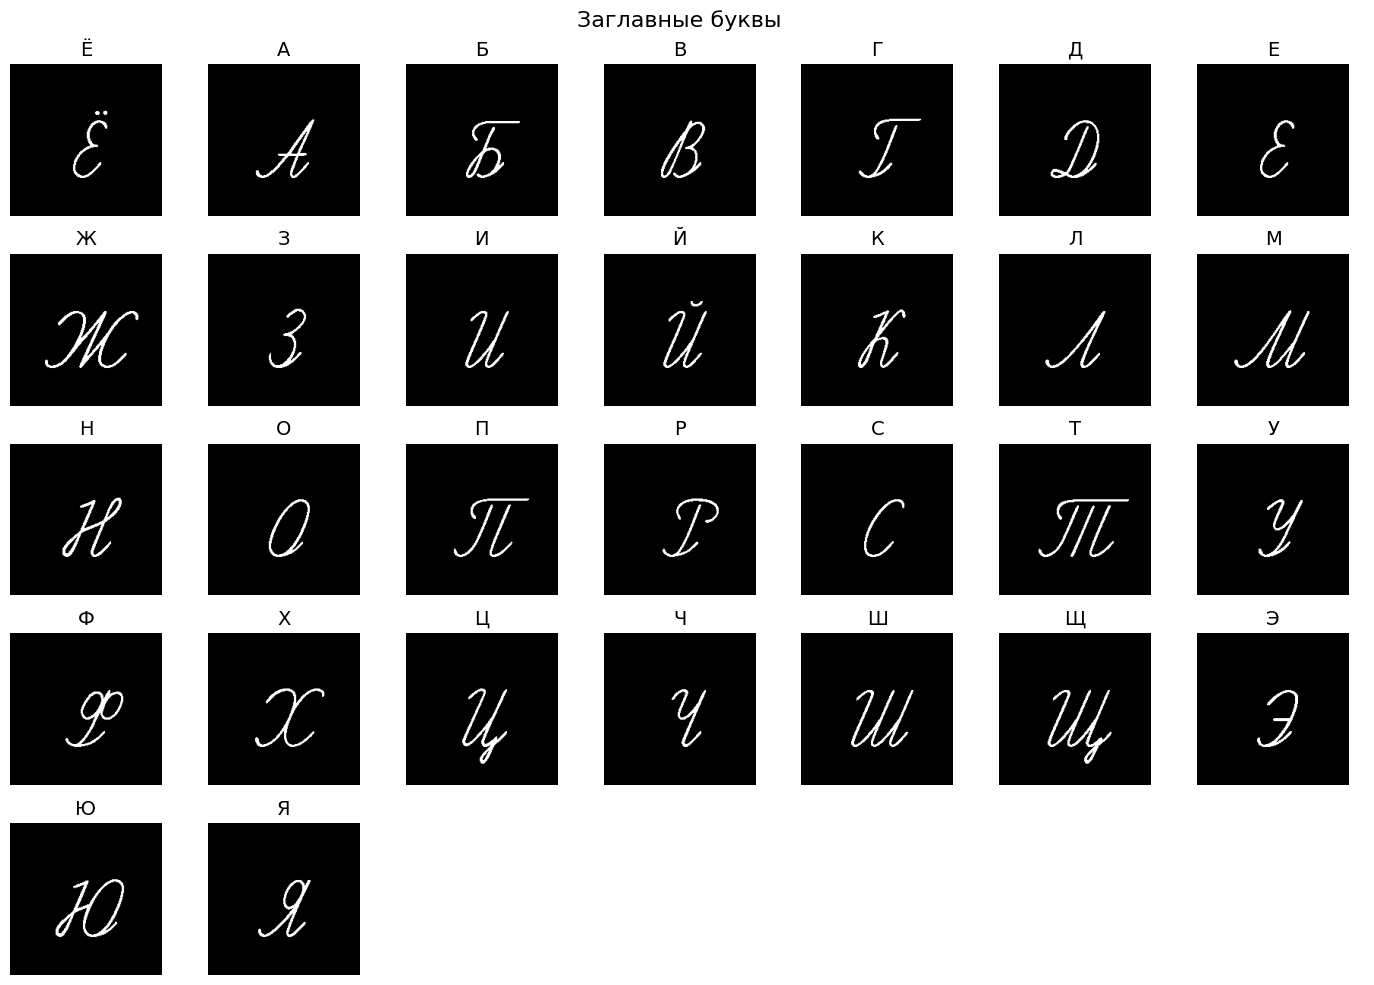

In [15]:

import numpy as np
import matplotlib.pyplot as plt

print("Кол-во изображений:", len(rendered_images))
print("Кол-во bounding boxes:", len(rendered_bboxes))

print("\nРазмеры изображений:")
print(set(img.size for img in rendered_images.values()))

print("\nПроверка пустых изображений:")
empty_letters = []

for key, img in rendered_images.items():
    if np.asarray(img).max() == np.asarray(img).min():
        empty_letters.append(key)

print(empty_letters if empty_letters else "Пустых изображений нет.")

#виз строчных и заглавных букв
for case in ["lower", "upper"]:
    items = [
        (key, img)
        for key, img in rendered_images.items()
        if key[1] == case
    ]

    cols = 7
    rows = (len(items) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 2))
    axes = np.array(axes).reshape(-1)

    for ax, (key, img) in zip(axes, items):
        ax.imshow(img, cmap="gray")
        ax.set_title(key[0], fontsize=14)
        ax.axis("off")

    for ax in axes[len(items):]:
        ax.axis("off")

    fig.suptitle(
        "Строчные буквы" if case == "lower" else "Заглавные буквы",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()


In [16]:
import numpy as np
import pandas as pd

pixel_stats = []

for (letter, case), img in rendered_images.items():
    arr = np.asarray(img.convert("L"))


    mask = arr > 128

    ys, xs = np.where(mask)

    if len(xs) == 0:
        print(f"ВНИМАНИЕ: буква {letter} ({case}) не обнаружена!")
        continue

    pixel_stats.append({
        "letter": letter,
        "case": case,
        "width": xs.max() - xs.min() + 1,
        "height": ys.max() - ys.min() + 1,
        "center_x": round(xs.mean(), 2),
        "center_y": round(ys.mean(), 2),
        "pixel_area": int(mask.sum())
    })

pixel_stats_df = pd.DataFrame(pixel_stats)

print("Размеры и положение букв:")
display(pixel_stats_df)

print("\nСредние показатели по регистрам:")
display(
    pixel_stats_df.groupby("case")[
        ["width", "height", "center_x", "center_y", "pixel_area"]
    ].mean().round(2)
)

Размеры и положение букв:


,letter,case,width,height,center_x,center_y,pixel_area
0,а,lower,53,39,97.96,130.89,555
1,б,lower,79,77,109.66,117.11,653
2,в,lower,45,74,102.45,116.15,783
3,г,lower,40,39,98.38,130.84,320
4,д,lower,48,73,95.27,142.79,857
5,е,lower,35,39,99.42,129.21,409
6,ж,lower,84,39,98.06,130.60,892
7,з,lower,49,72,93.16,145.88,624
8,и,lower,51,39,96.83,132.48,526
9,й,lower,51,54,97.78,128.96,592



Средние показатели по регистрам:


,width,height,center_x,center_y,pixel_area
case,,,,,
lower,54.36,48.21,97.97,131.83,601.58
upper,71.80,78.40,107.48,113.88,937.60


In [17]:
import numpy as np
import pandas as pd

bbox_data = []

for (letter, case), img in rendered_images.items():
    arr = np.asarray(img.convert("L"))
    mask = arr > 128
    ys, xs = np.where(mask)

    if len(xs) == 0:
        continue

    bbox_data.append({
        "letter": letter,
        "case": case,
        "x_min": xs.min(),
        "x_max": xs.max(),
        "y_min": ys.min(),
        "y_max": ys.max(),
        "width": xs.max() - xs.min() + 1,
        "height": ys.max() - ys.min() + 1
    })

bbox_df = pd.DataFrame(bbox_data)

print("Строчные буквы:")
display(
    bbox_df[bbox_df["case"] == "lower"]
    .sort_values("letter")
    .reset_index(drop=True)
)

print("Заглавные буквы:")
display(
    bbox_df[bbox_df["case"] == "upper"]
    .sort_values("letter")
    .reset_index(drop=True)
)

print("Диапазоны нижней границы букв:")
display(
    bbox_df.groupby("case")[["y_min", "y_max"]]
    .agg(["mean", "min", "max"])
    .round(2)
)

Строчные буквы:


,letter,case,x_min,x_max,y_min,y_max,width,height
0,а,lower,74,126,111,149,53,39
1,б,lower,80,158,73,149,79,77
2,в,lower,79,123,76,149,45,74
3,г,lower,79,118,111,149,40,39
4,д,lower,74,121,110,182,48,73
5,е,lower,83,117,111,149,35,39
6,ж,lower,58,141,111,149,84,39
7,з,lower,70,118,111,182,49,72
8,и,lower,75,125,111,149,51,39
9,й,lower,75,125,96,149,51,54


Заглавные буквы:


,letter,case,x_min,x_max,y_min,y_max,width,height
0,Ё,upper,83,127,61,149,45,89
1,А,upper,63,139,73,149,77,77
2,Б,upper,79,149,75,149,71,75
3,В,upper,75,132,74,149,58,76
4,Г,upper,76,157,72,149,82,78
5,Д,upper,68,131,74,149,64,76
6,Е,upper,83,127,74,149,45,76
7,Ж,upper,46,168,75,149,123,75
8,З,upper,80,128,72,149,49,78
9,И,upper,78,134,75,149,57,75


Диапазоны нижней границы букв:


y_min            y_max          
         mean min  max    mean  min  max
case                                    
lower  107.91  73  111  155.12  149  184
upper   73.07  61   75  150.47  149  171

In [18]:
import numpy as np
import pandas as pd
from itertools import combinations

#бинарные маски
binary_masks = {}

for key, img in rendered_images.items():
    arr = np.asarray(img.convert("L"))
    binary_masks[key] = arr > 128

iou_results = []

#Тут сравниваем отдельно строчные и заглавные
for case in ["lower", "upper"]:

    letters = sorted([
        key for key in binary_masks
        if key[1] == case
    ])

    for key1, key2 in combinations(letters, 2):

        mask1 = binary_masks[key1]
        mask2 = binary_masks[key2]

        intersection = np.logical_and(mask1, mask2).sum()
        union = np.logical_or(mask1, mask2).sum()

        iou = intersection / union if union else np.nan

        iou_results.append({
            "letter_1": key1[0],
            "letter_2": key2[0],
            "case": case,
            "intersection": int(intersection),
            "union": int(union),
            "IoU": round(float(iou), 5)
        })

iou_df = pd.DataFrame(iou_results)

print("Количество сравнений:", len(iou_df))
print("\nРаспределение по регистрам:")
display(iou_df.groupby("case")["IoU"].describe().round(5))

print("\n20 пар с наибольшим IoU:")
display(
    iou_df.sort_values("IoU", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

print("\n20 пар с наименьшим IoU:")
display(
    iou_df.sort_values("IoU", ascending=True)
    .head(20)
    .reset_index(drop=True)
)

Количество сравнений: 963

Распределение по регистрам:


,count,mean,std,min,25%,50%,75%,max
case,,,,,,,,
lower,528.0,0.16588,0.11727,0.03221,0.09026,0.12729,0.20122,0.90487
upper,435.0,0.11804,0.08611,0.02471,0.07014,0.10078,0.14212,0.91116



20 пар с наибольшим IoU:


,letter_1,letter_2,case,intersection,union,IoU
0,И,Й,upper,841,923,0.91116
1,Ё,Е,upper,514,567,0.90653
2,е,ё,lower,409,452,0.90487
3,и,й,lower,524,594,0.88215
4,А,Л,upper,629,979,0.64249
5,п,р,lower,444,724,0.61326
6,и,н,lower,394,650,0.60615
7,о,э,lower,320,558,0.57348
8,б,о,lower,404,718,0.56267
9,й,н,lower,397,713,0.55680



20 пар с наименьшим IoU:


,letter_1,letter_2,case,intersection,union,IoU
0,Ё,Ц,upper,41,1659,0.02471
1,Е,Ц,upper,41,1606,0.02553
2,С,Ю,upper,47,1783,0.02636
3,П,Ф,upper,56,1948,0.02875
4,С,Х,upper,42,1336,0.03144
5,О,Х,upper,51,1586,0.03216
6,ч,щ,lower,42,1304,0.03221
7,з,щ,lower,50,1539,0.03249
8,П,Ч,upper,53,1597,0.03319
9,Ё,А,upper,48,1376,0.03488


In [19]:
print("metadata_df:")
print(metadata_df.shape)
print(metadata_df.columns.tolist())

print("\ndirections_df:")
print(directions_df.shape)
print(directions_df.columns.tolist())

print("\nПример метаданных:")
display(metadata_df.head(5))

metadata_df:
(59, 20)
['letter', 'case_source', 'start_point_source', 'start_direction_source', 'elements_source', 'description_source', 'source_excel_row', 'case', 'start_point', 'start_direction', 'first_stroke', 'annotation_note', 'check_start_point', 'check_start_direction', 'check_description', 'check_first_stroke', 'start_direction_normalized', 'start_point_normalized', 'start_point_options', 'start_point_condition']

directions_df:
(59, 8)
['number', 'letter', 'case_source', 'start_point_source', 'start_direction_source', 'elements_source', 'description_source', 'source_excel_row']

Пример метаданных:


,letter,case_source,start_point_source,start_direction_source,elements_source,description_source,source_excel_row,case,start_point,start_direction,first_stroke,annotation_note,check_start_point,check_start_direction,check_description,check_first_stroke,start_direction_normalized,start_point_normalized,start_point_options,start_point_condition
0,а,строчная,Сверху,вверх влево,"овал, короткая прямая наклонная линия с закруглением","Начинаем писать ниже верхней линии рабочей строки, Ведем вверх, закругляя чуть влево, доводим до...",3,lower,Сверху,вверх влево,,,,,,,up_left,top,[top],
1,б,строчная,Снизу,вверх влево,овал,"Начинаем писать так же, как и буквы «о» и «а». Дойдя до начала письма, начинаем писать второй эл...",5,lower,Снизу,вверх влево,,,,,,,up_left,bottom,[bottom],
2,в,строчная,С середины,вверх с наклоном,NaN,"Начинаем писать с середины рабочей строки, ведем линию с наклоном вверх, делаем петлю, высотой д...",7,lower,С середины,вверх с наклоном,,,,,,,up_inclined,middle,[middle],
3,г,строчная,сверху,вверх вправо,NaN,"Начинаем писать чуть ниже верхней линии рабочей строки. Ведем вверх вправо, закругляя, доводим д...",9,lower,сверху,вверх вправо,,,,,,,up_right,top,[top],
4,д,строчная,С середины,вверх влево,NaN,"Первый элемент начинаем писать так же, как и букву «а». Второй элемент- прямая наклонная линия. ...",11,lower,С середины,вверх влево,,,,,,,up_left,middle,[middle],


In [20]:
import pandas as pd
import numpy as np


meta = metadata_df[[
    "letter",
    "case",
    "start_point_normalized",
    "start_point_options",
    "start_point_condition",
    "start_direction_normalized",
    "first_stroke"
]].copy()


#функция получения возможных начальных точек
def get_start_options(options, normalized):

    if isinstance(options, (list, tuple, set)):
        values = {str(x).strip() for x in options if pd.notna(x)}
    elif isinstance(options, str) and options.strip():
        values = {options.strip()}
    else:
        values = set()

    if not values and pd.notna(normalized):
        values = {str(normalized).strip()}

    values.discard("")
    return values


# Присоединяем метаданные первой буквы
combined_df = iou_df.merge(
    meta,
    left_on=["letter_1", "case"],
    right_on=["letter", "case"],
    how="left"
)

combined_df = combined_df.rename(columns={
    "start_point_normalized": "start_point_1",
    "start_point_options": "start_options_1",
    "start_point_condition": "start_condition_1",
    "start_direction_normalized": "direction_1",
    "first_stroke": "first_stroke_1"
}).drop(columns=["letter"])


#присоединяем метаданные второй буквы
combined_df = combined_df.merge(
    meta,
    left_on=["letter_2", "case"],
    right_on=["letter", "case"],
    how="left"
)

combined_df = combined_df.rename(columns={
    "start_point_normalized": "start_point_2",
    "start_point_options": "start_options_2",
    "start_point_condition": "start_condition_2",
    "start_direction_normalized": "direction_2",
    "first_stroke": "first_stroke_2"
}).drop(columns=["letter"])


#проверка совместимости начальных точек
def points_match(row):
    options_1 = get_start_options(
        row["start_options_1"], row["start_point_1"]
    )
    options_2 = get_start_options(
        row["start_options_2"], row["start_point_2"]
    )

    if not options_1 or not options_2:
        return False

    return bool(options_1 & options_2)


#проверяем совпадение направлений
def directions_match(row):
    d1 = row["direction_1"]
    d2 = row["direction_2"]

    if pd.isna(d1) or pd.isna(d2):
        return False

    return str(d1).strip() == str(d2).strip()


combined_df["start_point_match"] = combined_df.apply(
    points_match, axis=1
)

combined_df["direction_match"] = combined_df.apply(
    directions_match, axis=1
)

#наш кандидаты по двум моторным признакам
combined_df["motor_candidate"] = (
    combined_df["start_point_match"] &
    combined_df["direction_match"]
)



print("Размер объединенной таблицы:", combined_df.shape)

print("\nКоличество пар:")
print("Всего оптических сравнений:", len(combined_df))
print("Совпадают начальные точки:",
      combined_df["start_point_match"].sum())
print("Совпадают направления:",
      combined_df["direction_match"].sum())
print("Совпадают оба моторных признака:",
      combined_df["motor_candidate"].sum())

print("\nПары без полной моторной разметки:")
print(
    combined_df[
        combined_df["direction_1"].isna() |
        combined_df["direction_2"].isna() |
        combined_df["start_point_1"].isna() |
        combined_df["start_point_2"].isna()
    ][["letter_1", "letter_2", "case",
       "start_point_1", "direction_1",
       "start_point_2", "direction_2"]]
    .to_string(index=False)
)

print("\nнаши кандидаты по моторным признакам:")
display(
    combined_df[combined_df["motor_candidate"]]
    [["letter_1", "letter_2", "case",
      "start_point_1", "start_point_2",
      "direction_1", "direction_2", "IoU"]]
    .sort_values("IoU", ascending=False)
    .reset_index(drop=True)
)

Размер объединенной таблицы: (963, 19)

Количество пар:
Всего оптических сравнений: 963
Совпадают начальные точки: 495
Совпадают направления: 153
Совпадают оба моторных признака: 128

Пары без полной моторной разметки:
letter_1 letter_2  case start_point_1        direction_1 start_point_2        direction_2
       а        й lower           top            up_left           NaN                NaN
       а        ё lower           top            up_left           NaN                NaN
       б        й lower        bottom            up_left           NaN                NaN
       б        ё lower        bottom            up_left           NaN                NaN
       в        й lower        middle        up_inclined           NaN                NaN
       в        ё lower        middle        up_inclined           NaN                NaN
       г        й lower           top           up_right           NaN                NaN
       г        ё lower           top           up_right     

,letter_1,letter_2,case,start_point_1,start_point_2,direction_1,direction_2,IoU
0,А,Л,upper,bottom,bottom,down_right,down_right,0.64249
1,п,р,lower,top,top,down_inclined,down_inclined,0.61326
2,к,п,lower,top,top,down_inclined,down_inclined,0.50435
3,Г,Р,upper,middle,middle,down_inclined,down_inclined,0.41865
4,к,р,lower,top,top,down_inclined,down_inclined,0.38426
...,...,...,...,...,...,...,...,...
123,Ц,Ш,upper,middle,middle,up_right,up_right,0.04446
124,Ц,Щ,upper,middle,middle,up_right,up_right,0.04300
125,У,Ю,upper,middle,middle,up_right,up_right,0.03850
126,Ч,Щ,upper,middle,middle,up_right,up_right,0.03744


In [21]:
def classify_start_match(row):
    options_1 = get_start_options(
        row["start_options_1"], row["start_point_1"]
    )
    options_2 = get_start_options(
        row["start_options_2"], row["start_point_2"]
    )

    if not options_1 or not options_2:
        return "unknown"

    intersection = options_1 & options_2

    if not intersection:
        return "no_match"

    conditional_1 = pd.notna(row["start_condition_1"]) and bool(
        str(row["start_condition_1"]).strip()
    )
    conditional_2 = pd.notna(row["start_condition_2"]) and bool(
        str(row["start_condition_2"]).strip()
    )

    if (
        len(options_1) == 1
        and len(options_2) == 1
        and not conditional_1
        and not conditional_2
    ):
        return "definite"

    return "possible"


combined_df["start_match_type"] = combined_df.apply(
    classify_start_match, axis=1
)

#совпадение направления остается обязательным
combined_df["motor_match_type"] = np.where(
    ~combined_df["direction_match"],
    "no_match",
    combined_df["start_match_type"]
)

print("Распределение совпадений:")
display(
    combined_df["motor_match_type"]
    .value_counts(dropna=False)
    .rename_axis("match_type")
    .to_frame("count")
)

#определенные уже моторные совпадения
definite_candidates = combined_df[
    combined_df["motor_match_type"] == "definite"
].copy()

#возможные моторные совпадения
possible_candidates = combined_df[
    combined_df["motor_match_type"] == "possible"
].copy()

print("\nОпределённые совпадения:")
display(
    definite_candidates[
        ["letter_1", "letter_2", "case",
         "start_point_1", "start_point_2",
         "direction_1", "direction_2", "IoU"]
    ].sort_values("IoU", ascending=False)
)

print("\nСовпадения с условными начальными точками:")
display(
    possible_candidates[
        ["letter_1", "letter_2", "case",
         "start_options_1", "start_options_2",
         "start_condition_1", "start_condition_2",
         "direction_1", "direction_2", "IoU"]
    ].sort_values("IoU", ascending=False)
)

Распределение совпадений:


,count
match_type,
no_match,835
definite,125
possible,3



Определённые совпадения:


,letter_1,letter_2,case,start_point_1,start_point_2,direction_1,direction_2,IoU
567,А,Л,upper,bottom,bottom,down_right,down_right,0.64249
375,п,р,lower,top,top,down_inclined,down_inclined,0.61326
279,к,п,lower,top,top,down_inclined,down_inclined,0.50435
650,Г,Р,upper,middle,middle,down_inclined,down_inclined,0.41865
280,к,р,lower,top,top,down_inclined,down_inclined,0.38426
...,...,...,...,...,...,...,...,...
943,Ц,Ш,upper,middle,middle,up_right,up_right,0.04446
944,Ц,Щ,upper,middle,middle,up_right,up_right,0.04300
925,У,Ю,upper,middle,middle,up_right,up_right,0.03850
949,Ч,Щ,upper,middle,middle,up_right,up_right,0.03744



Совпадения с условными начальными точками:


,letter_1,letter_2,case,start_options_1,start_options_2,start_condition_1,start_condition_2,direction_1,direction_2,IoU
373,о,я,lower,"[bottom, top]",[bottom],connection-dependent,,down_right,down_right,0.20452
319,м,о,lower,[bottom],"[bottom, top]",,connection-dependent,down_right,down_right,0.16371
299,л,о,lower,[bottom],"[bottom, top]",,connection-dependent,down_right,down_right,0.06774


In [22]:
import pandas as pd
import numpy as np

def classify_motor_pair(row):

    #тут получаем возможные начальные точки
    opts1 = get_start_options(
        row["start_options_1"], row["start_point_1"]
    )
    opts2 = get_start_options(
        row["start_options_2"], row["start_point_2"]
    )

    d1 = row["direction_1"]
    d2 = row["direction_2"]

    #если отсутствует хотя бы один обязательный признак
    if (
        not opts1 or not opts2
        or pd.isna(d1) or pd.isna(d2)
        or not str(d1).strip() or not str(d2).strip()
    ):
        return "unknown"

    #если направления различаются
    if str(d1).strip() != str(d2).strip():
        return "no_match"

    #если начальные точки не имеют общих вариантов
    intersection = opts1 & opts2

    if not intersection:
        return "no_match"

    #проверяем условность начальных точек
    condition1 = row["start_condition_1"]
    condition2 = row["start_condition_2"]

    conditional1 = (
        pd.notna(condition1)
        and bool(str(condition1).strip())
    )
    conditional2 = (
        pd.notna(condition2)
        and bool(str(condition2).strip())
    )

    if (
        len(opts1) == 1
        and len(opts2) == 1
        and not conditional1
        and not conditional2
    ):
        return "definite"

    return "possible"


combined_df["motor_match_type"] = combined_df.apply(
    classify_motor_pair, axis=1
)

#общая статистика
summary = (
    combined_df["motor_match_type"]
    .value_counts()
    .reindex(
        ["definite", "possible", "no_match", "unknown"],
        fill_value=0
    )
    .to_frame("count")
)

summary["percentage"] = (
    summary["count"] / len(combined_df) * 100
).round(2)

print("Классификация всех пар:")
display(summary)

#отделтн по регистрам
print("\nРаспределение по регистрам:")
display(
    pd.crosstab(
        combined_df["case"],
        combined_df["motor_match_type"]
    )
)

#состав пар с неизвестными моторными данными
unknown_pairs = combined_df[
    combined_df["motor_match_type"] == "unknown"
]

print("\nКоличество пар с неизвестными данными:",
      len(unknown_pairs))

print("\nКакие буквы встречаются в таких парах:")
unknown_letters = pd.concat([
    unknown_pairs["letter_1"],
    unknown_pairs["letter_2"]
]).value_counts()

display(unknown_letters.to_frame("unknown_pair_count"))

#проверяем кандидатов
definite_candidates = combined_df[
    combined_df["motor_match_type"] == "definite"
].copy()

possible_candidates = combined_df[
    combined_df["motor_match_type"] == "possible"
].copy()

print("\nЧисло определённых кандидатов:", len(definite_candidates))
print("Число возможных кандидатов:", len(possible_candidates))

Классификация всех пар:


,count,percentage
motor_match_type,,
definite,125,12.98
possible,3,0.31
no_match,685,71.13
unknown,150,15.58



Распределение по регистрам:


motor_match_type,definite,no_match,possible,unknown
case,,,,
lower,31,401,3,93
upper,94,284,0,57



Количество пар с неизвестными данными: 150

Какие буквы встречаются в таких парах:


,unknown_pair_count
й,32
ф,32
ё,32
Ё,29
Й,29
г,3
б,3
ж,3
з,3
и,3



Число определённых кандидатов: 125
Число возможных кандидатов: 3


In [23]:
import pandas as pd
import numpy as np

#1.Общая статистика IoU по категориям
iou_by_motor = (
    combined_df
    .groupby("motor_match_type")["IoU"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        min="min",
        q25=lambda x: x.quantile(0.25),
        median="median",
        q75=lambda x: x.quantile(0.75),
        max="max"
    )
    .reindex(["definite", "possible", "no_match", "unknown"])
    .round(4)
)

print("Оптическое сходство (IoU) по категориям моторного сравнения:")
display(iou_by_motor)

#2.Отдельно по регистрам
iou_by_case = (
    combined_df
    .groupby(["case", "motor_match_type"])["IoU"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .round(4)
)

print("IoU по категориям и регистрам:")
display(iou_by_case)

#3.Все определенные моторные совпадения
definite_pairs = (
    combined_df[combined_df["motor_match_type"] == "definite"]
    [["letter_1", "letter_2", "case", "IoU",
      "start_point_1", "direction_1"]]
    .sort_values("IoU", ascending=False)
)

print("125 определённых моторных совпадений:")
display(definite_pairs)

#4.Три условных совпадения
possible_pairs = (
    combined_df[combined_df["motor_match_type"] == "possible"]
    [["letter_1", "letter_2", "case", "IoU",
      "start_point_1", "direction_1",
      "start_condition_1", "start_condition_2"]]
    .sort_values("IoU", ascending=False)
)

print("Условные совпадения:")
display(possible_pairs)

Оптическое сходство (IoU) по категориям моторного сравнения:


,count,mean,std,min,q25,median,q75,max
motor_match_type,,,,,,,,
definite,125,0.1320,0.1018,0.0351,0.0726,0.1049,0.1473,0.6425
possible,3,0.1453,0.0702,0.0677,0.1157,0.1637,0.1841,0.2045
no_match,685,0.1424,0.0941,0.0255,0.0802,0.1154,0.1715,0.6062
unknown,150,0.1631,0.1550,0.0247,0.0829,0.1184,0.1723,0.9112


IoU по категориям и регистрам:


count    mean  median     q25     q75
case  motor_match_type                                       
lower definite             31  0.1637  0.1134  0.0957  0.1527
      no_match            401  0.1626  0.1276  0.0884  0.2016
      possible              3  0.1453  0.1637  0.1157  0.1841
      unknown              93  0.1815  0.1345  0.0974  0.2006
upper definite             94  0.1216  0.1036  0.0694  0.1395
      no_match            284  0.1139  0.1006  0.0720  0.1460
      unknown              57  0.1330  0.0990  0.0638  0.1301

125 определённых моторных совпадений:


,letter_1,letter_2,case,IoU,start_point_1,direction_1
567,А,Л,upper,0.64249,bottom,down_right
375,п,р,lower,0.61326,top,down_inclined
279,к,п,lower,0.50435,top,down_inclined
650,Г,Р,upper,0.41865,middle,down_inclined
280,к,р,lower,0.38426,top,down_inclined
...,...,...,...,...,...,...
943,Ц,Ш,upper,0.04446,middle,up_right
944,Ц,Щ,upper,0.04300,middle,up_right
925,У,Ю,upper,0.03850,middle,up_right
949,Ч,Щ,upper,0.03744,middle,up_right


Условные совпадения:


,letter_1,letter_2,case,IoU,start_point_1,direction_1,start_condition_1,start_condition_2
373,о,я,lower,0.20452,conditional,down_right,connection-dependent,
319,м,о,lower,0.16371,bottom,down_right,,connection-dependent
299,л,о,lower,0.06774,bottom,down_right,,connection-dependent


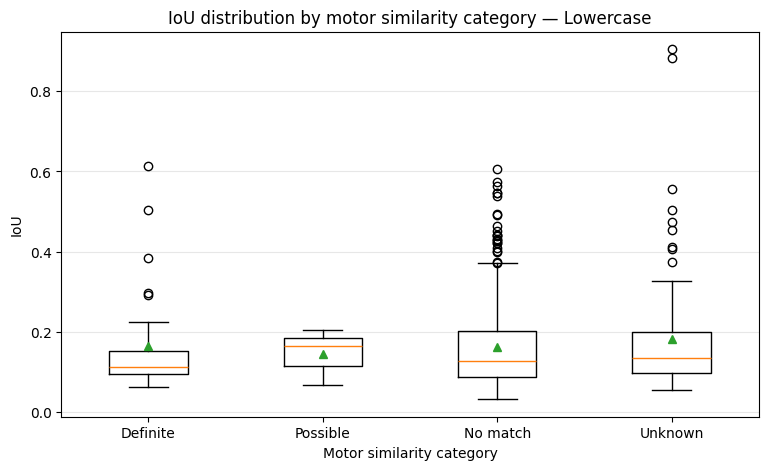

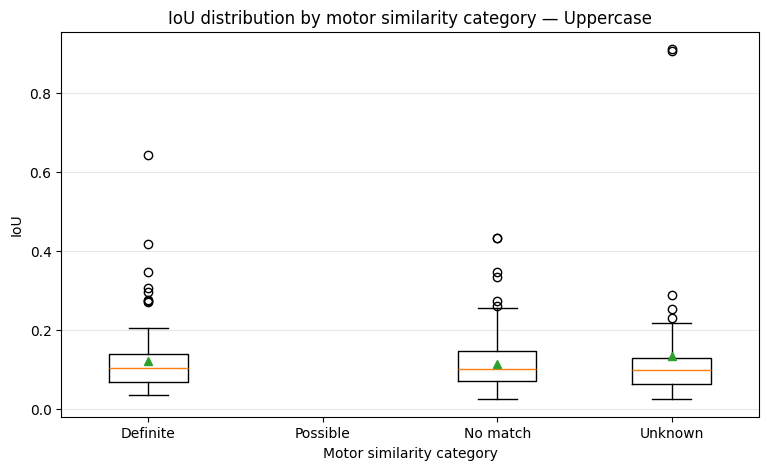

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

category_order = ["definite", "possible", "no_match", "unknown"]
category_labels = ["Definite", "Possible", "No match", "Unknown"]

for case_name, case_label in [
    ("lower", "Lowercase"),
    ("upper", "Uppercase")
]:
    subset = combined_df[combined_df["case"] == case_name]

    data = [
        subset.loc[
            subset["motor_match_type"] == category,
            "IoU"
        ].dropna()
        for category in category_order
    ]

    plt.figure(figsize=(9, 5))
    plt.boxplot(
        data,
        tick_labels=category_labels,
        showmeans=True
    )
    plt.title(f"IoU distribution by motor similarity category — {case_label}")
    plt.xlabel("Motor similarity category")
    plt.ylabel("IoU")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

In [25]:
for case_name, case_label in [
    ("lower", "Нижний регистр"),
    ("upper", "Верхний регистр")
]:
    print(f"\n{case_label}:")

    top_pairs = (
        combined_df[combined_df["case"] == case_name]
        .sort_values("IoU", ascending=False)
        [[
            "letter_1",
            "letter_2",
            "IoU",
            "motor_match_type",
            "start_point_1",
            "direction_1"
        ]]
        .head(20)
        .reset_index(drop=True)
    )

    display(top_pairs)


Нижний регистр:


,letter_1,letter_2,IoU,motor_match_type,start_point_1,direction_1
0,е,ё,0.90487,unknown,middle,up_inclined_right
1,и,й,0.88215,unknown,top,down
2,п,р,0.61326,definite,top,down_inclined
3,и,н,0.60615,no_match,top,down
4,о,э,0.57348,no_match,conditional,down_right
5,б,о,0.56267,no_match,bottom,up_left
6,й,н,0.55680,unknown,NaN,NaN
7,е,с,0.54752,no_match,middle,up_inclined_right
8,д,у,0.54673,no_match,middle,up_left
9,в,о,0.53998,no_match,middle,up_inclined



Верхний регистр:


,letter_1,letter_2,IoU,motor_match_type,start_point_1,direction_1
0,И,Й,0.91116,unknown,middle,up_right
1,Ё,Е,0.90653,unknown,NaN,NaN
2,А,Л,0.64249,definite,bottom,down_right
3,Ч,Я,0.43379,no_match,middle,up_right
4,М,Ш,0.43205,no_match,bottom,down_right
5,Г,Р,0.41865,definite,middle,down_inclined
6,О,Э,0.34791,no_match,middle,down_right
7,Ш,Щ,0.34778,definite,middle,up_right
8,Б,Д,0.33520,no_match,middle,down_left
9,И,Ч,0.30756,definite,middle,up_right


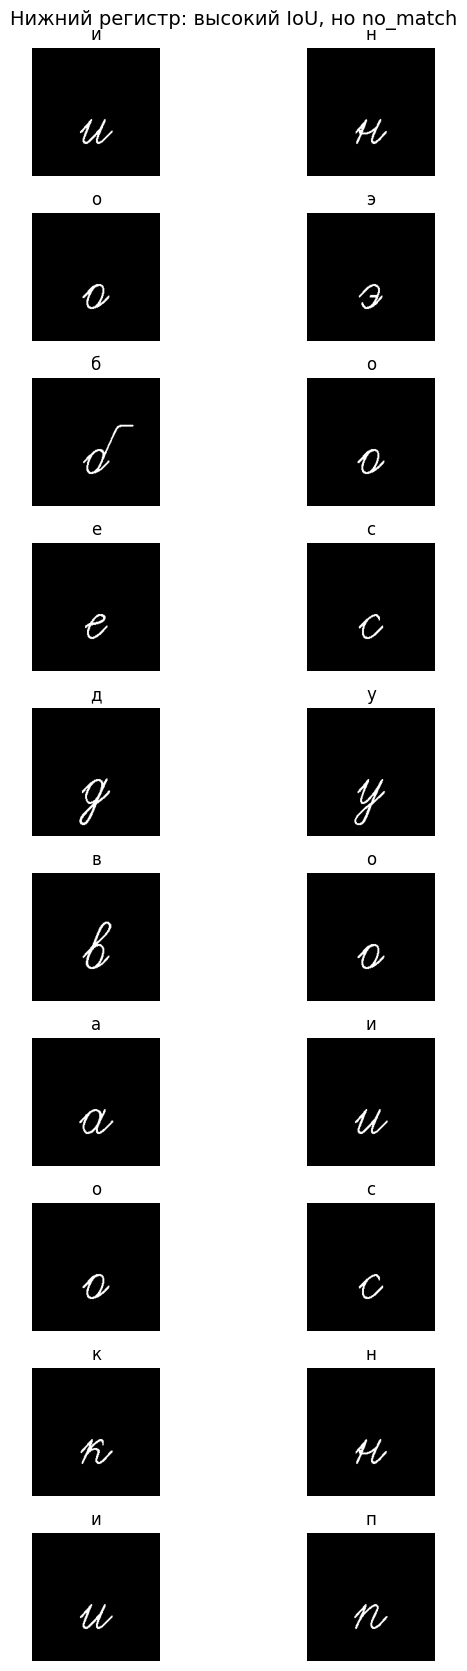

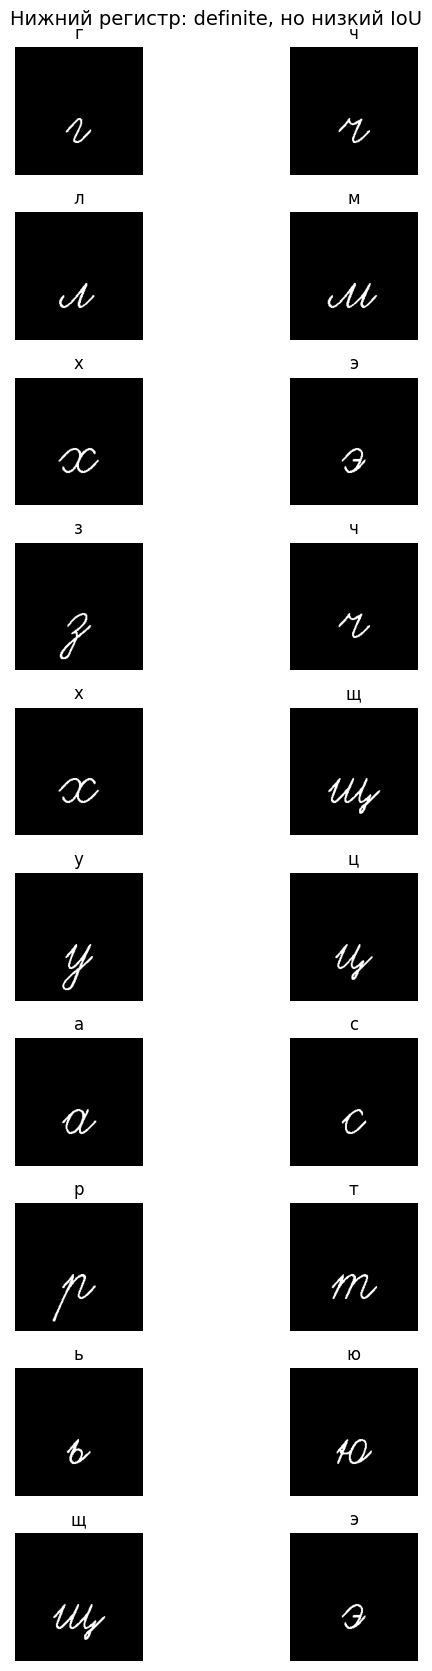

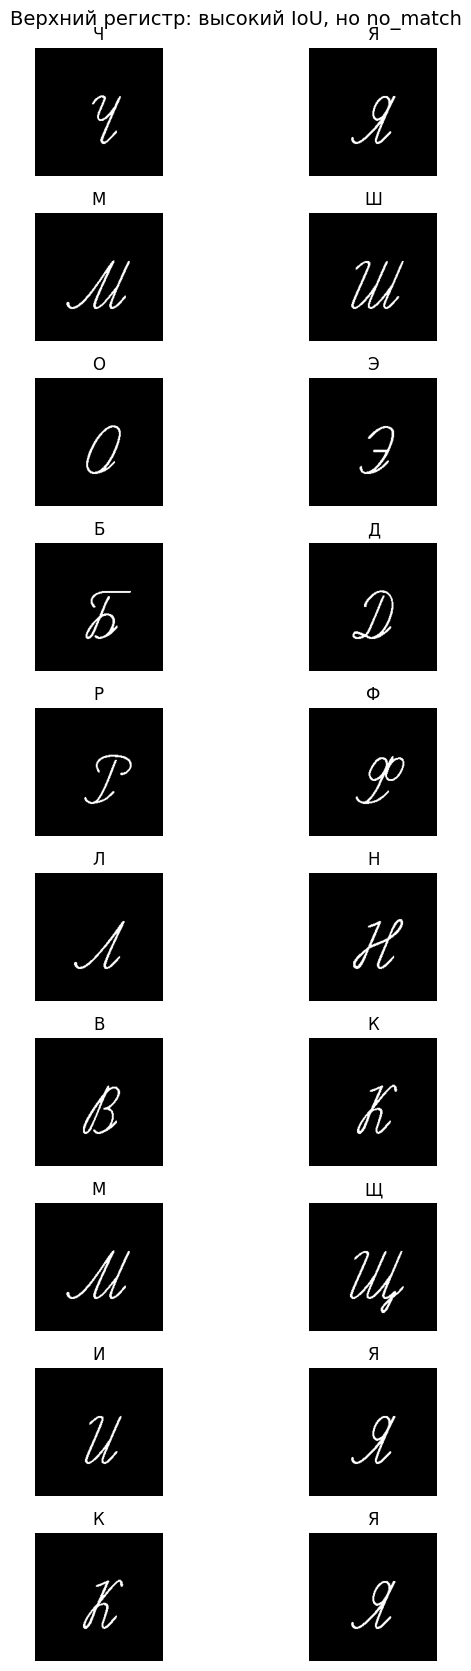

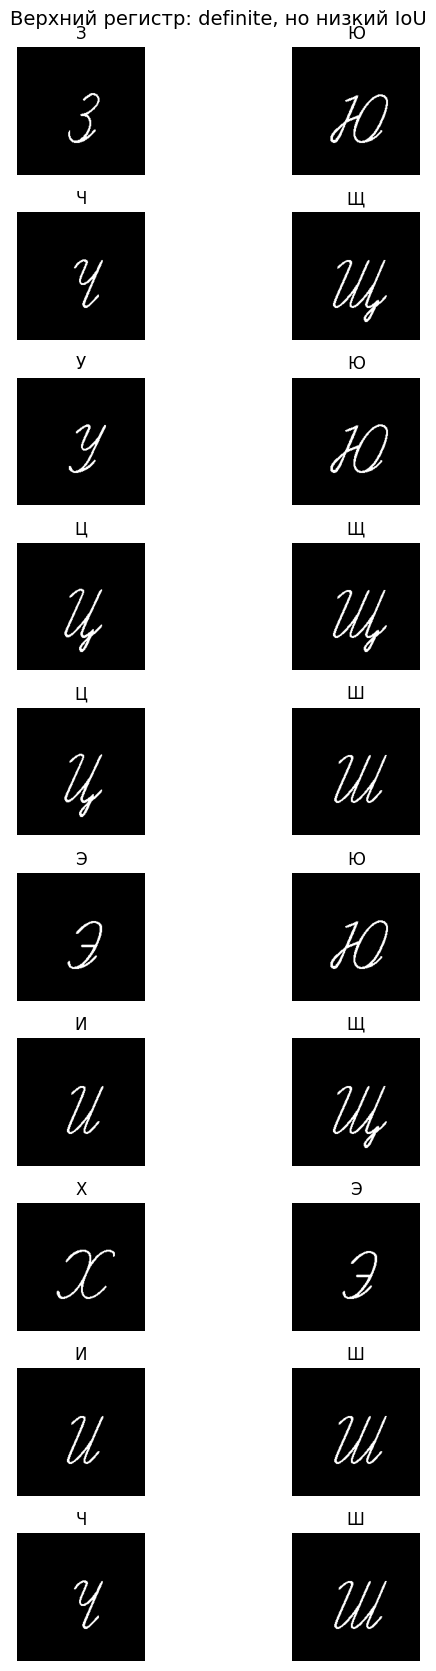

In [26]:
import matplotlib.pyplot as plt

def show_pair_montage(df, title, n=10):
    df = df.head(n)

    if df.empty:
        print(f"Нет пар для категории: {title}")
        return

    fig, axes = plt.subplots(
        len(df), 2,
        figsize=(7, max(2, len(df) * 1.7))
    )

    if len(df) == 1:
        axes = [axes]

    fig.suptitle(title, fontsize=14)

    for ax_row, (_, row) in zip(axes, df.iterrows()):
        key1 = (row["letter_1"], row["case"])
        key2 = (row["letter_2"], row["case"])

        ax1, ax2 = ax_row

        ax1.imshow(rendered_images[key1], cmap="gray")
        ax2.imshow(rendered_images[key2], cmap="gray")

        ax1.set_title(str(row["letter_1"]))
        ax2.set_title(str(row["letter_2"]))

        ax1.axis("off")
        ax2.axis("off")

        ax1.set_ylabel(
            f"IoU={row['IoU']:.3f}\n"
            f"{row['motor_match_type']}",
            rotation=0,
            labelpad=45,
            va="center"
        )

    plt.tight_layout()
    plt.show()


for case_name, case_label in [
    ("lower", "Нижний регистр"),
    ("upper", "Верхний регистр")
]:
    subset = combined_df[combined_df["case"] == case_name]

    #Высокое оптическое сходство, но моторного совпадения нет
    high_iou_no_match = (
        subset[subset["motor_match_type"] == "no_match"]
        .sort_values("IoU", ascending=False)
    )

    #Моторное совпадение, но низкое оптическое сходство
    low_iou_definite = (
        subset[subset["motor_match_type"] == "definite"]
        .sort_values("IoU", ascending=True)
    )

    show_pair_montage(
        high_iou_no_match,
        f"{case_label}: высокий IoU, но no_match"
    )

    show_pair_montage(
        low_iou_definite,
        f"{case_label}: definite, но низкий IoU"
    )

Количество определённых моторных кандидатов: 125
Количество условных кандидатов: 3
Анализ чувствительности алгоритма A:


,IoU_threshold,total_pairs,lower_pairs,upper_pairs,share_of_definite_candidates
0,0.05,115,31,84,92.0
1,0.10,70,21,49,56.0
2,0.15,29,8,21,23.2
3,0.20,17,6,11,13.6
4,0.25,13,5,8,10.4
5,0.30,7,3,4,5.6
6,0.35,5,3,2,4.0
7,0.40,4,2,2,3.2
8,0.45,3,2,1,2.4
9,0.50,3,2,1,2.4


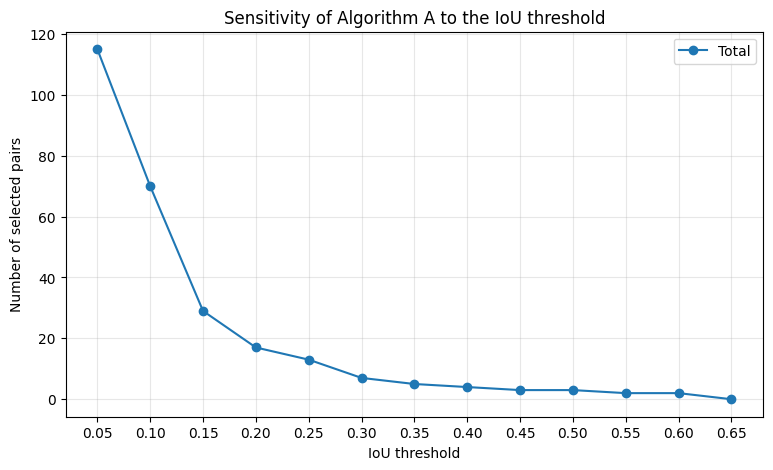

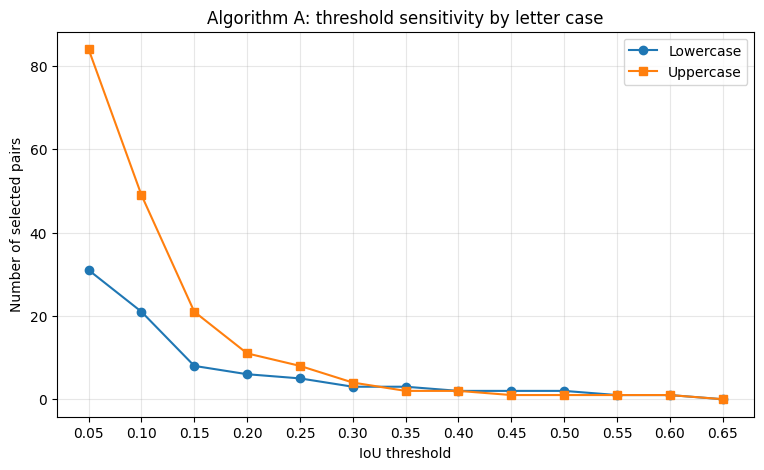


Порог IoU >= 0.05: 115 пар


,letter_1,letter_2,case,IoU
0,А,Л,upper,0.64249
1,п,р,lower,0.61326
2,к,п,lower,0.50435
3,Г,Р,upper,0.41865
4,к,р,lower,0.38426
...,...,...,...,...
110,Ч,Ю,upper,0.05683
111,Л,М,upper,0.05552
112,У,Ш,upper,0.05455
113,У,Щ,upper,0.05356



Порог IoU >= 0.10: 70 пар


,letter_1,letter_2,case,IoU
0,А,Л,upper,0.64249
1,п,р,lower,0.61326
2,к,п,lower,0.50435
3,Г,Р,upper,0.41865
4,к,р,lower,0.38426
5,Ш,Щ,upper,0.34778
6,И,Ч,upper,0.30756
7,У,Э,upper,0.29753
8,л,я,lower,0.29677
9,ж,щ,lower,0.29318



Порог IoU >= 0.15: 29 пар


,letter_1,letter_2,case,IoU
0,А,Л,upper,0.64249
1,п,р,lower,0.61326
2,к,п,lower,0.50435
3,Г,Р,upper,0.41865
4,к,р,lower,0.38426
5,Ш,Щ,upper,0.34778
6,И,Ч,upper,0.30756
7,У,Э,upper,0.29753
8,л,я,lower,0.29677
9,ж,щ,lower,0.29318


... (17 outputs left out)

,letter_1,letter_2,case,IoU
0,А,Л,upper,0.64249
1,п,р,lower,0.61326



Порог IoU >= 0.65: 0 пар


,letter_1,letter_2,case,IoU


Таблица сохранена: iou_threshold_sensitivity.csv


In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


required_columns = {"IoU", "motor_match_type", "case", "letter_1", "letter_2"}
missing_columns = required_columns - set(combined_df.columns)

if missing_columns:
    raise ValueError(f"В combined_df отсутствуют столбцы: {missing_columns}")

#1.Формируем набор определенных моторных совпадений
definite_df = combined_df[
    combined_df["motor_match_type"] == "definite"
].copy()

print("Количество определённых моторных кандидатов:", len(definite_df))

#Возможные совпадения сохр отдельно
possible_df = combined_df[
    combined_df["motor_match_type"] == "possible"
].copy()

print("Количество условных кандидатов:", len(possible_df))

#2.Задаем диапазон порогов IoU
thresholds = np.round(np.arange(0.05, 0.651, 0.05), 2)

#3.Рассчитываем результаты для каждого порога
results = []

for threshold in thresholds:
    selected = definite_df[definite_df["IoU"] >= threshold]

    lower_count = (selected["case"] == "lower").sum()
    upper_count = (selected["case"] == "upper").sum()

    results.append({
        "IoU_threshold": threshold,
        "total_pairs": len(selected),
        "lower_pairs": lower_count,
        "upper_pairs": upper_count,
        "share_of_definite_candidates": (
            len(selected) / len(definite_df) * 100
            if len(definite_df) else 0
        )
    })

sensitivity_df = pd.DataFrame(results)

print("Анализ чувствительности алгоритма A:")
display(sensitivity_df.round(2))

#Строим график общего количества отобранных пар
plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df["IoU_threshold"],
    sensitivity_df["total_pairs"],
    marker="o",
    label="Total"
)

plt.xlabel("IoU threshold")
plt.ylabel("Number of selected pairs")
plt.title("Sensitivity of Algorithm A to the IoU threshold")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

#Сравниваем регистры
plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df["IoU_threshold"],
    sensitivity_df["lower_pairs"],
    marker="o",
    label="Lowercase"
)

plt.plot(
    sensitivity_df["IoU_threshold"],
    sensitivity_df["upper_pairs"],
    marker="s",
    label="Uppercase"
)

plt.xlabel("IoU threshold")
plt.ylabel("Number of selected pairs")
plt.title("Algorithm A: threshold sensitivity by letter case")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

#Показываем пары для каждого порога
for threshold in thresholds:
    selected = (
        definite_df[definite_df["IoU"] >= threshold]
        [["letter_1", "letter_2", "case", "IoU"]]
        .sort_values("IoU", ascending=False)
    )

    print(f"\nПорог IoU >= {threshold:.2f}: {len(selected)} пар")
    display(selected.reset_index(drop=True))

#таблица для анализа чувствительности
sensitivity_df.to_csv(
    "iou_threshold_sensitivity.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Таблица сохранена: iou_threshold_sensitivity.csv")


In [28]:
import pandas as pd

#Пороги, которые проверили в анализе чувствительности
iou_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65
]

#Только определкнные моторные кандидаты
definite_candidates = combined_df[
    combined_df["motor_match_type"] == "definite"
].copy()

#условные кандидаты - отдельно
possible_candidates = combined_df[
    combined_df["motor_match_type"] == "possible"
].copy()

#Результаты алгоритма A для каждого порога
algorithm_A_results = {}
sensitivity_rows = []

for threshold in iou_thresholds:
    selected = definite_candidates[
        definite_candidates["IoU"] >= threshold
    ].copy()

    selected = selected.sort_values("IoU", ascending=False)

    algorithm_A_results[threshold] = selected

    sensitivity_rows.append({
        "IoU_threshold": threshold,
        "total_pairs": len(selected),
        "lower_pairs": (selected["case"] == "lower").sum(),
        "upper_pairs": (selected["case"] == "upper").sum(),
        "share_of_definite_candidates": round(
            len(selected) / len(definite_candidates) * 100, 2
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)

print("АЛГОРИТМ B: уже определенные моторные кандидаты")
print("Количество:", len(definite_candidates))

print("\nУсловные моторные кандидаты:")
print("Количество:", len(possible_candidates))
display(
    possible_candidates[
        ["letter_1", "letter_2", "case", "IoU"]
    ].sort_values("IoU", ascending=False)
)

print("\nЧУВСТВИТЕЛЬНОСТЬ АЛГОРИТМА A")
display(sensitivity_df)

#Сохр таблицу чувствительности
sensitivity_df.to_csv(
    "algorithm_A_sensitivity.csv",
    index=False,
    encoding="utf-8-sig"
)

#Сохр полный набор уже определенных моторных кандидатов
definite_candidates.to_csv(
    "algorithm_B_definite_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

#сохраняем результаты алгоритма A для каждого порога
for threshold, result in algorithm_A_results.items():
    filename = f"algorithm_A_iou_{threshold:.2f}.csv"
    result.to_csv(filename, index=False, encoding="utf-8-sig")

print("\nТаблицы сохранены.")

АЛГОРИТМ B: уже определенные моторные кандидаты
Количество: 125

Условные моторные кандидаты:
Количество: 3


,letter_1,letter_2,case,IoU
373,о,я,lower,0.20452
319,м,о,lower,0.16371
299,л,о,lower,0.06774



ЧУВСТВИТЕЛЬНОСТЬ АЛГОРИТМА A


,IoU_threshold,total_pairs,lower_pairs,upper_pairs,share_of_definite_candidates
0,0.05,115,31,84,92.0
1,0.10,70,21,49,56.0
2,0.15,29,8,21,23.2
3,0.20,17,6,11,13.6
4,0.25,13,5,8,10.4
5,0.30,7,3,4,5.6
6,0.35,5,3,2,4.0
7,0.40,4,2,2,3.2
8,0.45,3,2,1,2.4
9,0.50,3,2,1,2.4



Таблицы сохранены.


In [29]:
#ФИН!!!

print("АЛГОРИТМ B")
print("Определенные кандидаты:",
      len(combined_df[combined_df["motor_match_type"] == "definite"]))

print("Условные кандидаты:",
      len(combined_df[combined_df["motor_match_type"] == "possible"]))

print("\nАЛГОРИТМ A")
print(sensitivity_df.to_string(index=False))

print("\nПРОВЕРКА ДУБЛИКАТОВ")

definite = combined_df[
    combined_df["motor_match_type"] == "definite"
].copy()

definite["pair_id"] = definite.apply(
    lambda row: tuple(sorted([row["letter_1"], row["letter_2"]])),
    axis=1
)

print("Всего определенных кандидатов:", len(definite))
print("Уникальных пар:", definite["pair_id"].nunique())
print("Дубликатов:", definite["pair_id"].duplicated().sum())

print("\nРАСПРЕДЕЛЕНИЕ ПО РЕГИСТРАМ")
print(definite["case"].value_counts())

АЛГОРИТМ B
Определенные кандидаты: 125
Условные кандидаты: 3

АЛГОРИТМ A
 IoU_threshold  total_pairs  lower_pairs  upper_pairs  share_of_definite_candidates
          0.05          115           31           84                          92.0
          0.10           70           21           49                          56.0
          0.15           29            8           21                          23.2
          0.20           17            6           11                          13.6
          0.25           13            5            8                          10.4
          0.30            7            3            4                           5.6
          0.35            5            3            2                           4.0
          0.40            4            2            2                           3.2
          0.45            3            2            1                           2.4
          0.50            3            2            1                           2.4
   

In [30]:

import os
import json
import zipfile
import pandas as pd

#ПАПКА ДЛЯ РЕЗУЛЬТ


output_dir = "/content/research_results"
os.makedirs(output_dir, exist_ok=True)

# Пороги, использованные в анализе чувствительности
iou_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35,
    0.40, 0.45, 0.50, 0.55, 0.60, 0.65
]


#ПРОВЕРКА И ПОДГОТОВКА ПОЛНОЙ ТАБЛИЦЫ


final_pairs_df = combined_df.copy()

required_columns = [
    "letter_1", "letter_2", "case", "IoU", "motor_match_type"
]

missing_columns = [
    col for col in required_columns
    if col not in final_pairs_df.columns
]

if missing_columns:
    raise ValueError(f"В combined_df отсутствуют столбцы: {missing_columns}")

allowed_statuses = {"definite", "possible", "no_match", "unknown"}

actual_statuses = set(final_pairs_df["motor_match_type"].dropna().unique())
unexpected_statuses = actual_statuses - allowed_statuses

if unexpected_statuses:
    raise ValueError(f"Обнаружены неожиданные статусы: {unexpected_statuses}")

if final_pairs_df["motor_match_type"].isna().any():
    raise ValueError("В motor_match_type есть пропуски. Проверь классификацию.")


final_pairs_df["pair_id"] = final_pairs_df.apply(
    lambda row: (
        row["case"],
        *sorted([row["letter_1"], row["letter_2"]])
    ),
    axis=1
)

if len(final_pairs_df) != 963:
    raise ValueError(
        f"Ожидалось 963 сравнения, получено {len(final_pairs_df)}"
    )

if final_pairs_df["pair_id"].duplicated().any():
    raise ValueError("В полной таблице обнаружены повторяющиеся пары.")

#ПОЛНАЯ ТАБЛИЦА: ВСЕ 963 СРАВНЕНИЯ


final_pairs_df.to_csv(
    os.path.join(output_dir, "all_963_pairs_classified.csv"),
    index=False,
    encoding="utf-8-sig"
)

#Отдельн сводка по статусам
status_summary = (
    final_pairs_df
    .groupby(["case", "motor_match_type"])
    .size()
    .unstack(fill_value=0)
)

status_summary.to_csv(
    os.path.join(output_dir, "classification_summary.csv"),
    encoding="utf-8-sig"
)

#АЛГОРИТМ B: МОТОРНЫЕ КАНДИДАТЫ

algorithm_B_all = final_pairs_df[
    final_pairs_df["motor_match_type"].isin(["definite", "possible"])
].copy()

algorithm_B_definite = final_pairs_df[
    final_pairs_df["motor_match_type"] == "definite"
].copy()

algorithm_B_possible = final_pairs_df[
    final_pairs_df["motor_match_type"] == "possible"
].copy()

algorithm_B_all.to_csv(
    os.path.join(output_dir, "algorithm_B_all_candidates.csv"),
    index=False,
    encoding="utf-8-sig"
)

algorithm_B_definite.to_csv(
    os.path.join(output_dir, "algorithm_B_definite_candidates.csv"),
    index=False,
    encoding="utf-8-sig"
)

algorithm_B_possible.to_csv(
    os.path.join(output_dir, "algorithm_B_possible_candidates.csv"),
    index=False,
    encoding="utf-8-sig"
)

#АЛГОРИТМ A: РЕЗУЛЬТАТЫ ДЛЯ ВСЕХ ПОРОГОВ

algorithm_A_base = algorithm_B_definite.copy()

algorithm_A_base.to_csv(
    os.path.join(output_dir, "algorithm_A_motor_candidates_before_iou.csv"),
    index=False,
    encoding="utf-8-sig"
)

algorithm_A_sensitivity_rows = []

for threshold in iou_thresholds:

    selected = algorithm_A_base[
        algorithm_A_base["IoU"] >= threshold
    ].copy()

    selected = selected.sort_values("IoU", ascending=False)

    threshold_label = f"{threshold:.2f}".replace(".", "_")

    selected.to_csv(
        os.path.join(
            output_dir,
            f"algorithm_A_iou_{threshold_label}.csv"
        ),
        index=False,
        encoding="utf-8-sig"
    )

    algorithm_A_sensitivity_rows.append({
        "IoU_threshold": threshold,
        "total_pairs": len(selected),
        "lower_pairs": int((selected["case"] == "lower").sum()),
        "upper_pairs": int((selected["case"] == "upper").sum()),
        "share_of_definite_candidates": round(
            len(selected) / len(algorithm_A_base) * 100, 2
        )
    })

algorithm_A_sensitivity_final = pd.DataFrame(
    algorithm_A_sensitivity_rows
)

algorithm_A_sensitivity_final.to_csv(
    os.path.join(output_dir, "algorithm_A_sensitivity.csv"),
    index=False,
    encoding="utf-8-sig"
)


#Параметры исследования

parameters = {
    "project": "Russian cursive letter optical and motor similarity",
    "font": "Прописи",
    "font_file": "/content/ofont.ru_Propisi.ttf",
    "font_size": 120,
    "rendering_canvas": "200 x 200 pixels",
    "rendered_glyphs": 63,
    "cases": ["lower", "upper"],
    "lowercase_glyphs": 33,
    "uppercase_glyphs": 30,
    "binarization": "grayscale pixel value > 128",
    "foreground": "white strokes",
    "background": "black",
    "alignment": "original fixed canvas; no individual glyph centering",
    "iou_formula": "intersection / union",
    "optical_comparisons": 963,
    "lowercase_comparisons": 528,
    "uppercase_comparisons": 435,
    "algorithm_A": {
        "criteria": [
            "matching normalized start point",
            "matching normalized first movement direction",
            "IoU >= tested threshold"
        ],
        "tested_iou_thresholds": iou_thresholds,
        "single_optimal_threshold_selected": False
    },
    "algorithm_B": {
        "criteria": [
            "matching normalized start point",
            "matching normalized first movement direction"
        ],
        "definite_candidates": len(algorithm_B_definite),
        "possible_candidates": len(algorithm_B_possible)
    },
    "motor_classification": {
        "definite": "matching directions and unambiguous matching start points",
        "possible": "matching directions and intersecting start-point options with conditional or ambiguous annotation",
        "no_match": "known motor features do not match",
        "unknown": "one or more required motor annotations are missing"
    },
    "first_stroke": "independent annotation; not used as a core algorithm criterion",
    "element_similarity": "diagnostic only; not used as a core algorithm criterion",
    "case_handling": "lowercase and uppercase compared separately",
    "missing_annotations": "not inferred or fabricated"
}

with open(
    os.path.join(output_dir, "experiment_parameters.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(parameters, f, ensure_ascii=False, indent=4)


readme = """
РЕЗУЛЬТАТЫ ИССЛЕДОВАНИЯ

1. all_963_pairs_classified.csv
   Все 963 попарных сравнения с классификацией:
   definite, possible, no_match, unknown.

2. classification_summary.csv
   Распределение классификаций по регистрам.

3. algorithm_B_all_candidates.csv
   Все определенные и условные моторные кандидаты.

4. algorithm_B_definite_candidates.csv
   Определённые моторные кандидаты алгоритма B.

5. algorithm_B_possible_candidates.csv
   Условные моторные кандидаты алгоритма B.

6. algorithm_A_motor_candidates_before_iou.csv
   Определенные моторные кандидаты до применения порога IoU.

7. algorithm_A_sensitivity.csv
   Сводная таблица анализа чувствительности алгоритма A.

8. algorithm_A_iou_*.csv
   Результаты алгоритма A для каждого проверенного порога IoU.

9. experiment_parameters.json
   Параметры визуализации, бинаризации и алгоритмов.

ВАЖНО:
Единственный оптимальный порог IoU не установлен.
Результаты алгоритма A представлены для всех проверенных порогов.
Регистр букв учитывается раздельно.
Отсутствующие моторные аннотации не восстанавливаются автоматически.
"""

with open(
    os.path.join(output_dir, "README.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)



zip_path = "/content/research_results_final.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(output_dir):
        full_path = os.path.join(output_dir, filename)
        archive.write(full_path, arcname=filename)

#оконч вывод

print("экспорт done")
print("=" * 55)

print("Полная таблица:", len(final_pairs_df))
print("Алгоритм B — определенные:", len(algorithm_B_definite))
print("Алгоритм B — условные:", len(algorithm_B_possible))

print("\nРаспределение классификаций:")
print(final_pairs_df["motor_match_type"].value_counts())

print("\nСохраненные файлы:")
for filename in sorted(os.listdir(output_dir)):
    print("•", filename)

print("\nZIP-архив:", zip_path)

# Для скачивания архива из Google Colab:
from google.colab import files
files.download(zip_path)


экспорт done
Полная таблица: 963
Алгоритм B — определенные: 125
Алгоритм B — условные: 3

Распределение классификаций:
motor_match_type
no_match    685
unknown     150
definite    125
possible      3
Name: count, dtype: int64

Сохраненные файлы:
• README.txt
• algorithm_A_iou_0_05.csv
• algorithm_A_iou_0_10.csv
• algorithm_A_iou_0_15.csv
• algorithm_A_iou_0_20.csv
• algorithm_A_iou_0_25.csv
• algorithm_A_iou_0_30.csv
• algorithm_A_iou_0_35.csv
• algorithm_A_iou_0_40.csv
• algorithm_A_iou_0_45.csv
• algorithm_A_iou_0_50.csv
• algorithm_A_iou_0_55.csv
• algorithm_A_iou_0_60.csv
• algorithm_A_iou_0_65.csv
• algorithm_A_motor_candidates_before_iou.csv
• algorithm_A_sensitivity.csv
• algorithm_B_all_candidates.csv
• algorithm_B_definite_candidates.csv
• algorithm_B_possible_candidates.csv
• all_963_pairs_classified.csv
• classification_summary.csv
• experiment_parameters.json

ZIP-архив: /content/research_results_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:


import os
import json
import zipfile
from collections import Counter
import pandas as pd
import numpy as np



required_objects = [
    "combined_df",
    "letter_elements_df",
    "metadata_df",
    "iou_df"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"Не найдена переменная {name}. "
            "Сначала выполни предыдущие ячейки."
        )

required_element_columns = [
    "letter", "case", "element_name", "element_normalized"
]

missing = [
    col for col in required_element_columns
    if col not in letter_elements_df.columns
]

if missing:
    raise ValueError(
        f"В letter_elements_df отсутствуют столбцы: {missing}"
    )

required_pair_columns = [
    "letter_1", "letter_2", "case",
    "IoU", "motor_match_type"
]

missing = [
    col for col in required_pair_columns
    if col not in combined_df.columns
]

if missing:
    raise ValueError(
        f"В combined_df отсутствуют столбцы: {missing}"
    )

#ПОДГОТОВКА ОПИСАНИЯ ЭЛЕМЕНТОВ

elements_work = letter_elements_df.copy()

def clean_element(value):
    """
    Нормализуем только техническое оформление строки:
    пробелы и регистр символов.

    Смысловые варианты элементов не объединяем.
    """

    if pd.isna(value):
        return None

    value = " ".join(str(value).split())

    if not value:
        return None

    return value.casefold()


elements_work["element_for_comparison"] = (
    elements_work["element_normalized"]
    .where(
        elements_work["element_normalized"].notna(),
        elements_work["element_name"]
    )
    .apply(clean_element)
)

elements_work = elements_work[
    elements_work["element_for_comparison"].notna()
].copy()

#проверяем регистр и наличие букв
elements_work["case"] = elements_work["case"].astype(str)
elements_work["letter"] = elements_work["letter"].astype(str)

#Словарь: ключ = (регистр, буква), значение = список ее элементов

elements_by_glyph = {}

for (case, letter), group in elements_work.groupby(
    ["case", "letter"]
):
    elements_by_glyph[(case, letter)] = (
        group["element_for_comparison"].tolist()
    )

print("Букв с описанными элементами:",
      len(elements_by_glyph))

print("Всего записей об элементах:",
      len(elements_work))

#ФУНКЦИЯ СРАВНЕНИЯ СОСТАВА ДВУХ БУКВ


def compare_glyph_elements(case, letter_1, letter_2):

    key_1 = (case, letter_1)
    key_2 = (case, letter_2)

    list_1 = elements_by_glyph.get(key_1)
    list_2 = elements_by_glyph.get(key_2)

    # Если хотя бы для одной буквы нет данных
    if not list_1 or not list_2:
        return {
            "elements_1": list_1,
            "elements_2": list_2,
            "elements_count_1": len(list_1) if list_1 else 0,
            "elements_count_2": len(list_2) if list_2 else 0,
            "shared_elements": None,
            "shared_element_count": None,
            "element_union_count": None,
            "element_jaccard": None,
            "element_exact_match": None,
            "element_status": "missing"
        }

    counter_1 = Counter(list_1)
    counter_2 = Counter(list_2)


    shared_counter = counter_1 & counter_2


    union_counter = counter_1 | counter_2

    shared_count = sum(shared_counter.values())
    union_count = sum(union_counter.values())


    jaccard = (
        shared_count / union_count
        if union_count > 0 else None
    )

    #Полное совпадение состава с учетом количества элементов
    exact_match = counter_1 == counter_2

    if exact_match:
        status = "exact_match"
    elif shared_count > 0:
        status = "partial_overlap"
    else:
        status = "no_overlap"

    return {
        "elements_1": list_1,
        "elements_2": list_2,
        "elements_count_1": len(list_1),
        "elements_count_2": len(list_2),
        "shared_elements": list(shared_counter.elements()),
        "shared_element_count": shared_count,
        "element_union_count": union_count,
        "element_jaccard": jaccard,
        "element_exact_match": exact_match,
        "element_status": status
    }


#СРАВНЕНИЕ ЭЛЕМЕНТОВ ДЛЯ ВСЕХ 963 ПАР

all_pairs_with_elements = combined_df.copy()

element_results = all_pairs_with_elements.apply(
    lambda row: compare_glyph_elements(
        row["case"],
        row["letter_1"],
        row["letter_2"]
    ),
    axis=1
)

element_results_df = pd.DataFrame(
    element_results.tolist(),
    index=all_pairs_with_elements.index
)

all_pairs_with_elements = pd.concat(
    [
        all_pairs_with_elements,
        element_results_df
    ],
    axis=1
)

print("\nСРАВНЕНИЕ ЭЛЕМЕНТОВ ДЛЯ ВСЕХ ПАР")
print("Всего пар:", len(all_pairs_with_elements))

print(
    all_pairs_with_elements["element_status"]
    .value_counts(dropna=False)
)

#АЛГОРИТМ 2: МОТОРНОЕ СХОДСТВО -> СРАВНЕНИЕ ЭЛЕМЕНТОВ

#Вкл определенные (def) моторные совпадения.Условные пары сохраняем отдельно.

algorithm_2_definite = all_pairs_with_elements[
    all_pairs_with_elements["motor_match_type"] == "definite"
].copy()

algorithm_2_possible = all_pairs_with_elements[
    all_pairs_with_elements["motor_match_type"] == "possible"
].copy()

#Результаты сравнения элементов для 125 пар
algorithm_2_definite = algorithm_2_definite.sort_values(
    "element_jaccard",
    ascending=False,
    na_position="last"
)

#результаты по степени совпадения элементов

algorithm_2_exact = algorithm_2_definite[
    algorithm_2_definite["element_status"] == "exact_match"
].copy()

algorithm_2_partial = algorithm_2_definite[
    algorithm_2_definite["element_status"] == "partial_overlap"
].copy()

algorithm_2_no_overlap = algorithm_2_definite[
    algorithm_2_definite["element_status"] == "no_overlap"
].copy()

algorithm_2_missing = algorithm_2_definite[
    algorithm_2_definite["element_status"] == "missing"
].copy()

print("\nАЛГОРИТМ 2: МОТОРНОЕ + ЭЛЕМЕНТНОЕ СХОДСТВО")
print("Моторных пар:", len(algorithm_2_definite))
print("Полное совпадение элементов:", len(algorithm_2_exact))
print("Частичное совпадение элементов:", len(algorithm_2_partial))
print("Нет общих элементов:", len(algorithm_2_no_overlap))
print("Недостаточно данных об элементах:", len(algorithm_2_missing))

#АЛГОРИТМ 1: ОПТИЧЕСКОЕ -> МОТОРНОЕ -> ЭЛЕМЕНТНОЕ СХОДСТВО

#Сначала берем определенные моторные совпадения.
algorithm_1_base = all_pairs_with_elements[
    all_pairs_with_elements["motor_match_type"] == "definite"
].copy()

#Проверяем все ранее использованные пороги IoU.
iou_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65
]

algorithm_1_results = {}
algorithm_1_summary = []

for threshold in iou_thresholds:

    #Оптический этап
    selected = algorithm_1_base[
        algorithm_1_base["IoU"] >= threshold
    ].copy()

    #Этап "эдемент" уже рассчитан для каждой пары.
    selected = selected.sort_values(
        "element_jaccard",
        ascending=False,
        na_position="last"
    )

    algorithm_1_results[threshold] = selected

    algorithm_1_summary.append({
        "IoU_threshold": threshold,
        "total_pairs": len(selected),
        "exact_element_match": int(
            (selected["element_status"] == "exact_match").sum()
        ),
        "partial_element_match": int(
            (selected["element_status"] == "partial_overlap").sum()
        ),
        "no_element_overlap": int(
            (selected["element_status"] == "no_overlap").sum()
        ),
        "missing_element_data": int(
            (selected["element_status"] == "missing").sum()
        ),
        "lower_pairs": int(
            (selected["case"] == "lower").sum()
        ),
        "upper_pairs": int(
            (selected["case"] == "upper").sum()
        )
    })

algorithm_1_summary_df = pd.DataFrame(
    algorithm_1_summary
)

print("\nАЛГОРИТМ 1: ОПТИЧЕСКОЕ + МОТОРНОЕ + ЭЛЕМЕНТНОЕ")
print(algorithm_1_summary_df.to_string(index=False))

#СРАВ ДВУХ АЛГОРИТМОВ


comparison_summary = pd.DataFrame([
    {
        "algorithm": "Algorithm 1: optical + motor + elements",
        "motor_pairs_before_element_comparison": len(algorithm_1_base),
        "exact_element_match": int(
            (algorithm_1_base["element_status"] == "exact_match").sum()
        ),
        "partial_element_match": int(
            (algorithm_1_base["element_status"] == "partial_overlap").sum()
        ),
        "no_element_overlap": int(
            (algorithm_1_base["element_status"] == "no_overlap").sum()
        ),
        "missing_element_data": int(
            (algorithm_1_base["element_status"] == "missing").sum()
        )
    },
    {
        "algorithm": "Algorithm 2: motor + elements",
        "motor_pairs_before_element_comparison": len(algorithm_2_definite),
        "exact_element_match": len(algorithm_2_exact),
        "partial_element_match": len(algorithm_2_partial),
        "no_element_overlap": len(algorithm_2_no_overlap),
        "missing_element_data": len(algorithm_2_missing)
    }
])

print("\nСРАВНЕНИЕ АЛГОРИТМОВ")
print(comparison_summary.to_string(index=False))


output_dir = "/content/element_similarity_results"
os.makedirs(output_dir, exist_ok=True)

def save_csv(df, filename):
    df.to_csv(
        os.path.join(output_dir, filename),
        index=False,
        encoding="utf-8-sig"
    )

#Полная таблица со сравнением элементов
save_csv(
    all_pairs_with_elements,
    "all_963_pairs_with_elements.csv"
)

#Алгоритм 2
save_csv(
    algorithm_2_definite,
    "algorithm_2_all_motor_element_pairs.csv"
)

save_csv(
    algorithm_2_possible,
    "algorithm_2_conditional_pairs.csv"
)

save_csv(
    algorithm_2_exact,
    "algorithm_2_exact_element_matches.csv"
)

save_csv(
    algorithm_2_partial,
    "algorithm_2_partial_element_matches.csv"
)

save_csv(
    algorithm_2_no_overlap,
    "algorithm_2_no_element_overlap.csv"
)

save_csv(
    algorithm_2_missing,
    "algorithm_2_missing_element_data.csv"
)

#Алгоритм 1
save_csv(
    algorithm_1_base,
    "algorithm_1_motor_pairs_before_iou.csv"
)

save_csv(
    algorithm_1_summary_df,
    "algorithm_1_element_sensitivity_summary.csv"
)

for threshold, result in algorithm_1_results.items():

    label = f"{threshold:.2f}".replace(".", "_")

    save_csv(
        result,
        f"algorithm_1_iou_{label}.csv"
    )

#Общая сводка
save_csv(
    comparison_summary,
    "comparison_of_two_algorithms.csv"
)

#СОХРАНЕНИЕ ПАРАМЕТРОВ

parameters = {
    "algorithm_1": (
        "Optical similarity -> motor similarity -> "
        "element composition comparison"
    ),
    "algorithm_2": (
        "Motor similarity -> element composition comparison"
    ),
    "motor_criteria": [
        "matching normalized start point",
        "matching normalized first movement direction"
    ],
    "element_source": "letter_elements_df",
    "element_field": "element_normalized",
    "element_comparison": {
        "exact_match": "same multiset of normalized elements",
        "partial_overlap": "at least one shared element, but different composition",
        "no_overlap": "no shared normalized elements",
        "missing": "element annotations unavailable for at least one letter"
    },
    "element_jaccard": (
        "multiset intersection / multiset union; "
        "descriptive score, no threshold applied"
    ),
    "duplicate_elements": "preserved as multiplicity",
    "case_comparison": "lowercase and uppercase separately",
    "iou_thresholds_algorithm_1": iou_thresholds,
    "single_optimal_iou_threshold_selected": False,
    "conditional_motor_pairs": "reported separately",
    "first_stroke": "not used as a selection criterion",
    "source_element_labels": (
        "compared as provided in element_normalized; "
        "semantic grouping rules are not inferred"
    )
}

with open(
    os.path.join(output_dir, "algorithm_parameters.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        parameters,
        f,
        ensure_ascii=False,
        indent=4
    )

#readme

readme = """
РЕЗУЛЬТАТЫ СРАВНЕНИЯ МОТОРНЫХ И ЭЛЕМЕНТНЫХ ПРИЗНАКОВ

АЛГОРИТМ 1:
Оптическое сходство -> моторное сходство -> сравнение элементов.

АЛГОРИТМ 2:
Моторное сходство -> сравнение элементов.
Оптическое сходство не используется как условие отбора.

Статусы сравнения элементов:

exact_match:
Полное совпадение состава элементов с учётом количества.

partial_overlap:
Есть общие элементы, но состав различается.

no_overlap:
Общие элементы не обнаружены.

missing:
Для одной или обеих букв недостаточно данных.

Коэффициент Жаккара для мультимножеств элементов сохранён
как описательная величина. Порог сходства элементов не задавался.

Исходные названия элементов не объединялись по предположению.
"""

with open(
    os.path.join(output_dir, "README.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)

#zip

zip_path = "/content/element_similarity_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for filename in os.listdir(output_dir):
        full_path = os.path.join(output_dir, filename)
        archive.write(full_path, arcname=filename)


#ИТОГОВАЯ ПРОВЕРКА

print("\n" + "=" * 65)
print("РАСЧЕН done")
print("=" * 65)

print("\nПОЛНАЯ ТАБЛИЦА")
print("Количество пар:", len(all_pairs_with_elements))

print("\nАЛГОРИТМ 2")
print("Моторные пары:", len(algorithm_2_definite))
print("Полное совпадение элементов:", len(algorithm_2_exact))
print("Частичное совпадение:", len(algorithm_2_partial))
print("Нет общих элементов:", len(algorithm_2_no_overlap))
print("Недостаточно данных:", len(algorithm_2_missing))

print("\nАЛГОРИТМ 1")
print(algorithm_1_summary_df.to_string(index=False))

print("\nСОЗДАННЫЕ ФАЙЛЫ")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

print("\nАрхив:", zip_path)

from google.colab import files
files.download(zip_path)


Букв с описанными элементами: 63
Всего записей об элементах: 108

СРАВНЕНИЕ ЭЛЕМЕНТОВ ДЛЯ ВСЕХ ПАР
Всего пар: 963
element_status
no_overlap         678
partial_overlap    234
exact_match         51
Name: count, dtype: int64

АЛГОРИТМ 2: МОТОРНОЕ + ЭЛЕМЕНТНОЕ СХОДСТВО
Моторных пар: 125
Полное совпадение элементов: 11
Частичное совпадение элементов: 40
Нет общих элементов: 74
Недостаточно данных об элементах: 0

АЛГОРИТМ 1: ОПТИЧЕСКОЕ + МОТОРНОЕ + ЭЛЕМЕНТНОЕ
 IoU_threshold  total_pairs  exact_element_match  partial_element_match  no_element_overlap  missing_element_data  lower_pairs  upper_pairs
          0.05          115                    8                     36                  71                     0           31           84
          0.10           70                    5                     23                  42                     0           21           49
          0.15           29                    1                     12                  16                     0      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

import pandas as pd

required_columns = [
    "letter_1",
    "letter_2",
    "case",
    "IoU",
    "motor_match_type",
    "element_status"
]

missing_columns = [
    col for col in required_columns
    if col not in all_pairs_with_elements.columns
]

if missing_columns:
    raise ValueError(
        f"В all_pairs_with_elements отсутствуют столбцы: {missing_columns}"
    )

iou_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65
]


def summarize_pairs(df, algorithm, threshold=None):

    counts = df["element_status"].value_counts()

    exact = counts.get("exact_match", 0)
    partial = counts.get("partial_overlap", 0)
    no_overlap = counts.get("no_overlap", 0)
    missing = counts.get("missing", 0)

    return {
        "algorithm": algorithm,
        "IoU_threshold": threshold,
        "total_pairs": len(df),
        "exact_element_match": exact,
        "partial_element_match": partial,
        "no_element_overlap": no_overlap,
        "missing_element_data": missing,
        "lower_pairs": (df["case"] == "lower").sum(),
        "upper_pairs": (df["case"] == "upper").sum()
    }



algorithm_1_results = []

for threshold in iou_thresholds:


    optical_candidates = all_pairs_with_elements[
        all_pairs_with_elements["IoU"] >= threshold
    ]


    motor_candidates = optical_candidates[
        optical_candidates["motor_match_type"] == "definite"
    ]


    algorithm_1_results.append(
        summarize_pairs(
            motor_candidates,
            "Algorithm 1: optical + motor + elements",
            threshold
        )
    )

algorithm_1_summary = pd.DataFrame(algorithm_1_results)




algorithm_2_candidates = all_pairs_with_elements[
    all_pairs_with_elements["motor_match_type"] == "definite"
]

algorithm_2_summary = pd.DataFrame([
    summarize_pairs(
        algorithm_2_candidates,
        "Algorithm 2: motor + elements",
        None
    )
])



comparison_summary_corrected = pd.concat(
    [algorithm_1_summary, algorithm_2_summary],
    ignore_index=True
)

print("=" * 80)
print("ИСПРАВЛЕННОЕ СРАВНЕНИЕ ДВУХ АЛГОРИТМОВ")
print("=" * 80)

display(comparison_summary_corrected)



print("\nАЛГОРИТМ 1: РЕЗУЛЬТАТЫ ПРИ РАЗНЫХ ПОРОГАХ IoU")

display(
    algorithm_1_summary[
        [
            "IoU_threshold",
            "total_pairs",
            "exact_element_match",
            "partial_element_match",
            "no_element_overlap",
            "missing_element_data",
            "lower_pairs",
            "upper_pairs"
        ]
    ]
)

print("\nАЛГОРИТМ 2: РЕЗУЛЬТАТ БЕЗ ОПТИЧЕСКОГО ФИЛЬТРА")

display(algorithm_2_summary)



print("\nПРОВЕРКА")

print(
    "Алгоритм 2 — моторных пар:",
    len(algorithm_2_candidates)
)

print(
    "Алгоритм 1 — моторных пар при IoU >= 0.05:",
    algorithm_1_summary.iloc[0]["total_pairs"]
)

print(
    "Алгоритм 1 — моторных пар при IoU >= 0.65:",
    algorithm_1_summary.iloc[-1]["total_pairs"]
)


for _, row in comparison_summary_corrected.iterrows():
    classified = (
        row["exact_element_match"]
        + row["partial_element_match"]
        + row["no_element_overlap"]
        + row["missing_element_data"]
    )

    assert classified == row["total_pairs"], (
        f"Несовпадение количества пар для {row['algorithm']}"
    )

print("Проверка распределения элементов пройдена.")



algorithm_1_summary.to_csv(
    "/content/algorithm_1_corrected_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

algorithm_2_summary.to_csv(
    "/content/algorithm_2_corrected_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison_summary_corrected.to_csv(
    "/content/corrected_comparison_of_two_algorithms.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nСОХРАНЕНЫ ФАЙЛЫ:")
print("- algorithm_1_corrected_summary.csv")
print("- algorithm_2_corrected_summary.csv")
print("- corrected_comparison_of_two_algorithms.csv")


ИСПРАВЛЕННОЕ СРАВНЕНИЕ ДВУХ АЛГОРИТМОВ


/tmp/ipykernel_6616/1277550244.py:93: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  comparison_summary_corrected = pd.concat(


,algorithm,IoU_threshold,total_pairs,exact_element_match,partial_element_match,no_element_overlap,missing_element_data,lower_pairs,upper_pairs
0,Algorithm 1: optical + motor + elements,0.05,115,8,36,71,0,31,84
1,Algorithm 1: optical + motor + elements,0.10,70,5,23,42,0,21,49
2,Algorithm 1: optical + motor + elements,0.15,29,1,12,16,0,8,21
3,Algorithm 1: optical + motor + elements,0.20,17,1,6,10,0,6,11
4,Algorithm 1: optical + motor + elements,0.25,13,1,6,6,0,5,8
5,Algorithm 1: optical + motor + elements,0.30,7,1,5,1,0,3,4
6,Algorithm 1: optical + motor + elements,0.35,5,0,4,1,0,3,2
7,Algorithm 1: optical + motor + elements,0.40,4,0,4,0,0,2,2
8,Algorithm 1: optical + motor + elements,0.45,3,0,3,0,0,2,1
9,Algorithm 1: optical + motor + elements,0.50,3,0,3,0,0,2,1



АЛГОРИТМ 1: РЕЗУЛЬТАТЫ ПРИ РАЗНЫХ ПОРОГАХ IoU


,IoU_threshold,total_pairs,exact_element_match,partial_element_match,no_element_overlap,missing_element_data,lower_pairs,upper_pairs
0,0.05,115,8,36,71,0,31,84
1,0.10,70,5,23,42,0,21,49
2,0.15,29,1,12,16,0,8,21
3,0.20,17,1,6,10,0,6,11
4,0.25,13,1,6,6,0,5,8
5,0.30,7,1,5,1,0,3,4
6,0.35,5,0,4,1,0,3,2
7,0.40,4,0,4,0,0,2,2
8,0.45,3,0,3,0,0,2,1
9,0.50,3,0,3,0,0,2,1



АЛГОРИТМ 2: РЕЗУЛЬТАТ БЕЗ ОПТИЧЕСКОГО ФИЛЬТРА


,algorithm,IoU_threshold,total_pairs,exact_element_match,partial_element_match,no_element_overlap,missing_element_data,lower_pairs,upper_pairs
0,Algorithm 2: motor + elements,None,125,11,40,74,0,31,94



ПРОВЕРКА
Алгоритм 2 — моторных пар: 125
Алгоритм 1 — моторных пар при IoU >= 0.05: 115
Алгоритм 1 — моторных пар при IoU >= 0.65: 0
Проверка распределения элементов пройдена.

СОХРАНЕНЫ ФАЙЛЫ:
- algorithm_1_corrected_summary.csv
- algorithm_2_corrected_summary.csv
- corrected_comparison_of_two_algorithms.csv


In [33]:


matched_elements = all_pairs_with_elements[
    (all_pairs_with_elements["motor_match_type"] == "definite") &
    (all_pairs_with_elements["element_status"].isin(
        ["exact_match", "partial_overlap"]
    ))
].copy()

columns = [
    "letter_1",
    "letter_2",
    "case",
    "elements_1",
    "elements_2",
    "shared_elements",
    "element_status",
    "element_jaccard"
]

display(
    matched_elements[columns]
    .sort_values(
        ["element_status", "case", "letter_1", "letter_2"]
    )
    .reset_index(drop=True)
)

print("\nПолные совпадения:")
display(
    matched_elements[
        matched_elements["element_status"] == "exact_match"
    ][columns].reset_index(drop=True)
)

print("\nЧастичные совпадения:")
display(
    matched_elements[
        matched_elements["element_status"] == "partial_overlap"
    ][columns].reset_index(drop=True)
)


,letter_1,letter_2,case,elements_1,elements_2,shared_elements,element_status,element_jaccard
0,и,ц,lower,[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],exact_match,1.000000
1,л,м,lower,"[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]",exact_match,1.000000
2,х,э,lower,[semi_oval],[semi_oval],[semi_oval],exact_match,1.000000
3,ш,щ,lower,[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],exact_match,1.000000
4,Г,П,upper,[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],exact_match,1.000000
5,И,Ш,upper,"[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]",exact_match,1.000000
6,И,Щ,upper,"[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]",exact_match,1.000000
7,Л,М,upper,"[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]",exact_match,1.000000
8,У,Ч,upper,"[линия с закруглением с одной стороны, линия с закруглением внизу и вверху (элемент над строкой)]","[линия с закруглением с одной стороны, линия с закруглением внизу и вверху (элемент над строкой)]","[линия с закруглением с одной стороны, линия с закруглением внизу и вверху (элемент над строкой)]",exact_match,1.000000
9,Х,Э,upper,[большой полуовал],[большой полуовал],[большой полуовал],exact_match,1.000000



Полные совпадения:


,letter_1,letter_2,case,elements_1,elements_2,shared_elements,element_status,element_jaccard
0,и,ц,lower,[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],exact_match,1.0
1,л,м,lower,"[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]",exact_match,1.0
2,х,э,lower,[semi_oval],[semi_oval],[semi_oval],exact_match,1.0
3,ш,щ,lower,[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],exact_match,1.0
4,Г,П,upper,[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],[линия с закруглением с одной стороны],exact_match,1.0
5,И,Ш,upper,"[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]",exact_match,1.0
6,И,Щ,upper,"[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]","[линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]",exact_match,1.0
7,Л,М,upper,"[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу]",exact_match,1.0
8,У,Ч,upper,"[линия с закруглением с одной стороны, линия с закруглением внизу и вверху (элемент над строкой)]","[линия с закруглением с одной стороны, линия с закруглением внизу и вверху (элемент над строкой)]","[линия с закруглением с одной стороны, линия с закруглением внизу и вверху (элемент над строкой)]",exact_match,1.0
9,Х,Э,upper,[большой полуовал],[большой полуовал],[большой полуовал],exact_match,1.0



Частичные совпадения:


,letter_1,letter_2,case,elements_1,elements_2,shared_elements,element_status,element_jaccard
0,ж,х,lower,"[straight_line, semi_oval]",[semi_oval],[semi_oval],partial_overlap,0.500000
1,ж,э,lower,"[straight_line, semi_oval]",[semi_oval],[semi_oval],partial_overlap,0.500000
2,и,у,lower,[линия с закруглением с одной стороны],"[линия с закруглением с одной стороны, линия с петлей петля внизу]",[линия с закруглением с одной стороны],partial_overlap,0.500000
3,к,п,lower,"[straight_line, линия с закруглением внизу и вверху (четверть величины)]","[straight_line, линия с закруглением внизу и вверху]",[straight_line],partial_overlap,0.333333
4,к,т,lower,"[straight_line, линия с закруглением внизу и вверху (четверть величины)]","[straight_line, линия с закруглением с одной стороны, но в другую сторону, линия с закруглением ...",[straight_line],partial_overlap,0.250000
5,л,я,lower,"[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу, овал на верхней половине строки]","[линия с закруглением с одной стороны, линия с закруглением снизу]",partial_overlap,0.666667
6,м,я,lower,"[линия с закруглением с одной стороны, линия с закруглением снизу]","[линия с закруглением с одной стороны, линия с закруглением снизу, овал на верхней половине строки]","[линия с закруглением с одной стороны, линия с закруглением снизу]",partial_overlap,0.666667
7,п,р,lower,"[straight_line, линия с закруглением внизу и вверху]","[короткая прямая линия, линия с закруглением внизу и вверху]",[линия с закруглением внизу и вверху],partial_overlap,0.333333
8,п,т,lower,"[straight_line, линия с закруглением внизу и вверху]","[straight_line, линия с закруглением с одной стороны, но в другую сторону, линия с закруглением ...","[straight_line, линия с закруглением внизу и вверху]",partial_overlap,0.666667
9,р,т,lower,"[короткая прямая линия, линия с закруглением внизу и вверху]","[straight_line, линия с закруглением с одной стороны, но в другую сторону, линия с закруглением ...",[линия с закруглением внизу и вверху],partial_overlap,0.250000


In [34]:

#соответствие исходных и нормализованных названий элементов

element_mapping = (
    letter_elements_df[
        ["group_id", "element_name", "element_normalized"]
    ]
    .drop_duplicates()
    .sort_values(
        ["group_id", "element_normalized", "element_name"],
        na_position="last"
    )
    .reset_index(drop=True)
)

print("ВСЕ УНИКАЛЬНЫЕ СООТВЕТСТВИЯ")
print("Количество:", len(element_mapping))

display(element_mapping.to_string(index=False))


#какие исходные названия объединены в одно нормализованное значение
print("\n" + "=" * 70)
print("ИСХОДНЫЕ НАЗВАНИЯ, ОБЪЕДИНЁННЫЕ В ОДНУ КАТЕГОРИЮ")
print("=" * 70)

for normalized, group in (
    letter_elements_df
    .dropna(subset=["element_normalized"])
    .groupby("element_normalized")
):
    original_names = sorted(
        group["element_name"].dropna().unique().tolist()
    )

    if len(original_names) > 1:
        print(f"\n{normalized}:")
        for name in original_names:
            print("  -", name)


#какие исходные названия получили разные нормализованные значения
print("\n" + "=" * 70)
print("ОДНО ИСХОДНОЕ НАЗВАНИЕ → НЕСКОЛЬКО НОРМАЛИЗОВАННЫХ")
print("=" * 70)

for original, group in (
    letter_elements_df
    .dropna(subset=["element_name"])
    .groupby("element_name")
):
    normalized_names = sorted(
        group["element_normalized"].dropna().unique().tolist()
    )

    if len(normalized_names) > 1:
        print(f"\n{original}:")
        for name in normalized_names:
            print("  -", name)


#отдельно проверяем полуовалы и прямые линии
print("\n" + "=" * 70)
print("ПОЛУОВАЛЫ И ПРЯМЫЕ ЛИНИИ")
print("=" * 70)

mask = (
    letter_elements_df["element_name"]
    .fillna("")
    .str.contains("полуовал|прямая линия|straight_line", case=False)
    |
    letter_elements_df["element_normalized"]
    .fillna("")
    .str.contains("semi_oval|straight_line", case=False)
)

display(
    letter_elements_df.loc[
        mask,
        ["letter", "case", "group_id", "element_name", "element_normalized"]
    ]
    .sort_values(["case", "letter"])
    .to_string(index=False)
)


ВСЕ УНИКАЛЬНЫЕ СООТВЕТСТВИЯ
Количество: 23


' group_id                                              element_name                                        element_normalized\n      1.0                                   прямая линия (короткая)                                             straight_line\n      2.0                      линия с закруглением с одной стороны                      линия с закруглением с одной стороны\n      3.0                       линия с закруглением внизу и вверху                       линия с закруглением внизу и вверху\n      4.0                               линия с петлей петля вверху                               линия с петлей петля вверху\n      5.0                         линия с овалом до середины строки                         линия с овалом до середины строки\n      6.0                                линия с закруглением снизу                                линия с закруглением снизу\n      7.0                                            овал на строке                                           


ИСХОДНЫЕ НАЗВАНИЯ, ОБЪЕДИНЁННЫЕ В ОДНУ КАТЕГОРИЮ

ОДНО ИСХОДНОЕ НАЗВАНИЕ → НЕСКОЛЬКО НОРМАЛИЗОВАННЫХ

ПОЛУОВАЛЫ И ПРЯМЫЕ ЛИНИИ


'letter  case  group_id            element_name     element_normalized\n     е lower       8.0                полуовал              semi_oval\n     ж lower       1.0 прямая линия (короткая)          straight_line\n     ж lower       8.0                полуовал              semi_oval\n     з lower       8.0                полуовал              semi_oval\n     к lower       1.0 прямая линия (короткая)          straight_line\n     н lower       1.0 прямая линия (короткая)          straight_line\n     п lower       1.0 прямая линия (короткая)          straight_line\n     р lower       NaN   короткая прямая линия  короткая прямая линия\n     с lower       8.0                полуовал              semi_oval\n     т lower       1.0 прямая линия (короткая)          straight_line\n     ф lower       NaN   короткая прямая линия  короткая прямая линия\n     х lower       8.0                полуовал              semi_oval\n     э lower       8.0                полуовал              semi_oval\n     

In [35]:
import pandas as pd

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 300)

print("ВСЕ 23 СООТВЕТСТВИЯ")
print(
    letter_elements_df[
        ["group_id", "element_name", "element_normalized"]
    ]
    .drop_duplicates()
    .sort_values(["group_id", "element_name"], na_position="last")
    .to_string(index=False)
)

print("\n" + "=" * 80)
print("ПУСТЫЕ ИЛИ ПРОПУЩЕННЫЕ НОРМАЛИЗОВАННЫЕ ЗНАЧЕНИЯ")
print("=" * 80)

empty_mask = (
    letter_elements_df["element_normalized"].isna()
    | letter_elements_df["element_normalized"].astype(str).str.strip().eq("")
)

print(
    letter_elements_df.loc[
        empty_mask,
        ["letter", "case", "group_id", "element_name", "element_normalized"]
    ].to_string(index=False)
)

print("\n" + "=" * 80)
print("ВСЕ УНИКАЛЬНЫЕ ИСХОДНЫЕ НАЗВАНИЯ")
print("=" * 80)

for name in sorted(letter_elements_df["element_name"].dropna().unique()):
    print(repr(name))

ВСЕ 23 СООТВЕТСТВИЯ
 group_id                                              element_name                                        element_normalized
      1.0                                   прямая линия (короткая)                                             straight_line
      2.0                      линия с закруглением с одной стороны                      линия с закруглением с одной стороны
      3.0                       линия с закруглением внизу и вверху                       линия с закруглением внизу и вверху
      4.0                               линия с петлей петля вверху                               линия с петлей петля вверху
      5.0                         линия с овалом до середины строки                         линия с овалом до середины строки
      6.0                                линия с закруглением снизу                                линия с закруглением снизу
      7.0                                            овал на строке                               

In [36]:
# Проверяем два варианта названия короткой прямой линии

line_variants = [
    "прямая линия (короткая)",
    "короткая прямая линия"
]

line_check = letter_elements_df[
    letter_elements_df["element_name"].isin(line_variants)
].copy()

print("БУКВЫ С ДВУМЯ ВАРИАНТАМИ НАЗВАНИЯ ПРЯМОЙ ЛИНИИ")
display(
    line_check[
        ["letter", "case", "group_id", "element_name", "element_normalized"]
    ]
    .sort_values(["case", "letter"])
    .to_string(index=False)
)

print("\nКОЛИЧЕСТВО БУКВ ДЛЯ КАЖДОГО ВАРИАНТА")

display(
    line_check.groupby("element_name")
    .agg(
        number_of_records=("letter", "size"),
        letters=("letter", lambda x: ", ".join(sorted(set(x))))
    )
    .to_string()
)

print("\nПРОВЕРКА ДУБЛИРОВАНИЯ ПОСЛЕ ОБЪЕДИНЕНИЯ")

test_elements = letter_elements_df.copy()

test_elements["element_normalized_test"] = (
    test_elements["element_normalized"].replace({
        "straight_line": "короткая прямая линия",
        "короткая прямая линия": "короткая прямая линия"
    })
)

duplicates_after_merge = (
    test_elements
    .groupby(["case", "letter"])["element_normalized_test"]
    .apply(
        lambda x: x[x.duplicated(keep=False)].dropna().unique().tolist()
    )
)

duplicates_after_merge = duplicates_after_merge[
    duplicates_after_merge.apply(len) > 0
]

print("Буквы с повторяющимися элементами после объединения:")
print(duplicates_after_merge.to_string() if len(duplicates_after_merge) else "Не обнаружены")

БУКВЫ С ДВУМЯ ВАРИАНТАМИ НАЗВАНИЯ ПРЯМОЙ ЛИНИИ


'letter  case  group_id            element_name    element_normalized\n     ж lower       1.0 прямая линия (короткая)         straight_line\n     к lower       1.0 прямая линия (короткая)         straight_line\n     н lower       1.0 прямая линия (короткая)         straight_line\n     п lower       1.0 прямая линия (короткая)         straight_line\n     р lower       NaN   короткая прямая линия короткая прямая линия\n     т lower       1.0 прямая линия (короткая)         straight_line\n     ф lower       NaN   короткая прямая линия короткая прямая линия\n     ю lower       1.0 прямая линия (короткая)         straight_line\n     А upper       NaN   короткая прямая линия короткая прямая линия\n     Ж upper       NaN   короткая прямая линия короткая прямая линия\n     Т upper       NaN   короткая прямая линия короткая прямая линия'


КОЛИЧЕСТВО БУКВ ДЛЯ КАЖДОГО ВАРИАНТА


'                         number_of_records           letters\nelement_name                                                \nкороткая прямая линия                    5     А, Ж, Т, р, ф\nпрямая линия (короткая)                  6  ж, к, н, п, т, ю'


ПРОВЕРКА ДУБЛИРОВАНИЯ ПОСЛЕ ОБЪЕДИНЕНИЯ
Буквы с повторяющимися элементами после объединения:
Не обнаружены


In [37]:

from collections import Counter
import pandas as pd
import numpy as np


letter_elements_normalized_df = letter_elements_df.copy()


line_mapping = {
    "прямая линия (короткая)": "короткая прямая линия",
    "короткая прямая линия": "короткая прямая линия"
}

letter_elements_normalized_df["element_normalized"] = (
    letter_elements_normalized_df["element_name"]
    .map(line_mapping)
    .fillna(letter_elements_normalized_df["element_normalized"])
)

print("ПРОВЕРКА УНИФИКАЦИИ")
display(
    letter_elements_normalized_df[
        letter_elements_normalized_df["element_name"].isin(line_mapping)
    ][
        ["letter", "case", "element_name", "element_normalized"]
    ]
    .sort_values(["case", "letter"])
    .to_string(index=False)
)



elements_by_glyph_normalized = {}

for (case, letter), group in (
    letter_elements_normalized_df.groupby(["case", "letter"])
):
    elements_by_glyph_normalized[(case, letter)] = (
        group["element_normalized"]
        .dropna()
        .tolist()
    )


def compare_element_lists(elements1, elements2):

    c1 = Counter(elements1)
    c2 = Counter(elements2)

    shared = list((c1 & c2).elements())

    total1 = sum(c1.values())
    total2 = sum(c2.values())

    if total1 == total2 and c1 == c2:
        status = "exact_match"

    elif len(shared) > 0:
        status = "partial_overlap"

    else:
        status = "no_overlap"

    union_count = sum((c1 | c2).values())

    jaccard = (
        sum((c1 & c2).values()) / union_count
        if union_count > 0
        else np.nan
    )

    return status, shared, jaccard



all_pairs_with_elements_normalized = combined_df.copy()

elements1_list = []
elements2_list = []
shared_list = []
status_list = []
jaccard_list = []

for _, row in combined_df.iterrows():

    key1 = (row["case"], row["letter_1"])
    key2 = (row["case"], row["letter_2"])

    e1 = elements_by_glyph_normalized.get(key1, [])
    e2 = elements_by_glyph_normalized.get(key2, [])

    status, shared, jaccard = compare_element_lists(e1, e2)

    elements1_list.append(e1)
    elements2_list.append(e2)
    shared_list.append(shared)
    status_list.append(status)
    jaccard_list.append(jaccard)


all_pairs_with_elements_normalized["elements_1"] = elements1_list
all_pairs_with_elements_normalized["elements_2"] = elements2_list
all_pairs_with_elements_normalized["shared_elements"] = shared_list
all_pairs_with_elements_normalized["element_status"] = status_list
all_pairs_with_elements_normalized["element_jaccard"] = jaccard_list



print("\n" + "=" * 70)
print("РЕЗУЛЬТАТЫ ПОСЛЕ УНИФИКАЦИИ")
print("=" * 70)

print("Количество сравнений:", len(all_pairs_with_elements_normalized))

display(
    all_pairs_with_elements_normalized["element_status"]
    .value_counts()
    .rename_axis("element_status")
    .to_frame("count")
)


motor_pairs_normalized = all_pairs_with_elements_normalized[
    all_pairs_with_elements_normalized["motor_match_type"] == "definite"
].copy()

print("\n" + "=" * 70)
print("СРАВНЕНИЕ ЭЛЕМЕНТОВ СРЕДИ ПАР С СОВПАДАЮЩИМИ")
print("МОТОРНЫМИ ХАРАКТЕРИСТИКАМИ")
print("=" * 70)

print("Количество пар:", len(motor_pairs_normalized))

display(
    motor_pairs_normalized["element_status"]
    .value_counts()
    .rename_axis("element_status")
    .to_frame("count")
)


print("\n" + "=" * 70)
print("СРАВНЕНИЕ ДО И ПОСЛЕ УНИФИКАЦИИ")
print("=" * 70)

comparison_before_after = pd.DataFrame({
    "до унификации": (
        all_pairs_with_elements["element_status"].value_counts()
    ),
    "после унификации": (
        all_pairs_with_elements_normalized["element_status"].value_counts()
    )
}).fillna(0).astype(int)

display(comparison_before_after)



all_pairs_with_elements_normalized.to_csv(
    "/content/element_comparisons_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

letter_elements_normalized_df.to_csv(
    "/content/letter_elements_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФайлы сохранены:")
print("/content/element_comparisons_after_normalization.csv")
print("/content/letter_elements_after_normalization.csv")

ПРОВЕРКА УНИФИКАЦИИ


'letter  case            element_name    element_normalized\n     ж lower прямая линия (короткая) короткая прямая линия\n     к lower прямая линия (короткая) короткая прямая линия\n     н lower прямая линия (короткая) короткая прямая линия\n     п lower прямая линия (короткая) короткая прямая линия\n     р lower   короткая прямая линия короткая прямая линия\n     т lower прямая линия (короткая) короткая прямая линия\n     ф lower   короткая прямая линия короткая прямая линия\n     ю lower прямая линия (короткая) короткая прямая линия\n     А upper   короткая прямая линия короткая прямая линия\n     Ж upper   короткая прямая линия короткая прямая линия\n     Т upper   короткая прямая линия короткая прямая линия'


РЕЗУЛЬТАТЫ ПОСЛЕ УНИФИКАЦИИ
Количество сравнений: 963


,count
element_status,
no_overlap,669
partial_overlap,242
exact_match,52



СРАВНЕНИЕ ЭЛЕМЕНТОВ СРЕДИ ПАР С СОВПАДАЮЩИМИ
МОТОРНЫМИ ХАРАКТЕРИСТИКАМИ
Количество пар: 125


,count
element_status,
no_overlap,73
partial_overlap,40
exact_match,12



СРАВНЕНИЕ ДО И ПОСЛЕ УНИФИКАЦИИ


,до унификации,после унификации
element_status,,
no_overlap,678,669
partial_overlap,234,242
exact_match,51,52



Файлы сохранены:
/content/element_comparisons_after_normalization.csv
/content/letter_elements_after_normalization.csv


In [38]:


pair_keys = ["case", "letter_1", "letter_2"]

before_status = all_pairs_with_elements[
    pair_keys + ["element_status", "elements_1", "elements_2", "shared_elements"]
].copy()

before_status = before_status.rename(columns={
    "element_status": "status_before",
    "elements_1": "elements_1_before",
    "elements_2": "elements_2_before",
    "shared_elements": "shared_before"
})

after_status = all_pairs_with_elements_normalized[
    pair_keys + ["element_status", "elements_1", "elements_2", "shared_elements"]
].copy()

after_status = after_status.rename(columns={
    "element_status": "status_after",
    "elements_1": "elements_1_after",
    "elements_2": "elements_2_after",
    "shared_elements": "shared_after"
})

status_changes = before_status.merge(
    after_status,
    on=pair_keys,
    how="inner"
)

status_changes = status_changes[
    status_changes["status_before"] != status_changes["status_after"]
].copy()

print("КОЛИЧЕСТВО ПАР, ИЗМЕНИВШИХ СТАТУС:", len(status_changes))

display(
    status_changes[
        pair_keys + [
            "elements_1_before",
            "elements_2_before",
            "shared_before",
            "status_before",
            "elements_1_after",
            "elements_2_after",
            "shared_after",
            "status_after"
        ]
    ].to_string(index=False)
)



motor_changes = status_changes[
    status_changes["case"].isin(["lower", "upper"])
].copy()

motor_keys = set(
    zip(
        motor_pairs_normalized["case"],
        motor_pairs_normalized["letter_1"],
        motor_pairs_normalized["letter_2"]
    )
)

motor_changes = status_changes[
    status_changes.apply(
        lambda row: (row["case"], row["letter_1"], row["letter_2"]) in motor_keys,
        axis=1
    )
].copy()

print("\nИЗМЕНЕНИЯ СРЕДИ ПАР С СОВПАДАЮЩИМИ МОТОРНЫМИ ХАРАКТЕРИСТИКАМИ:")
print("Количество:", len(motor_changes))

display(
    motor_changes[
        pair_keys + [
            "elements_1_before",
            "elements_2_before",
            "shared_before",
            "status_before",
            "elements_1_after",
            "elements_2_after",
            "shared_after",
            "status_after"
        ]
    ].to_string(index=False)
)

КОЛИЧЕСТВО ПАР, ИЗМЕНИВШИХ СТАТУС: 10


' case letter_1 letter_2                                                                                               elements_1_before                                                  elements_2_before                         shared_before   status_before                                                                                                        elements_1_after                                                           elements_2_after                                                 shared_after    status_after\nlower        ж        р                                                                                      [straight_line, semi_oval]       [короткая прямая линия, линия с закруглением внизу и вверху]                                    []      no_overlap                                                                                      [короткая прямая линия, semi_oval]               [короткая прямая линия, линия с закруглением внизу и вверху]                  


ИЗМЕНЕНИЯ СРЕДИ ПАР С СОВПАДАЮЩИМИ МОТОРНЫМИ ХАРАКТЕРИСТИКАМИ:
Количество: 2


' case letter_1 letter_2                                                        elements_1_before                                            elements_2_before                         shared_before   status_before                                                                 elements_1_after                                             elements_2_after                                                 shared_after    status_after\nlower        к        р [straight_line, линия с закруглением внизу и вверху (четверть величины)] [короткая прямая линия, линия с закруглением внизу и вверху]                                    []      no_overlap [короткая прямая линия, линия с закруглением внизу и вверху (четверть величины)] [короткая прямая линия, линия с закруглением внизу и вверху]                                      [короткая прямая линия] partial_overlap\nlower        п        р                     [straight_line, линия с закруглением внизу и вверху] [короткая прямая линия, линия с закруг

In [39]:
# ============================================================
# КОНТРОЛЬ СОГЛАСОВАННОСТИ РЕЗУЛЬТАТОВ ДО И ПОСЛЕ УНИФИКАЦИИ
# ============================================================

pair_keys = ["case", "letter_1", "letter_2"]

# Проверяем все изменения, выводя таблицу полностью
print("ВСЕ ИЗМЕНИВШИЕСЯ ПАРЫ")

display(
    status_changes[
        pair_keys + [
            "status_before",
            "status_after",
            "elements_1_before",
            "elements_2_before",
            "elements_1_after",
            "elements_2_after",
            "shared_before",
            "shared_after"
        ]
    ].to_string(index=False)
)

# Проверяем совпадение идентификаторов 125 моторных пар
definite_keys = set(
    zip(
        motor_pairs_normalized["case"],
        motor_pairs_normalized["letter_1"],
        motor_pairs_normalized["letter_2"]
    )
)

# Проверяем, какие из изменений действительно входят в моторную выборку
status_changes["in_definite_motor_sample"] = status_changes.apply(
    lambda row: (
        row["case"],
        row["letter_1"],
        row["letter_2"]
    ) in definite_keys,
    axis=1
)

print("\nИЗМЕНЕНИЯ И ПРИЗНАК ВХОЖДЕНИЯ В МОТОРНУЮ ВЫБОРКУ")

display(
    status_changes[
        pair_keys + [
            "status_before",
            "status_after",
            "in_definite_motor_sample"
        ]
    ].to_string(index=False)
)

# Сравниваем агрегаты по точно идентичной выборке
motor_before = all_pairs_with_elements[
    all_pairs_with_elements.apply(
        lambda row: (
            row["case"],
            row["letter_1"],
            row["letter_2"]
        ) in definite_keys,
        axis=1
    )
]

motor_after = all_pairs_with_elements_normalized[
    all_pairs_with_elements_normalized.apply(
        lambda row: (
            row["case"],
            row["letter_1"],
            row["letter_2"]
        ) in definite_keys,
        axis=1
    )
]

print("\nАГРЕГАТЫ ДО — ТОЛЬКО 125 МОТОРНЫХ ПАР")
display(motor_before["element_status"].value_counts().to_frame("count"))

print("\nАГРЕГАТЫ ПОСЛЕ — ТОЛЬКО 125 МОТОРНЫХ ПАР")
display(motor_after["element_status"].value_counts().to_frame("count"))

print("\nРАЗНИЦА АГРЕГАТОВ")
motor_aggregate_difference = pd.DataFrame({
    "before": motor_before["element_status"].value_counts(),
    "after": motor_after["element_status"].value_counts()
}).fillna(0).astype(int)

motor_aggregate_difference["difference"] = (
    motor_aggregate_difference["after"]
    - motor_aggregate_difference["before"]
)

display(motor_aggregate_difference)

ВСЕ ИЗМЕНИВШИЕСЯ ПАРЫ


' case letter_1 letter_2   status_before    status_after                                                                                               elements_1_before                                                  elements_2_before                                                                                                        elements_1_after                                                           elements_2_after                         shared_before                                                 shared_after\nlower        ж        р      no_overlap partial_overlap                                                                                      [straight_line, semi_oval]       [короткая прямая линия, линия с закруглением внизу и вверху]                                                                                      [короткая прямая линия, semi_oval]               [короткая прямая линия, линия с закруглением внизу и вверху]                                    []  


ИЗМЕНЕНИЯ И ПРИЗНАК ВХОЖДЕНИЯ В МОТОРНУЮ ВЫБОРКУ


' case letter_1 letter_2   status_before    status_after  in_definite_motor_sample\nlower        ж        р      no_overlap partial_overlap                     False\nlower        ж        ф      no_overlap partial_overlap                     False\nlower        к        р      no_overlap partial_overlap                      True\nlower        к        ф      no_overlap partial_overlap                     False\nlower        н        р      no_overlap partial_overlap                     False\nlower        н        ф      no_overlap partial_overlap                     False\nlower        п        р partial_overlap     exact_match                      True\nlower        п        ф      no_overlap partial_overlap                     False\nlower        р        ю      no_overlap partial_overlap                     False\nlower        т        ф      no_overlap partial_overlap                     False'


АГРЕГАТЫ ДО — ТОЛЬКО 125 МОТОРНЫХ ПАР


,count
element_status,
no_overlap,74
partial_overlap,40
exact_match,11



АГРЕГАТЫ ПОСЛЕ — ТОЛЬКО 125 МОТОРНЫХ ПАР


,count
element_status,
no_overlap,73
partial_overlap,40
exact_match,12



РАЗНИЦА АГРЕГАТОВ


,before,after,difference
element_status,,,
no_overlap,74,73,-1
partial_overlap,40,40,0
exact_match,11,12,1


In [40]:

# ============================================================
# АЛГОРИТМ 1: ПЕРЕСЧЁТ АНАЛИЗА ЧУВСТВИТЕЛЬНОСТИ IoU
# ПОСЛЕ УНИФИКАЦИИ НАЗВАНИЙ ЭЛЕМЕНТОВ
#
# Порядок:
# 1. IoU >= порога
# 2. motor_match_type == "definite"
# 3. Анализ element_status
#
# Исходные таблицы не перезаписываются.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Пороговые значения (сохраняем прежние)
# ------------------------------------------------------------

iou_thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65
]

# ------------------------------------------------------------
# 2. Исходная таблица для алгоритма
# ------------------------------------------------------------

algorithm_1_base = all_pairs_with_elements_normalized.copy()

# Проверяем наличие необходимых столбцов

required_columns = [
    "IoU",
    "motor_match_type",
    "element_status"
]

missing_columns = [
    col for col in required_columns
    if col not in algorithm_1_base.columns
]

if missing_columns:
    raise ValueError(
        f"Отсутствуют необходимые столбцы: {missing_columns}"
    )

print("Размер исходной таблицы:", len(algorithm_1_base))
print("Используем IoU:", algorithm_1_base["IoU"].name)
print("Моторный критерий: definite")
print("Версия элементов: после унификации короткой прямой линии")

# ------------------------------------------------------------
# 3. Пересчёт по каждому IoU-порогу
# ------------------------------------------------------------

algorithm_1_sensitivity_normalized = []

algorithm_1_selected_pairs_normalized = {}

for threshold in iou_thresholds:

    # ШАГ 1: оптический фильтр
    optical_filtered = algorithm_1_base[
        algorithm_1_base["IoU"] >= threshold
    ].copy()

    # ШАГ 2: моторный фильтр
    motor_filtered = optical_filtered[
        optical_filtered["motor_match_type"] == "definite"
    ].copy()

    # Сохраняем пары для последующего анализа
    algorithm_1_selected_pairs_normalized[threshold] = (
        motor_filtered.copy()
    )

    # ШАГ 3: сравнение элементов
    status_counts = (
        motor_filtered["element_status"]
        .value_counts()
    )

    total = len(motor_filtered)

    exact = int(status_counts.get("exact_match", 0))
    partial = int(status_counts.get("partial_overlap", 0))
    no_overlap = int(status_counts.get("no_overlap", 0))
    missing = int(status_counts.get("missing", 0))

    # Контроль полноты классификации
    classified_total = exact + partial + no_overlap + missing

    if classified_total != total:
        print(
            f"ПРЕДУПРЕЖДЕНИЕ при IoU={threshold}: "
            f"в выборке {total}, классифицировано {classified_total}"
        )

    # Доли внутри отобранной выборки
    exact_pct = exact / total * 100 if total else np.nan
    partial_pct = partial / total * 100 if total else np.nan
    no_overlap_pct = no_overlap / total * 100 if total else np.nan
    missing_pct = missing / total * 100 if total else np.nan

    algorithm_1_sensitivity_normalized.append({
        "IoU_threshold": threshold,
        "total_pairs": total,
        "exact_match": exact,
        "partial_overlap": partial,
        "no_overlap": no_overlap,
        "missing": missing,
        "exact_pct": exact_pct,
        "partial_pct": partial_pct,
        "no_overlap_pct": no_overlap_pct,
        "missing_pct": missing_pct
    })

# ------------------------------------------------------------
# 4. Итоговая таблица чувствительности
# ------------------------------------------------------------

algorithm_1_sensitivity_normalized_df = pd.DataFrame(
    algorithm_1_sensitivity_normalized
)

print("\n" + "=" * 90)
print("АЛГОРИТМ 1: ЧУВСТВИТЕЛЬНОСТЬ К IoU")
print("ПОСЛЕ УНИФИКАЦИИ НАЗВАНИЙ ЭЛЕМЕНТОВ")
print("=" * 90)

display(
    algorithm_1_sensitivity_normalized_df.round(2)
)

# ------------------------------------------------------------
# 5. Таблица только с абсолютными числами
# ------------------------------------------------------------

algorithm_1_counts_normalized = (
    algorithm_1_sensitivity_normalized_df[
        [
            "IoU_threshold",
            "total_pairs",
            "exact_match",
            "partial_overlap",
            "no_overlap",
            "missing"
        ]
    ].copy()
)

print("\nАБСОЛЮТНЫЕ ЧИСЛА")

display(algorithm_1_counts_normalized)

# ------------------------------------------------------------
# 6. Таблица только с процентами
# ------------------------------------------------------------

algorithm_1_percentages_normalized = (
    algorithm_1_sensitivity_normalized_df[
        [
            "IoU_threshold",
            "total_pairs",
            "exact_pct",
            "partial_pct",
            "no_overlap_pct",
            "missing_pct"
        ]
    ].copy()
)

print("\nДОЛИ ВНУТРИ ВЫБОРКИ ДЛЯ КАЖДОГО IoU-ПОРОГА (%)")

display(
    algorithm_1_percentages_normalized.round(2)
)

# ------------------------------------------------------------
# 7. Сохранение результатов
# ------------------------------------------------------------

algorithm_1_sensitivity_normalized_df.to_csv(
    "/content/algorithm_1_sensitivity_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

algorithm_1_counts_normalized.to_csv(
    "/content/algorithm_1_counts_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

algorithm_1_percentages_normalized.to_csv(
    "/content/algorithm_1_percentages_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФАЙЛЫ СОХРАНЕНЫ:")
print("/content/algorithm_1_sensitivity_after_normalization.csv")
print("/content/algorithm_1_counts_after_normalization.csv")
print("/content/algorithm_1_percentages_after_normalization.csv")

# ------------------------------------------------------------
# 8. Контроль: проверяем выборку при IoU=0.05
# ------------------------------------------------------------

control_threshold = 0.05

control_sample = algorithm_1_selected_pairs_normalized[
    control_threshold
].copy()

print("\n" + "=" * 90)
print("КОНТРОЛЬНАЯ ВЫБОРКА ПРИ IoU >= 0.05")
print("=" * 90)

print("Количество пар:", len(control_sample))

display(
    control_sample["element_status"]
    .value_counts()
    .rename_axis("element_status")
    .to_frame("count")
)

print("\nРаспределение моторных характеристик в контрольной выборке:")

display(
    control_sample["motor_match_type"]
    .value_counts()
    .rename_axis("motor_match_type")
    .to_frame("count")
)

print("\nПЕРЕСЧЁТ ЗАВЕРШЁН")


Размер исходной таблицы: 963
Используем IoU: IoU
Моторный критерий: definite
Версия элементов: после унификации короткой прямой линии

АЛГОРИТМ 1: ЧУВСТВИТЕЛЬНОСТЬ К IoU
ПОСЛЕ УНИФИКАЦИИ НАЗВАНИЙ ЭЛЕМЕНТОВ


,IoU_threshold,total_pairs,exact_match,partial_overlap,no_overlap,missing,exact_pct,partial_pct,no_overlap_pct,missing_pct
0,0.05,115,9,36,70,0,7.83,31.30,60.87,0.0
1,0.10,70,6,23,41,0,8.57,32.86,58.57,0.0
2,0.15,29,2,12,15,0,6.90,41.38,51.72,0.0
3,0.20,17,2,6,9,0,11.76,35.29,52.94,0.0
4,0.25,13,2,6,5,0,15.38,46.15,38.46,0.0
5,0.30,7,2,5,0,0,28.57,71.43,0.00,0.0
6,0.35,5,1,4,0,0,20.00,80.00,0.00,0.0
7,0.40,4,1,3,0,0,25.00,75.00,0.00,0.0
8,0.45,3,1,2,0,0,33.33,66.67,0.00,0.0
9,0.50,3,1,2,0,0,33.33,66.67,0.00,0.0



АБСОЛЮТНЫЕ ЧИСЛА


,IoU_threshold,total_pairs,exact_match,partial_overlap,no_overlap,missing
0,0.05,115,9,36,70,0
1,0.10,70,6,23,41,0
2,0.15,29,2,12,15,0
3,0.20,17,2,6,9,0
4,0.25,13,2,6,5,0
5,0.30,7,2,5,0,0
6,0.35,5,1,4,0,0
7,0.40,4,1,3,0,0
8,0.45,3,1,2,0,0
9,0.50,3,1,2,0,0



ДОЛИ ВНУТРИ ВЫБОРКИ ДЛЯ КАЖДОГО IoU-ПОРОГА (%)


,IoU_threshold,total_pairs,exact_pct,partial_pct,no_overlap_pct,missing_pct
0,0.05,115,7.83,31.30,60.87,0.0
1,0.10,70,8.57,32.86,58.57,0.0
2,0.15,29,6.90,41.38,51.72,0.0
3,0.20,17,11.76,35.29,52.94,0.0
4,0.25,13,15.38,46.15,38.46,0.0
5,0.30,7,28.57,71.43,0.00,0.0
6,0.35,5,20.00,80.00,0.00,0.0
7,0.40,4,25.00,75.00,0.00,0.0
8,0.45,3,33.33,66.67,0.00,0.0
9,0.50,3,33.33,66.67,0.00,0.0



ФАЙЛЫ СОХРАНЕНЫ:
/content/algorithm_1_sensitivity_after_normalization.csv
/content/algorithm_1_counts_after_normalization.csv
/content/algorithm_1_percentages_after_normalization.csv

КОНТРОЛЬНАЯ ВЫБОРКА ПРИ IoU >= 0.05
Количество пар: 115


,count
element_status,
no_overlap,70
partial_overlap,36
exact_match,9



Распределение моторных характеристик в контрольной выборке:


,count
motor_match_type,
definite,115



ПЕРЕСЧЁТ ЗАВЕРШЁН


In [41]:

# ============================================================
# АЛГОРИТМ 2: ИТОГОВЫЙ ПЕРЕСЧЁТ ПОСЛЕ НОРМАЛИЗАЦИИ
# И СОПОСТАВЛЕНИЕ С АЛГОРИТМОМ 1
# ============================================================

# Алгоритм 2: только моторный отбор, без IoU-фильтра

algorithm_2_normalized = all_pairs_with_elements_normalized[
    all_pairs_with_elements_normalized["motor_match_type"] == "definite"
].copy()

# Подсчёт статусов
status_order = ["exact_match", "partial_overlap", "no_overlap", "missing"]

algorithm_2_counts = (
    algorithm_2_normalized["element_status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

algorithm_2_summary_normalized = pd.DataFrame([{
    "algorithm": "Algorithm 2",
    "optical_filter": "No",
    "motor_filter": "definite",
    "total_pairs": len(algorithm_2_normalized),
    "exact_match": algorithm_2_counts["exact_match"],
    "partial_overlap": algorithm_2_counts["partial_overlap"],
    "no_overlap": algorithm_2_counts["no_overlap"],
    "missing": algorithm_2_counts["missing"]
}])

print("АЛГОРИТМ 2: РЕЗУЛЬТАТЫ ПОСЛЕ НОРМАЛИЗАЦИИ")
display(algorithm_2_summary_normalized)

# Проценты для алгоритма 2
for status in status_order:
    algorithm_2_summary_normalized[status + "_pct"] = (
        algorithm_2_summary_normalized[status]
        / algorithm_2_summary_normalized["total_pairs"] * 100
    )

print("\nДОЛИ В ПРОЦЕНТАХ")
display(algorithm_2_summary_normalized.round(2))

# Сопоставление алгоритмов:
# Алгоритм 1 при минимальном IoU-пороге 0.05
# Алгоритм 2 без оптического фильтра

algorithm_1_at_005 = (
    algorithm_1_sensitivity_normalized_df[
        algorithm_1_sensitivity_normalized_df["IoU_threshold"] == 0.05
    ].iloc[0]
)

comparison_algorithms_normalized = pd.DataFrame([
    {
        "algorithm": "Algorithm 1 (IoU >= 0.05)",
        "total_pairs": int(algorithm_1_at_005["total_pairs"]),
        "exact_match": int(algorithm_1_at_005["exact_match"]),
        "partial_overlap": int(algorithm_1_at_005["partial_overlap"]),
        "no_overlap": int(algorithm_1_at_005["no_overlap"]),
        "missing": int(algorithm_1_at_005["missing"])
    },
    {
        "algorithm": "Algorithm 2 (without IoU)",
        "total_pairs": int(algorithm_2_summary_normalized.iloc[0]["total_pairs"]),
        "exact_match": int(algorithm_2_summary_normalized.iloc[0]["exact_match"]),
        "partial_overlap": int(algorithm_2_summary_normalized.iloc[0]["partial_overlap"]),
        "no_overlap": int(algorithm_2_summary_normalized.iloc[0]["no_overlap"]),
        "missing": int(algorithm_2_summary_normalized.iloc[0]["missing"])
    }
])

print("\nСРАВНЕНИЕ ДВУХ АЛГОРИТМОВ НА ОДНОЙ ВЕРСИИ НОРМАЛИЗАЦИИ")
display(comparison_algorithms_normalized)

# Сохраняем итоговые таблицы
algorithm_2_summary_normalized.to_csv(
    "/content/algorithm_2_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison_algorithms_normalized.to_csv(
    "/content/final_comparison_algorithms_after_normalization.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nСохранены файлы:")
print("/content/algorithm_2_after_normalization.csv")
print("/content/final_comparison_algorithms_after_normalization.csv")


АЛГОРИТМ 2: РЕЗУЛЬТАТЫ ПОСЛЕ НОРМАЛИЗАЦИИ


,algorithm,optical_filter,motor_filter,total_pairs,exact_match,partial_overlap,no_overlap,missing
0,Algorithm 2,No,definite,125,12,40,73,0



ДОЛИ В ПРОЦЕНТАХ


,algorithm,optical_filter,motor_filter,total_pairs,exact_match,partial_overlap,no_overlap,missing,exact_match_pct,partial_overlap_pct,no_overlap_pct,missing_pct
0,Algorithm 2,No,definite,125,12,40,73,0,9.6,32.0,58.4,0.0



СРАВНЕНИЕ ДВУХ АЛГОРИТМОВ НА ОДНОЙ ВЕРСИИ НОРМАЛИЗАЦИИ


,algorithm,total_pairs,exact_match,partial_overlap,no_overlap,missing
0,Algorithm 1 (IoU >= 0.05),115,9,36,70,0
1,Algorithm 2 (without IoU),125,12,40,73,0



Сохранены файлы:
/content/algorithm_2_after_normalization.csv
/content/final_comparison_algorithms_after_normalization.csv


In [42]:

# ============================================================
# ПРОВЕРКА ВЛОЖЕННОСТИ ВЫБОРОК АЛГОРИТМОВ 1 И 2
# И АНАЛИЗ 10 ПАР, ИСКЛЮЧЁННЫХ ОПТИЧЕСКИМ ФИЛЬТРОМ
# ============================================================

pair_keys = ["case", "letter_1", "letter_2"]

# Выборка алгоритма 1 при IoU >= 0.05
sample_alg1 = algorithm_1_selected_pairs_normalized[0.05].copy()

# Выборка алгоритма 2
sample_alg2 = algorithm_2_normalized.copy()

# Ключи пар
keys_alg1 = set(
    map(tuple, sample_alg1[pair_keys].itertuples(index=False, name=None))
)

keys_alg2 = set(
    map(tuple, sample_alg2[pair_keys].itertuples(index=False, name=None))
)

# Проверяем пересечения
common_keys = keys_alg1 & keys_alg2
only_alg1 = keys_alg1 - keys_alg2
only_alg2 = keys_alg2 - keys_alg1

print("РАЗМЕРЫ ВЫБОРОК")
print("Алгоритм 1:", len(keys_alg1))
print("Алгоритм 2:", len(keys_alg2))
print("Общие пары:", len(common_keys))
print("Только в алгоритме 1:", len(only_alg1))
print("Только в алгоритме 2:", len(only_alg2))

# Проверяем ожидаемую вложенность
print("\nПРОВЕРКА ВЛОЖЕННОСТИ")
print("Все пары алгоритма 1 входят в алгоритм 2:", keys_alg1.issubset(keys_alg2))

# Формируем таблицу 10 исключённых пар
excluded_by_optical_filter = sample_alg2[
    sample_alg2.apply(
        lambda row: (
            row["case"],
            row["letter_1"],
            row["letter_2"]
        ) not in keys_alg1,
        axis=1
    )
].copy()

print("\n" + "=" * 80)
print("ПАРЫ, ИСКЛЮЧЁННЫЕ ОПТИЧЕСКИМ ФИЛЬТРОМ")
print("=" * 80)

display(
    excluded_by_optical_filter[
        pair_keys + [
            "IoU",
            "motor_match_type",
            "element_status",
            "elements_1",
            "elements_2",
            "shared_elements"
        ]
    ]
    .sort_values(["case", "letter_1", "letter_2"])
    .to_string(index=False)
)

print("\nРАСПРЕДЕЛЕНИЕ СТАТУСОВ СРЕДИ ИСКЛЮЧЁННЫХ ПАР")

display(
    excluded_by_optical_filter["element_status"]
    .value_counts()
    .rename_axis("element_status")
    .to_frame("count")
)

print("\nРАСПРЕДЕЛЕНИЕ СТАТУСОВ СРЕДИ ОБЩИХ ПАР")

display(
    sample_alg1["element_status"]
    .value_counts()
    .rename_axis("element_status")
    .to_frame("count")
)


РАЗМЕРЫ ВЫБОРОК
Алгоритм 1: 115
Алгоритм 2: 125
Общие пары: 115
Только в алгоритме 1: 0
Только в алгоритме 2: 10

ПРОВЕРКА ВЛОЖЕННОСТИ
Все пары алгоритма 1 входят в алгоритм 2: True

ПАРЫ, ИСКЛЮЧЁННЫЕ ОПТИЧЕСКИМ ФИЛЬТРОМ


' case letter_1 letter_2     IoU motor_match_type  element_status                                                                                        elements_1                                                                          elements_2                                                                     shared_elements\nupper        З        Ю 0.03511         definite      no_overlap                                      [два строчных полуовала, нижняя часть овала не закругляется]                                 [линия с петлей, завершающейся внизу, большой овал]                                                                                  []\nupper        И        Ш 0.04795         definite     exact_match               [линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху] [линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху] [линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]\nupp


РАСПРЕДЕЛЕНИЕ СТАТУСОВ СРЕДИ ИСКЛЮЧЁННЫХ ПАР


,count
element_status,
partial_overlap,4
no_overlap,3
exact_match,3



РАСПРЕДЕЛЕНИЕ СТАТУСОВ СРЕДИ ОБЩИХ ПАР


,count
element_status,
no_overlap,70
partial_overlap,36
exact_match,9


In [43]:

# ============================================================
# ПОЛНЫЙ АНАЛИЗ 10 ПАР, ИСКЛЮЧЁННЫХ ОПТИЧЕСКИМ ФИЛЬТРОМ
# ============================================================

excluded_full = excluded_by_optical_filter[
    [
        "case",
        "letter_1",
        "letter_2",
        "IoU",
        "element_status",
        "elements_1",
        "elements_2",
        "shared_elements",
        "element_jaccard"
    ]
].copy()

excluded_full = excluded_full.sort_values(
    ["element_status", "IoU"],
    ascending=[True, False]
).reset_index(drop=True)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

print("ВСЕ 10 ИСКЛЮЧЁННЫХ ПАР")
print(excluded_full.to_string(index=False))

print("\nРАСПРЕДЕЛЕНИЕ ПО СТАТУСАМ И СРЕДНИЙ IoU")

display(
    excluded_full.groupby("element_status")
    .agg(
        number_of_pairs=("IoU", "size"),
        mean_IoU=("IoU", "mean"),
        min_IoU=("IoU", "min"),
        max_IoU=("IoU", "max"),
        mean_element_jaccard=("element_jaccard", "mean")
    )
    .round(4)
)

excluded_full.to_csv(
    "/content/ten_pairs_excluded_by_optical_filter.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФайл сохранён:")
print("/content/ten_pairs_excluded_by_optical_filter.csv")


ВСЕ 10 ИСКЛЮЧЁННЫХ ПАР
 case letter_1 letter_2     IoU  element_status                                                                                        elements_1                                                                          elements_2                                                                     shared_elements  element_jaccard
upper        И        Ш 0.04795     exact_match               [линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху] [линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху] [линия с закруглением с одной стороны, большая линия с закруглением внизу и вверху]         1.000000
upper        Х        Э 0.04759     exact_match                                                                                [большой полуовал]                                                                  [большой полуовал]                                                                  [большой полуовал]  

,number_of_pairs,mean_IoU,min_IoU,max_IoU,mean_element_jaccard
element_status,,,,,
exact_match,3,0.0475,0.0468,0.0480,1.0000
no_overlap,3,0.0398,0.0351,0.0457,0.0000
partial_overlap,4,0.0432,0.0374,0.0480,0.4167



Файл сохранён:
/content/ten_pairs_excluded_by_optical_filter.csv


ОБЪЁМ ДАННЫХ
Всего моторных пар: 125
Пар после отбора по статусу: 125
Пропуски IoU: 0
Пропуски Jaccard: 0

ОПИСАТЕЛЬНАЯ СТАТИСТИКА IoU ПО ГРУППАМ


,count,mean,std,median,min,max
element_status,,,,,,
exact_match,12,0.14589,0.16844,0.08796,0.04683,0.61326
partial_overlap,40,0.14858,0.13231,0.10361,0.03744,0.64249
no_overlap,73,0.12072,0.06100,0.11052,0.03511,0.29753


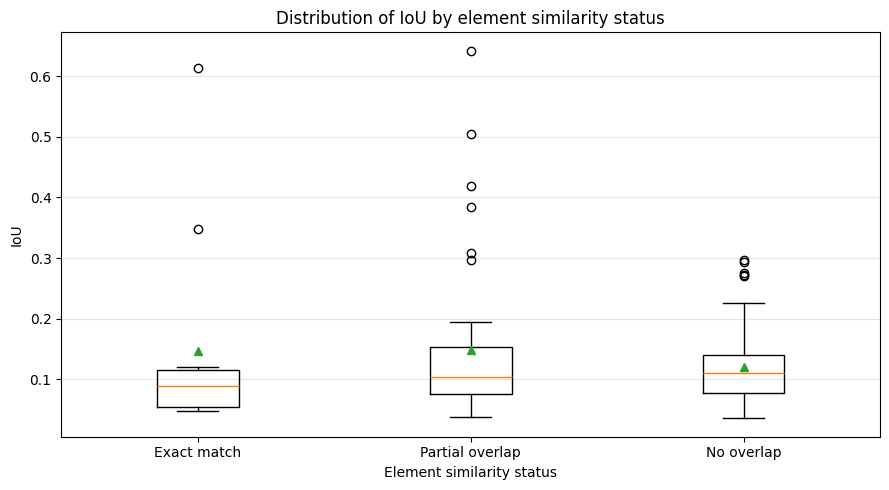


КРИТЕРИЙ КРАСКЕЛА — УОЛЛИСА
H statistic: 1.20433
p-value: 0.547624
Epsilon squared: 0.00000
Результат: статистически значимых различий распределений IoU между группами не обнаружено.

ПОПАРНЫЕ СРАВНЕНИЯ МАННА — УИТНИ


,group_1,group_2,n_1,n_2,U_statistic,p_uncorrected,p_holm,significant_after_holm
0,exact_match,partial_overlap,12,40,205.5,0.460242,0.920484,False
1,exact_match,no_overlap,12,73,342.0,0.228090,0.684270,False
2,partial_overlap,no_overlap,40,73,1455.0,0.978445,0.978445,False



КОРРЕЛЯЦИЯ СПИРМЕНА: IoU И ELEMENT_JACCARD
Количество пар: 125
Spearman rho: -0.07092
p-value: 0.431882
Результат: статистически значимая ранговая связь не обнаружена.


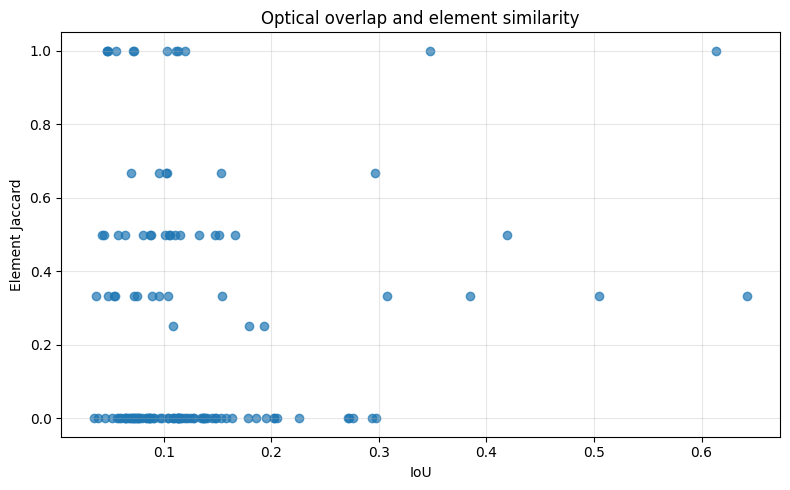


СОХРАНЕНЫ ФАЙЛЫ:
/content/iou_statistics_by_element_status.csv
/content/iou_pairwise_tests.csv
/content/iou_jaccard_analysis_data.csv


In [44]:

# ============================================================
# СВЯЗЬ ОПТИЧЕСКОГО СХОДСТВА (IoU)
# И СОВПАДЕНИЯ СОСТАВА ЭЛЕМЕНТОВ
# Анализ 125 пар с motor_match_type == "definite"
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal, mannwhitneyu
from itertools import combinations

# ------------------------------------------------------------
# 1. Подготовка данных
# ------------------------------------------------------------

analysis_df = algorithm_2_normalized.copy()

analysis_df["IoU"] = pd.to_numeric(
    analysis_df["IoU"], errors="coerce"
)

analysis_df["element_jaccard"] = pd.to_numeric(
    analysis_df["element_jaccard"], errors="coerce"
)

status_order = [
    "exact_match",
    "partial_overlap",
    "no_overlap"
]

analysis_df = analysis_df[
    analysis_df["element_status"].isin(status_order)
].copy()

print("ОБЪЁМ ДАННЫХ")
print("Всего моторных пар:", len(algorithm_2_normalized))
print("Пар после отбора по статусу:", len(analysis_df))
print("Пропуски IoU:", analysis_df["IoU"].isna().sum())
print("Пропуски Jaccard:", analysis_df["element_jaccard"].isna().sum())

# Для анализа IoU используем только строки с известным IoU
iou_df = analysis_df.dropna(subset=["IoU"]).copy()

# ------------------------------------------------------------
# 2. Описательная статистика IoU по группам
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА IoU ПО ГРУППАМ")
print("=" * 70)

iou_stats = (
    iou_df.groupby("element_status")["IoU"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        median="median",
        min="min",
        max="max"
    )
    .reindex(status_order)
)

display(iou_stats.round(5))

# ------------------------------------------------------------
# 3. График распределения IoU
# ------------------------------------------------------------

groups = [
    iou_df.loc[iou_df["element_status"] == status, "IoU"].values
    for status in status_order
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    groups,
    tick_labels=[
        "Exact match",
        "Partial overlap",
        "No overlap"
    ],
    showmeans=True
)

plt.ylabel("IoU")
plt.xlabel("Element similarity status")
plt.title("Distribution of IoU by element similarity status")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Критерий Краскела — Уоллиса
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("КРИТЕРИЙ КРАСКЕЛА — УОЛЛИСА")
print("=" * 70)

nonempty_groups = [group for group in groups if len(group) > 0]

if len(nonempty_groups) == 3:
    kw_stat, kw_p = kruskal(*nonempty_groups)

    n = sum(len(group) for group in nonempty_groups)
    k = len(nonempty_groups)

    # Оценка размера эффекта epsilon squared
    epsilon_squared = (
        kw_stat - k + 1
    ) / (n - k)

    epsilon_squared = max(0, epsilon_squared)

    print(f"H statistic: {kw_stat:.5f}")
    print(f"p-value: {kw_p:.6f}")
    print(f"Epsilon squared: {epsilon_squared:.5f}")

    if kw_p < 0.05:
        print(
            "Результат: обнаружены статистически значимые "
            "различия распределений IoU между группами."
        )
    else:
        print(
            "Результат: статистически значимых различий "
            "распределений IoU между группами не обнаружено."
        )
else:
    print("Недостаточно непустых групп для критерия.")

# ------------------------------------------------------------
# 5. Попарные сравнения Манна — Уитни
#    с поправкой Холма на множественные проверки
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ПОПАРНЫЕ СРАВНЕНИЯ МАННА — УИТНИ")
print("=" * 70)

pairwise_results = []

for status_a, status_b in combinations(status_order, 2):

    values_a = iou_df.loc[
        iou_df["element_status"] == status_a, "IoU"
    ].dropna()

    values_b = iou_df.loc[
        iou_df["element_status"] == status_b, "IoU"
    ].dropna()

    if len(values_a) > 0 and len(values_b) > 0:
        statistic, p_value = mannwhitneyu(
            values_a,
            values_b,
            alternative="two-sided"
        )

        pairwise_results.append({
            "group_1": status_a,
            "group_2": status_b,
            "n_1": len(values_a),
            "n_2": len(values_b),
            "U_statistic": statistic,
            "p_uncorrected": p_value
        })

pairwise_df = pd.DataFrame(pairwise_results)

# Поправка Холма
if not pairwise_df.empty:
    p_values = pairwise_df["p_uncorrected"].values
    m = len(p_values)

    sorted_indices = np.argsort(p_values)
    adjusted = np.empty(m)

    running_max = 0

    for rank, idx in enumerate(sorted_indices):
        corrected = (m - rank) * p_values[idx]
        running_max = max(running_max, corrected)
        adjusted[idx] = min(running_max, 1.0)

    pairwise_df["p_holm"] = adjusted
    pairwise_df["significant_after_holm"] = (
        pairwise_df["p_holm"] < 0.05
    )

display(pairwise_df.round(6))

# ------------------------------------------------------------
# 6. Корреляция IoU и Jaccard
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("КОРРЕЛЯЦИЯ СПИРМЕНА: IoU И ELEMENT_JACCARD")
print("=" * 70)

corr_df = analysis_df.dropna(
    subset=["IoU", "element_jaccard"]
).copy()

if (
    len(corr_df) >= 3
    and corr_df["IoU"].nunique() > 1
    and corr_df["element_jaccard"].nunique() > 1
):
    rho, p_corr = spearmanr(
        corr_df["IoU"],
        corr_df["element_jaccard"]
    )

    print("Количество пар:", len(corr_df))
    print(f"Spearman rho: {rho:.5f}")
    print(f"p-value: {p_corr:.6f}")

    if p_corr < 0.05:
        print(
            "Результат: обнаружена статистически значимая "
            "ранговая связь между IoU и Jaccard."
        )
    else:
        print(
            "Результат: статистически значимая "
            "ранговая связь не обнаружена."
        )
else:
    print("Недостаточно вариативности или наблюдений.")

# ------------------------------------------------------------
# 7. График IoU и Jaccard
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    corr_df["IoU"],
    corr_df["element_jaccard"],
    alpha=0.7
)

plt.xlabel("IoU")
plt.ylabel("Element Jaccard")
plt.title("Optical overlap and element similarity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Сохранение результатов
# ------------------------------------------------------------

iou_stats.to_csv(
    "/content/iou_statistics_by_element_status.csv",
    encoding="utf-8-sig"
)

pairwise_df.to_csv(
    "/content/iou_pairwise_tests.csv",
    index=False,
    encoding="utf-8-sig"
)

corr_df.to_csv(
    "/content/iou_jaccard_analysis_data.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nСОХРАНЕНЫ ФАЙЛЫ:")
print("/content/iou_statistics_by_element_status.csv")
print("/content/iou_pairwise_tests.csv")
print("/content/iou_jaccard_analysis_data.csv")


Размер выборки: 125

Размеры групп:
element_status
exact_match        12
partial_overlap    40
no_overlap         73
Name: count, dtype: int64

95% BOOTSTRAP CONFIDENCE INTERVALS


,element_status,n,mean_IoU,mean_CI_lower,mean_CI_upper,median_IoU,median_CI_lower,median_CI_upper
0,exact_match,12,0.14589,0.07315,0.25075,0.08796,0.05174,0.11660
1,partial_overlap,40,0.14858,0.11226,0.19211,0.10361,0.08912,0.12412
2,no_overlap,73,0.12072,0.10752,0.13535,0.11052,0.09013,0.11949


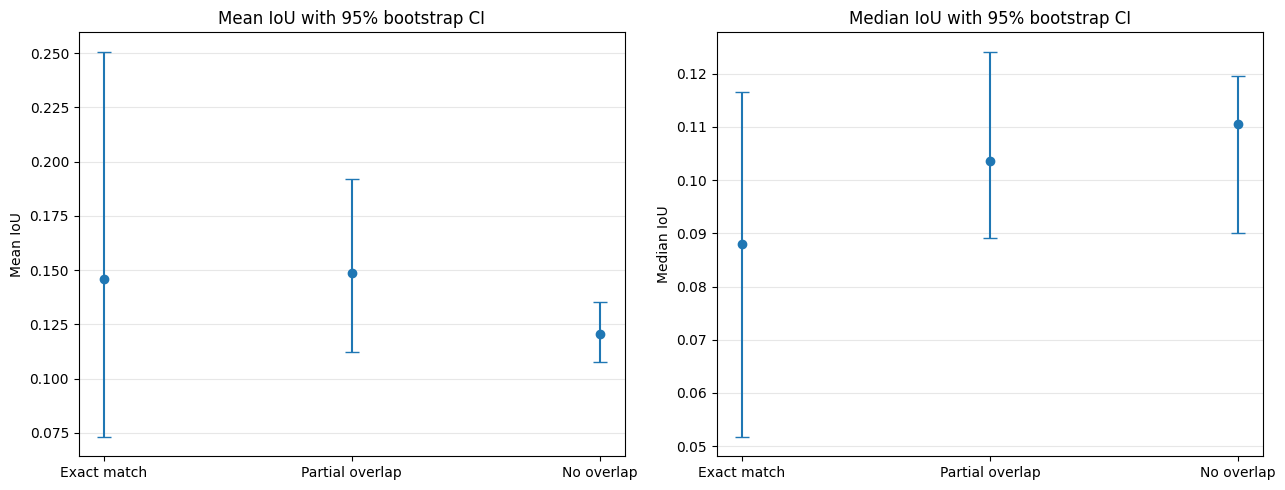


PERMUTATION TEST: SPEARMAN CORRELATION
Количество пар: 125
Количество перестановок: 10000
Observed Spearman rho: -0.070924
Original Spearman p-value: 0.431882
Permutation p-value: 0.425957

Результат: перестановочный тест не обнаруживает статистически значимую связь.


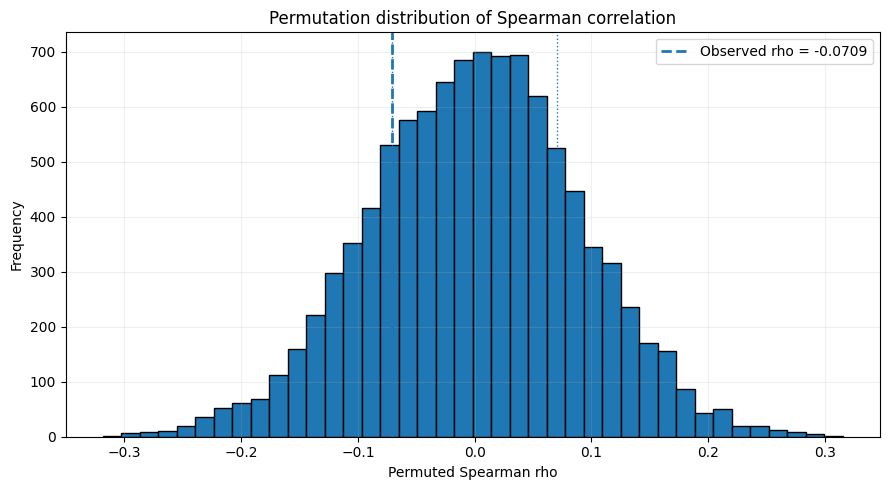


СОХРАНЕНЫ ФАЙЛЫ:
/content/bootstrap_confidence_intervals.csv
/content/permutation_spearman_results.csv


In [45]:

# ============================================================
# ДОПОЛНИТЕЛЬНАЯ СТАТИСТИЧЕСКАЯ ПРОВЕРКА
#
# 1. Bootstrap CI для среднего и медианы IoU
# 2. Перестановочный тест корреляции Спирмена
#
# Выборка: 125 пар Algorithm 2 (motor_match_type == definite)
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Подготовка данных
# ------------------------------------------------------------

df = algorithm_2_normalized.copy()

df["IoU"] = pd.to_numeric(df["IoU"], errors="coerce")
df["element_jaccard"] = pd.to_numeric(
    df["element_jaccard"], errors="coerce"
)

df = df.dropna(
    subset=["IoU", "element_jaccard", "element_status"]
).copy()

status_order = [
    "exact_match",
    "partial_overlap",
    "no_overlap"
]

print("Размер выборки:", len(df))
print("\nРазмеры групп:")
print(df["element_status"].value_counts().reindex(status_order))


# ============================================================
# 2. BOOTSTRAP: ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ
# ============================================================

N_BOOTSTRAP = 10000
CONFIDENCE = 0.95

rng = np.random.default_rng(42)

bootstrap_results = []

for status in status_order:

    values = df.loc[
        df["element_status"] == status,
        "IoU"
    ].to_numpy()

    n = len(values)

    bootstrap_means = np.empty(N_BOOTSTRAP)
    bootstrap_medians = np.empty(N_BOOTSTRAP)

    for i in range(N_BOOTSTRAP):

        sample = rng.choice(
            values,
            size=n,
            replace=True
        )

        bootstrap_means[i] = np.mean(sample)
        bootstrap_medians[i] = np.median(sample)

    alpha = 1 - CONFIDENCE

    mean_ci = np.quantile(
        bootstrap_means,
        [alpha / 2, 1 - alpha / 2]
    )

    median_ci = np.quantile(
        bootstrap_medians,
        [alpha / 2, 1 - alpha / 2]
    )

    bootstrap_results.append({
        "element_status": status,
        "n": n,

        "mean_IoU": np.mean(values),
        "mean_CI_lower": mean_ci[0],
        "mean_CI_upper": mean_ci[1],

        "median_IoU": np.median(values),
        "median_CI_lower": median_ci[0],
        "median_CI_upper": median_ci[1]
    })

bootstrap_ci_df = pd.DataFrame(bootstrap_results)

print("\n" + "=" * 75)
print("95% BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 75)

display(bootstrap_ci_df.round(5))


# ============================================================
# 3. ВИЗУАЛИЗАЦИЯ ДОВЕРИТЕЛЬНЫХ ИНТЕРВАЛОВ
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

labels = [
    "Exact match",
    "Partial overlap",
    "No overlap"
]

x = np.arange(len(status_order))

# Средние значения
means = bootstrap_ci_df["mean_IoU"].to_numpy()
mean_lower = bootstrap_ci_df["mean_CI_lower"].to_numpy()
mean_upper = bootstrap_ci_df["mean_CI_upper"].to_numpy()

axes[0].errorbar(
    x,
    means,
    yerr=[
        means - mean_lower,
        mean_upper - means
    ],
    fmt="o",
    capsize=5
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Mean IoU")
axes[0].set_title("Mean IoU with 95% bootstrap CI")
axes[0].grid(axis="y", alpha=0.3)

# Медианы
medians = bootstrap_ci_df["median_IoU"].to_numpy()
median_lower = bootstrap_ci_df["median_CI_lower"].to_numpy()
median_upper = bootstrap_ci_df["median_CI_upper"].to_numpy()

axes[1].errorbar(
    x,
    medians,
    yerr=[
        medians - median_lower,
        median_upper - medians
    ],
    fmt="o",
    capsize=5
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Median IoU")
axes[1].set_title("Median IoU with 95% bootstrap CI")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 4. ПЕРЕСТАНОВОЧНЫЙ ТЕСТ КОРРЕЛЯЦИИ СПИРМЕНА
# ============================================================

x_iou = df["IoU"].to_numpy()
y_jaccard = df["element_jaccard"].to_numpy()

observed_rho, observed_p = spearmanr(
    x_iou,
    y_jaccard
)

N_PERMUTATIONS = 10000

rng_perm = np.random.default_rng(42)

permuted_rhos = np.empty(N_PERMUTATIONS)

for i in range(N_PERMUTATIONS):

    shuffled_jaccard = rng_perm.permutation(y_jaccard)

    permuted_rhos[i] = spearmanr(
        x_iou,
        shuffled_jaccard
    ).statistic

# Двусторонний перестановочный p-value
# Поправка +1 предотвращает нулевое значение p-value

permutation_p = (
    1 + np.sum(
        np.abs(permuted_rhos) >= abs(observed_rho)
    )
) / (N_PERMUTATIONS + 1)

print("\n" + "=" * 75)
print("PERMUTATION TEST: SPEARMAN CORRELATION")
print("=" * 75)

print("Количество пар:", len(df))
print("Количество перестановок:", N_PERMUTATIONS)
print(f"Observed Spearman rho: {observed_rho:.6f}")
print(f"Original Spearman p-value: {observed_p:.6f}")
print(f"Permutation p-value: {permutation_p:.6f}")

if permutation_p < 0.05:
    print(
        "\nРезультат: перестановочный тест обнаруживает "
        "статистически значимую связь."
    )
else:
    print(
        "\nРезультат: перестановочный тест не обнаруживает "
        "статистически значимую связь."
    )


# ============================================================
# 5. РАСПРЕДЕЛЕНИЕ ПЕРЕСТАНОВОЧНЫХ КОЭФФИЦИЕНТОВ
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    permuted_rhos,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    observed_rho,
    linestyle="--",
    linewidth=2,
    label=f"Observed rho = {observed_rho:.4f}"
)

plt.axvline(
    -abs(observed_rho),
    linestyle=":",
    linewidth=1
)

plt.axvline(
    abs(observed_rho),
    linestyle=":",
    linewidth=1
)

plt.xlabel("Permuted Spearman rho")
plt.ylabel("Frequency")
plt.title("Permutation distribution of Spearman correlation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ============================================================
# 6. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

bootstrap_ci_df.to_csv(
    "/content/bootstrap_confidence_intervals.csv",
    index=False,
    encoding="utf-8-sig"
)

permutation_results_df = pd.DataFrame([{
    "n": len(df),
    "n_permutations": N_PERMUTATIONS,
    "observed_spearman_rho": observed_rho,
    "original_spearman_p": observed_p,
    "permutation_p": permutation_p
}])

permutation_results_df.to_csv(
    "/content/permutation_spearman_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nСОХРАНЕНЫ ФАЙЛЫ:")
print("/content/bootstrap_confidence_intervals.csv")
print("/content/permutation_spearman_results.csv")


In [46]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from itertools import combinations
from IPython.display import display

# ============================================================
# 1. ПОДГОТОВКА ДАННЫХ
# ============================================================

df = algorithm_2_normalized.copy()

required_columns = [
    "case", "letter_1", "letter_2",
    "IoU", "element_jaccard", "element_status"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"В таблице отсутствуют столбцы: {missing_columns}")

df["IoU"] = pd.to_numeric(df["IoU"], errors="coerce")
df["element_jaccard"] = pd.to_numeric(
    df["element_jaccard"], errors="coerce"
)

df = df.dropna(subset=required_columns).copy()

status_order = [
    "exact_match",
    "partial_overlap",
    "no_overlap"
]

df = df[df["element_status"].isin(status_order)].copy()
df = df.reset_index(drop=True)

print("Размер выборки:", len(df))
print("\nРаспределение групп:")
print(df["element_status"].value_counts().reindex(status_order))

# Каждая буква в каждом регистре считается отдельным узлом.
# Например, lower-А и upper-А — разные узлы.

df["node_1"] = list(zip(df["case"], df["letter_1"]))
df["node_2"] = list(zip(df["case"], df["letter_2"]))

# Проверяем, что в таблице нет повторяющихся пар.
pair_keys = df.apply(
    lambda r: (
        r["case"],
        *sorted([r["letter_1"], r["letter_2"]])
    ),
    axis=1
)

if pair_keys.duplicated().any():
    raise ValueError(
        "Обнаружены повторяющиеся пары букв. "
        "Перед bootstrap необходимо разобраться с дубликатами."
    )

# ============================================================
# 2. ФОРМИРУЕМ СОВОКУПНОСТИ БУКВ ДЛЯ РЕСЕМПЛИРОВАНИЯ
# ============================================================

nodes_by_case = {}

for case_value in df["case"].unique():
    nodes = set()

    subset = df[df["case"] == case_value]

    for node in subset["node_1"]:
        nodes.add(node)

    for node in subset["node_2"]:
        nodes.add(node)

    nodes_by_case[case_value] = sorted(nodes)

print("\nКоличество узлов по регистрам:")

for case_value, nodes in nodes_by_case.items():
    print(f"{case_value}: {len(nodes)} букв")

# ============================================================
# 3. ФУНКЦИЯ ВЗВЕШЕННОЙ МЕДИАНЫ
# ============================================================

def weighted_median(values, weights):
    values = np.asarray(values)
    weights = np.asarray(weights)

    valid = weights > 0
    values = values[valid]
    weights = weights[valid]

    if len(values) == 0:
        return np.nan

    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    cumulative_weights = np.cumsum(weights)
    cutoff = weights.sum() / 2

    index = np.searchsorted(
        cumulative_weights,
        cutoff,
        side="left"
    )

    return float(values[index])

# ============================================================
# 4. НАСТРОЙКИ BOOTSTRAP
# ============================================================

N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

n_rows = len(df)

bootstrap_means = {
    status: [] for status in status_order
}

bootstrap_medians = {
    status: [] for status in status_order
}

bootstrap_differences = {
    (a, b): [] for a, b in combinations(status_order, 2)
}

bootstrap_rhos = []

# ============================================================
# 5. КЛАСТЕРНЫЙ BOOTSTRAP НА УРОВНЕ БУКВ
# ============================================================

for iteration in range(N_BOOTSTRAP):

    # Сколько раз каждый узел попал в bootstrap-выборку
    node_counts = {}

    for case_value, nodes in nodes_by_case.items():

        sampled_nodes = rng.choice(
            len(nodes),
            size=len(nodes),
            replace=True
        )

        counts = np.bincount(
            sampled_nodes,
            minlength=len(nodes)
        )

        for node, count in zip(nodes, counts):
            node_counts[node] = int(count)

    # Вес каждой пары = произведение частот двух её букв
    weights = np.array([
        node_counts[node_1] * node_counts[node_2]
        for node_1, node_2 in zip(df["node_1"], df["node_2"])
    ])

    if weights.sum() == 0:
        continue

    # --------------------------------------------------------
    # 5.1. Средние и медианы IoU по группам
    # --------------------------------------------------------

    replicate_means = {}

    for status in status_order:

        mask = (
            df["element_status"].to_numpy() == status
        )

        values = df.loc[mask, "IoU"].to_numpy()
        group_weights = weights[mask]

        valid = group_weights > 0

        values = values[valid]
        group_weights = group_weights[valid]

        if len(values) == 0:
            replicate_means[status] = np.nan
            bootstrap_means[status].append(np.nan)
            bootstrap_medians[status].append(np.nan)
            continue

        mean_value = np.average(
            values,
            weights=group_weights
        )

        median_value = weighted_median(
            values,
            group_weights
        )

        replicate_means[status] = mean_value

        bootstrap_means[status].append(mean_value)
        bootstrap_medians[status].append(median_value)

    # --------------------------------------------------------
    # 5.2. Разности средних IoU между группами
    # --------------------------------------------------------

    for a, b in combinations(status_order, 2):

        mean_a = replicate_means[a]
        mean_b = replicate_means[b]

        if np.isfinite(mean_a) and np.isfinite(mean_b):

            bootstrap_differences[(a, b)].append(
                mean_a - mean_b
            )
        else:
            bootstrap_differences[(a, b)].append(np.nan)

    # --------------------------------------------------------
    # 5.3. Взвешенная корреляция Спирмена
    # --------------------------------------------------------

    valid = weights > 0

    x = df.loc[valid, "IoU"].to_numpy()
    y = df.loc[valid, "element_jaccard"].to_numpy()
    w = weights[valid]

    # Повторяем наблюдения в соответствии с их bootstrap-весами.
    x_expanded = np.repeat(x, w)
    y_expanded = np.repeat(y, w)

    if (
        len(x_expanded) > 1
        and np.unique(x_expanded).size > 1
        and np.unique(y_expanded).size > 1
    ):

        rho = spearmanr(
            x_expanded,
            y_expanded
        ).statistic

        bootstrap_rhos.append(rho)

    else:
        bootstrap_rhos.append(np.nan)


# ============================================================
# 6. 95% ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ
# ============================================================

def get_ci(values):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    return (
        np.percentile(values, 2.5),
        np.percentile(values, 97.5)
    )


# ------------------------------------------------------------
# 6.1. Средние и медианы
# ------------------------------------------------------------

cluster_results = []

for status in status_order:

    mean_ci = get_ci(bootstrap_means[status])
    median_ci = get_ci(bootstrap_medians[status])

    original_group = df[df["element_status"] == status]

    cluster_results.append({
        "element_status": status,
        "n": len(original_group),

        "mean_IoU": original_group["IoU"].mean(),
        "cluster_mean_CI_lower": mean_ci[0],
        "cluster_mean_CI_upper": mean_ci[1],

        "median_IoU": original_group["IoU"].median(),
        "cluster_median_CI_lower": median_ci[0],
        "cluster_median_CI_upper": median_ci[1]
    })

cluster_ci_df = pd.DataFrame(cluster_results)

print("\n" + "=" * 75)
print("CLUSTER BOOTSTRAP: 95% CONFIDENCE INTERVALS")
print("=" * 75)

display(
    cluster_ci_df.round(5)
)


# ------------------------------------------------------------
# 6.2. Разности средних между группами
# ------------------------------------------------------------

difference_results = []

for (a, b), values in bootstrap_differences.items():

    original_mean_a = df.loc[
        df["element_status"] == a, "IoU"
    ].mean()

    original_mean_b = df.loc[
        df["element_status"] == b, "IoU"
    ].mean()

    ci_lower, ci_upper = get_ci(values)

    difference_results.append({
        "comparison": f"{a} - {b}",
        "observed_mean_difference": original_mean_a - original_mean_b,
        "CI_lower": ci_lower,
        "CI_upper": ci_upper
    })

cluster_differences_df = pd.DataFrame(
    difference_results
)

print("\n" + "=" * 75)
print("CLUSTER BOOTSTRAP: DIFFERENCES BETWEEN GROUP MEANS")
print("=" * 75)

display(
    cluster_differences_df.round(5)
)


# ------------------------------------------------------------
# 6.3. Корреляция Спирмена
# ------------------------------------------------------------

observed_rho = spearmanr(
    df["IoU"],
    df["element_jaccard"]
).statistic

rho_ci = get_ci(bootstrap_rhos)

print("\n" + "=" * 75)
print("CLUSTER BOOTSTRAP: SPEARMAN CORRELATION")
print("=" * 75)

print(f"Observed Spearman rho: {observed_rho:.6f}")
print(f"Cluster bootstrap 95% CI: [{rho_ci[0]:.6f}; {rho_ci[1]:.6f}]")
print(
    "Valid bootstrap correlations:",
    np.isfinite(bootstrap_rhos).sum()
)


# ============================================================
# 7. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

cluster_ci_df.to_csv(
    "/content/cluster_bootstrap_group_intervals.csv",
    index=False
)

cluster_differences_df.to_csv(
    "/content/cluster_bootstrap_mean_differences.csv",
    index=False
)

pd.DataFrame({
    "bootstrap_rho": bootstrap_rhos
}).to_csv(
    "/content/cluster_bootstrap_spearman.csv",
    index=False
)

print("\nФайлы сохранены:")
print("/content/cluster_bootstrap_group_intervals.csv")
print("/content/cluster_bootstrap_mean_differences.csv")
print("/content/cluster_bootstrap_spearman.csv")



Размер выборки: 125

Распределение групп:
element_status
exact_match        12
partial_overlap    40
no_overlap         73
Name: count, dtype: int64

Количество узлов по регистрам:
lower: 23 букв
upper: 26 букв

CLUSTER BOOTSTRAP: 95% CONFIDENCE INTERVALS


,element_status,n,mean_IoU,cluster_mean_CI_lower,cluster_mean_CI_upper,median_IoU,cluster_median_CI_lower,cluster_median_CI_upper
0,exact_match,12,0.14589,0.05944,0.35057,0.08796,0.04759,0.34778
1,partial_overlap,40,0.14858,0.09180,0.23553,0.10361,0.06405,0.15402
2,no_overlap,73,0.12072,0.10069,0.15014,0.11052,0.08477,0.13739



CLUSTER BOOTSTRAP: DIFFERENCES BETWEEN GROUP MEANS


,comparison,observed_mean_difference,CI_lower,CI_upper
0,exact_match - partial_overlap,-0.00269,-0.13231,0.20860
1,exact_match - no_overlap,0.02517,-0.06719,0.23051
2,partial_overlap - no_overlap,0.02786,-0.03565,0.11575



CLUSTER BOOTSTRAP: SPEARMAN CORRELATION
Observed Spearman rho: -0.070924
Cluster bootstrap 95% CI: [-0.348439; 0.221937]
Valid bootstrap correlations: 10000

Файлы сохранены:
/content/cluster_bootstrap_group_intervals.csv
/content/cluster_bootstrap_mean_differences.csv
/content/cluster_bootstrap_spearman.csv


Количество пар: 125

Количество букв по регистрам:
lower 23
upper 26

Максимальное расхождение исходного и пересчитанного Jaccard:
0.0

Наблюдаемая корреляция Спирмена:
rho = -0.070924

NODE-LABEL PERMUTATION TEST
Количество перестановок: 10000
Количество валидных перестановок: 10000
Observed Spearman rho: -0.070924
Permutation p-value: 0.428657

Результат: статистически значимая связь не обнаружена.


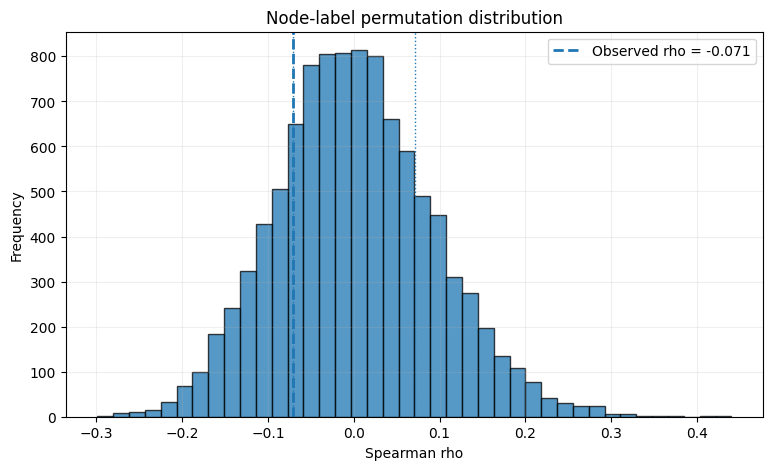


Сохранены файлы:
/content/node_label_permutation_results.csv
/content/node_label_permutation_distribution.csv


In [47]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from IPython.display import display

# ============================================================
# 1. ПОДГОТОВКА И ПРОВЕРКА ДАННЫХ
# ============================================================

pairs = algorithm_2_normalized.copy()
elements = letter_elements_normalized_df.copy()

pairs["IoU"] = pd.to_numeric(pairs["IoU"], errors="coerce")
pairs["element_jaccard"] = pd.to_numeric(
    pairs["element_jaccard"], errors="coerce"
)

pairs = pairs.dropna(
    subset=["case", "letter_1", "letter_2", "IoU", "element_jaccard"]
).copy()

# Набор элементов каждой буквы.
# Ключ: (регистр, буква).
element_sets = {}

for (case_value, letter), group in elements.groupby(
    ["case", "letter"]
):
    element_sets[(case_value, letter)] = set(
        group["element_normalized"].dropna().astype(str)
    )

# Узлы, участвующие в 125 парах.
nodes_by_case = {}

for case_value in pairs["case"].unique():

    subset = pairs[pairs["case"] == case_value]

    nodes = set(subset["letter_1"]) | set(subset["letter_2"])

    nodes_by_case[case_value] = sorted(nodes)

# Проверяем наличие описаний для каждой буквы.
missing_nodes = []

for case_value, nodes in nodes_by_case.items():
    for letter in nodes:
        key = (case_value, letter)

        if key not in element_sets or len(element_sets[key]) == 0:
            missing_nodes.append(key)

if missing_nodes:
    raise ValueError(
        "Не найдены описания элементов для следующих букв:\n"
        + str(missing_nodes)
    )

print("Количество пар:", len(pairs))

print("\nКоличество букв по регистрам:")
for case_value, nodes in nodes_by_case.items():
    print(case_value, len(nodes))

# ============================================================
# 2. ФУНКЦИЯ JACCARD
# ============================================================

def calculate_jaccard(set_a, set_b):

    union = set_a | set_b

    if len(union) == 0:
        return np.nan

    return len(set_a & set_b) / len(union)


# ============================================================
# 3. ПЕРЕСЧЁТ ИСХОДНЫХ JACCARD
# ============================================================

recalculated_jaccard = []

for _, row in pairs.iterrows():

    set_1 = element_sets[(row["case"], row["letter_1"])]
    set_2 = element_sets[(row["case"], row["letter_2"])]

    recalculated_jaccard.append(
        calculate_jaccard(set_1, set_2)
    )

pairs["recalculated_jaccard"] = recalculated_jaccard

max_difference = np.max(
    np.abs(
        pairs["element_jaccard"].to_numpy()
        - pairs["recalculated_jaccard"].to_numpy()
    )
)

print("\nМаксимальное расхождение исходного и пересчитанного Jaccard:")
print(max_difference)

if not np.allclose(
    pairs["element_jaccard"],
    pairs["recalculated_jaccard"],
    atol=1e-8
):
    raise ValueError(
        "Пересчитанный Jaccard не совпадает с исходным. "
        "Проверьте источник описаний и нормализацию."
    )

# ============================================================
# 4. НАБЛЮДАЕМАЯ КОРРЕЛЯЦИЯ
# ============================================================

x = pairs["IoU"].to_numpy()
y = pairs["recalculated_jaccard"].to_numpy()

observed_rho = spearmanr(x, y).statistic

print("\nНаблюдаемая корреляция Спирмена:")
print(f"rho = {observed_rho:.6f}")

# ============================================================
# 5. УЗЛОВЫЕ ПЕРЕСТАНОВКИ
# ============================================================

N_PERMUTATIONS = 10000
rng = np.random.default_rng(42)

permuted_rhos = []
permuted_jaccards = []

# Фиксируем список букв и их профили для каждого регистра.
# При перестановке профили целиком переназначаются буквам.

profiles_by_case = {}

for case_value, nodes in nodes_by_case.items():

    profiles_by_case[case_value] = [
        element_sets[(case_value, letter)]
        for letter in nodes
    ]

# Индексы букв внутри каждого регистра.
node_indices = {
    case_value: {
        letter: i
        for i, letter in enumerate(nodes)
    }
    for case_value, nodes in nodes_by_case.items()
}

# Индексы концов каждой пары.
edge_indices = []

for _, row in pairs.iterrows():

    case_value = row["case"]

    i = node_indices[case_value][row["letter_1"]]
    j = node_indices[case_value][row["letter_2"]]

    edge_indices.append((case_value, i, j))

# Выполняем перестановки.
for iteration in range(N_PERMUTATIONS):

    # Случайное переназначение профилей буквам
    # отдельно для каждого регистра.
    permuted_profiles = {}

    for case_value, nodes in nodes_by_case.items():

        permutation = rng.permutation(len(nodes))

        original_profiles = profiles_by_case[case_value]

        permuted_profiles[case_value] = [
            original_profiles[k] for k in permutation
        ]

    # Пересчитываем Jaccard для исходных пар.
    current_jaccards = []

    for case_value, i, j in edge_indices:

        set_1 = permuted_profiles[case_value][i]
        set_2 = permuted_profiles[case_value][j]

        current_jaccards.append(
            calculate_jaccard(set_1, set_2)
        )

    current_jaccards = np.asarray(current_jaccards)

    # Корреляция с неизменными значениями IoU.
    rho = spearmanr(
        x,
        current_jaccards
    ).statistic

    permuted_rhos.append(rho)
    permuted_jaccards.append(current_jaccards)

permuted_rhos = np.asarray(permuted_rhos)

# ============================================================
# 6. ПЕРЕСТАНОВОЧНЫЙ P-VALUE
# ============================================================

valid_rhos = permuted_rhos[np.isfinite(permuted_rhos)]

extreme_count = np.sum(
    np.abs(valid_rhos) >= abs(observed_rho)
)

permutation_p = (
    1 + extreme_count
) / (
    1 + len(valid_rhos)
)

print("\n" + "=" * 70)
print("NODE-LABEL PERMUTATION TEST")
print("=" * 70)

print("Количество перестановок:", N_PERMUTATIONS)
print("Количество валидных перестановок:", len(valid_rhos))
print(f"Observed Spearman rho: {observed_rho:.6f}")
print(f"Permutation p-value: {permutation_p:.6f}")

if permutation_p < 0.05:
    print("\nРезультат: обнаружена статистически значимая связь.")
else:
    print("\nРезультат: статистически значимая связь не обнаружена.")

# ============================================================
# 7. ВИЗУАЛИЗАЦИЯ
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    valid_rhos,
    bins=40,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    observed_rho,
    linestyle="--",
    linewidth=2,
    label=f"Observed rho = {observed_rho:.3f}"
)

plt.axvline(
    -abs(observed_rho),
    linestyle=":",
    linewidth=1
)

plt.axvline(
    abs(observed_rho),
    linestyle=":",
    linewidth=1
)

plt.xlabel("Spearman rho")
plt.ylabel("Frequency")
plt.title("Node-label permutation distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# ============================================================
# 8. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

permutation_results_df = pd.DataFrame({
    "observed_rho": [observed_rho],
    "permutation_p_value": [permutation_p],
    "n_permutations": [N_PERMUTATIONS],
    "valid_permutations": [len(valid_rhos)],
    "extreme_count": [extreme_count]
})

permutation_distribution_df = pd.DataFrame({
    "permuted_rho": valid_rhos
})

permutation_results_df.to_csv(
    "/content/node_label_permutation_results.csv",
    index=False
)

permutation_distribution_df.to_csv(
    "/content/node_label_permutation_distribution.csv",
    index=False
)

print("\nСохранены файлы:")
print("/content/node_label_permutation_results.csv")
print("/content/node_label_permutation_distribution.csv")
